# Data Engineering & Visualization – Milestone 1
**Housing & Development × Transportation in New York City**

**Team**

| Member | ID | Research questions |
|---|---|---|
| Yassin Amr Hegazy | 16001061 | Section 7.4 |
| Mohammed Fady Rizk | 16008623 | Section 7.5 |
| Sam Shady Samih Soliman Bostawros | 16004357 | Section 7.6 |
| Marawan Mohamed Elgendy | 16001322 | Section 7.7 |
| Amro Taha Salih | 16007093 | Section 7.8 |
| Fares Mustafa El-Sonbaty | 16006173 | Section 7.9 |

**Course:** Data Engineering and Visualization, Winter 2026 – GIU

## Notebook outline
1. Research question
2. Datasets and selection reasoning
3. Exploratory data analysis (EDA)
4. Scope decisions
5. Pre-integration cleaning
6. Integration
7. Post-integration cleaning and analysis
   - 7.4-7.9 Individual research questions (two per member, each with its own visualization)
   - 7.10 Data story: what the questions show together
8. Contributions and prompts used
9. Interactive website

**Task scope:** Sections 1-7.3 explore, clean, merge and check the shared data. Sections 7.4-7.9 hold each member's individual research questions, all built on the same cleaned and integrated outputs, and Section 7.10 brings them together into one answer.

## 1. Research question

> Do neighborhoods experiencing a surge in new affordable-housing construction
> also experience more severe street-safety problems?

**Why it matters.** New affordable housing brings new residents, many of whom walk, cycle or take the bus. If those buildings open in districts with dangerous streets, housing and street-safety agencies need to plan together. **How it is answered.** Sections 2-7.3 explore, clean and join the two datasets at community district × year level. Sections 7.4-7.9 answer twelve research questions (two per member), Section 7.10 combines them into the overall answer, and Section 9 describes the interactive website.

**Measurement limits:** Total Units includes affordable and market-rate units in HPD-recorded buildings; All Counted Units is the counted affordable-unit measure. SIRTA covers its reported/analyzed serious crashes, not all NYC collisions. District-level counts do not measure individual risk or demonstrate causation. A recorded completion date is not a verified occupancy date. Fatal crashes after 2022 have no coordinates in SIRTA, so they cannot be placed in a district; district-level results use serious injuries instead (checked in Section 7.7).

## 2. Datasets and selection reasoning

| Domain | Dataset | ID | Source |
|---|---|---|---|
| Housing & Development (H2) | Affordable Housing Production by Building | hg8x-zxpr | https://data.cityofnewyork.us/d/hg8x-zxpr |
| Transportation (T4) | Serious Injury Response Tracking Application (SIRTA) | xeqp-qz8h | https://data.cityofnewyork.us/d/xeqp-qz8h |

Housing provides project/building counts, construction categories, completion dates and geography. SIRTA provides event dates/times, reported harm, lookbacks and geography. All source columns are retained, so the research questions on bedroom, income and tenure mix (Sections 7.8 and 7.9) can use them.

**Dataset overview** (counts from the full files, checked in Section 3):

| | Housing: Affordable Housing Production by Building | Transportation: SIRTA |
|---|---|---|
| Rows × columns | 9,551 × 41 (one row per building in an HPD project) | 13,754 × 23 (one row per serious-injury or fatal crash) |
| Geographic attributes | Borough, Community Board, Council District, Census Tract (2010), NTA, Postcode, BBL, BIN, latitude/longitude | Crash Borough, Community Board, Council District, Census Tract (2020), NTA (2020), ZipCode, Police Precinct, BBL, BIN, latitude/longitude |
| Temporal attributes | Project Start Date, Project Completion Date, Building Completion Date (2014 to 2026) | Crash Date and Crash Time (2022 to mid-2026) |
| Known issues | 1,949 confidential records have no Building ID, address or coordinates; income and bedroom columns are mostly blank (for example 7,470 blank extremely-low-income cells); the same Building ID can appear in several projects; census/NTA fields use 2010 geography | Community Board is blank for 9,883 records (72%) and coordinates for 2,886; 444 records have no ID, date or outcomes; repeated IDs and exact duplicates exist; 227 crashes are timed exactly 00:00, a likely placeholder |

**Why these two.** Both are on the course catalogue (H2 and T4), both exceed nine columns, and both carry community district and year, so they can be joined without matching individual records. Together they can test whether new affordable housing appears where serious crashes happen. The two files differ in size and detail (buildings vs crashes), so both are aggregated to community district × year before the join (Section 6).

**Supporting lookup:** the official Community District boundaries (DCP, `5crt-au7u`) are used only to find the district of a record from its coordinates. They are a lookup table, not a third dataset.

**Inputs:** to run offline, put `housing.csv`, `transport.csv` and `community_districts_26b.geojson` in an `inputs/` folder next to the notebook. Otherwise the notebook downloads them. All results are written to `outputs/`.

### Setup and plan
1. Explore both files as they are (Section 3).
2. Fix the scope: years, record types and the join level (Section 4).
3. Clean each dataset on its own: formats, missing values, duplicates, inconsistent values, community district and outliers (Section 5).
4. Aggregate each dataset to community district × year and merge them (Section 6).
5. Check the merged table and export it for the research questions and the website (Section 7).

The next cells load the libraries, get the data files and define the column lists and small helper functions used in the cleaning.

In [1]:
from pathlib import Path
import collections, csv, datetime, decimal, functools, json, re, shutil, statistics, time, urllib.request
from types import SimpleNamespace

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

OUTPUT_ROOT = Path.cwd() / "outputs"   # every exported table is written here
INPUT_DIR = Path.cwd() / "inputs"      # optional local copies of the source files
SOURCE_URLS = {
    "raw/housing.csv": "https://data.cityofnewyork.us/api/views/hg8x-zxpr/rows.csv?accessType=DOWNLOAD",
    "raw/transport.csv": "https://data.cityofnewyork.us/api/views/xeqp-qz8h/rows.csv?accessType=DOWNLOAD",
    "reference/community_districts_26b.geojson":
        "https://data.cityofnewyork.us/api/geospatial/5crt-au7u?method=export&format=GeoJSON",
}
for folder in ["raw", "reference", "data", "audits"]:
    (OUTPUT_ROOT / folder).mkdir(parents=True, exist_ok=True)

In [2]:
def get_file(relative_path, url):
    """Use a local copy if one exists, otherwise download the file from NYC Open Data."""
    destination = OUTPUT_ROOT / relative_path
    if destination.is_file() and destination.stat().st_size > 0:
        print("Ready (already downloaded):", relative_path)
        return
    for local_copy in [INPUT_DIR / destination.name, Path.cwd() / destination.name]:
        if local_copy.is_file() and local_copy.stat().st_size > 0:
            shutil.copyfile(local_copy, destination)
            print("Ready (local copy):", relative_path)
            return
    for attempt in range(1, 4):
        try:
            print(f"Downloading {destination.name} (attempt {attempt})")
            with urllib.request.urlopen(url, timeout=60) as response:
                destination.write_bytes(response.read())
            print("Ready:", relative_path)
            return
        except OSError as error:
            print("Download failed:", error)
            time.sleep(2 * attempt)
    raise RuntimeError(f"Could not download {destination.name}. Run this cell again.")


for relative_path, url in SOURCE_URLS.items():
    get_file(relative_path, url)

Ready (local copy): raw/housing.csv
Ready (local copy): raw/transport.csv
Ready (local copy): reference/community_districts_26b.geojson


In [3]:
# Boroughs and the 59 regular community districts (e.g. 408 = Queens district 8)
BORO = {1: "Manhattan", 2: "Bronx", 3: "Brooklyn", 4: "Queens", 5: "Staten Island"}
BORONUM = {name: number for number, name in BORO.items()}
PREFIX = {"MN": 1, "BX": 2, "BK": 3, "QN": 4, "SI": 5}
MAX_DISTRICT = {1: 12, 2: 12, 3: 18, 4: 14, 5: 3}
REGULAR = {100 * b + d for b, maximum in MAX_DISTRICT.items() for d in range(1, maximum + 1)}

START, END = 2022, 2025
YEARS = range(START, END + 1)

# Housing count columns
INCOME = ["Extremely Low Income Units", "Very Low Income Units", "Low Income Units",
          "Moderate Income Units", "Middle Income Units", "Other Income Units"]
BEDROOM = ["Studio Units", "1-BR Units", "2-BR Units", "3-BR Units", "4-BR Units",
           "5-BR Units", "6-BR+ Units", "Unknown-BR Units"]
TENURE = ["Counted Rental Units", "Counted Homeownership Units"]
UNITS = INCOME + BEDROOM + TENURE + ["All Counted Units", "Total Units"]
UNITKEY = dict(zip(UNITS, [
    "extremely_low_income_units", "very_low_income_units", "low_income_units", "moderate_income_units",
    "middle_income_units", "other_income_units", "studio_units", "one_br_units", "two_br_units",
    "three_br_units", "four_br_units", "five_br_units", "six_plus_br_units", "unknown_br_units",
    "rental_units", "homeownership_units", "affordable_units", "total_units"]))

# SIRTA count columns
LOOK = "Similar Fatalities & Severe Injuries (3Y Lookback)"
LOOKALL = "Similar Fatalities & All Injuries (3Y Lookback)"
COUNTS = ["Total Non-Severe Injuries", "Total Severe Injuries", "Total Fatalities", LOOK, LOOKALL]

# Identifier and coordinate columns
HIDS = {"Project ID", "Building ID", "Postcode", "BBL", "BIN", "Council District", "Census Tract"}
TIDS = {"Collision ID", "Crash Police Precinct", "ZipCode", "Community Board", "Council District",
        "Building Identification Number (BIN)", "Borough Block Lot (BBL)", "Census Tract (2020)"}
COORDS = {"Latitude", "Longitude", "Latitude (Internal)", "Longitude (Internal)"}
STREETS = ["Street", "On Street", "Cross Street", "Address", "Highway Reference Marker"]

In [4]:
def load_text_rows(path):
    """Read a CSV as text, exactly as stored (no automatic type guessing)."""
    with Path(path).open(encoding="utf-8-sig", newline="") as f:
        reader = csv.DictReader(f)
        return list(reader), reader.fieldnames


def write_csv(path, rows, fields=None):
    rows = list(rows)
    fields = fields or list(dict.fromkeys(k for r in rows for k in r))
    with Path(path).open("w", encoding="utf-8", newline="") as f:
        writer = csv.DictWriter(f, fieldnames=fields)
        writer.writeheader()
        for r in rows:
            writer.writerow({k: "" if r.get(k) is None else int(r[k]) if isinstance(r[k], bool) else r[k]
                             for k in fields})


def number(text):
    """'12' -> 12, '40.7' -> 40.7, anything else -> None."""
    try:
        value = decimal.Decimal(str(text))
    except (decimal.InvalidOperation, TypeError, ValueError):
        return None
    if not value.is_finite():
        return None
    return int(value) if value == value.to_integral_value() else float(value)


def integer(text):
    value = number(text)
    return value if isinstance(value, int) else None


def as_date(text):
    """'03/15/2024' -> '2024-03-15'."""
    try:
        return datetime.datetime.strptime(text, "%m/%d/%Y").date().isoformat()
    except (TypeError, ValueError):
        return None


def year(iso_date):
    return int(iso_date[:4]) if iso_date else None


def time_value(text):
    """'7:05' -> '07:05'."""
    m = re.fullmatch(r"(\d{1,2}):(\d{2})", text)
    if not m or int(m[1]) > 23 or int(m[2]) > 59:
        return None
    return f"{int(m[1]):02d}:{m[2]}"


def coordinate_pair(row, internal=False):
    lat = row.get("Latitude (Internal)" if internal else "Latitude")
    lon = row.get("Longitude (Internal)" if internal else "Longitude")
    if lat is None or lon is None or (lat == 0 and lon == 0):
        return None, None
    return lon, lat


def percentile(values, p):
    """Linear-interpolation percentile (same as numpy's default)."""
    a = sorted(values)
    if not a:
        return None
    pos = (len(a) - 1) * p
    lo = int(pos)
    hi = min(lo + 1, len(a) - 1)
    return a[lo] + (a[hi] - a[lo]) * (pos - lo)

## 3. Exploratory data analysis (EDA)
### 3.1 Size and first records
Both files are loaded with pandas exactly as published.

In [5]:
housing_df = pd.read_csv(OUTPUT_ROOT / "raw" / "housing.csv", low_memory=False)
crashes_df = pd.read_csv(OUTPUT_ROOT / "raw" / "transport.csv", low_memory=False)

print("Housing:", housing_df.shape)
print("SIRTA crashes:", crashes_df.shape)
print("Cells inspected:", housing_df.size + crashes_df.size)

Housing: (9551, 41)
SIRTA crashes: (13754, 23)
Cells inspected: 707933


In [6]:
housing_df.head()

,Project ID,Project Name,Project Start Date,Project Completion Date,Building ID,Number,Street,Borough,Postcode,BBL,...,2-BR Units,3-BR Units,4-BR Units,5-BR Units,6-BR+ Units,Unknown-BR Units,Counted Rental Units,Counted Homeownership Units,All Counted Units,Total Units
0,68872,177-06 WEXFORD TERRACE,06/30/2026,NaN,991637.0,177-06,WEXFORD TERRACE,Queens,11432.0,4.098350e+09,...,NaN,NaN,NaN,NaN,NaN,NaN,9.0,NaN,9.0,43
1,72436,ST. NICK'S. 819 GRAND STREET,06/30/2026,NaN,1021347.0,819,GRAND STREET,Brooklyn,11211.0,3.029220e+09,...,NaN,NaN,NaN,NaN,NaN,NaN,187.0,NaN,187.0,187
2,72449,BREMOND KING DAVIS.YR15.FY26,06/30/2026,NaN,21199.0,127,EDGECOMBE AVENUE,Manhattan,10030.0,1.020480e+09,...,20.0,NaN,NaN,NaN,NaN,NaN,25.0,NaN,25.0,25
3,72449,BREMOND KING DAVIS.YR15.FY26,06/30/2026,NaN,28145.0,602,ST NICHOLAS AVENUE,Manhattan,10030.0,1.020480e+09,...,5.0,NaN,NaN,NaN,NaN,NaN,16.0,NaN,16.0,16
4,72449,BREMOND KING DAVIS.YR15.FY26,06/30/2026,NaN,40555.0,129,WEST 133 STREET,Manhattan,10030.0,1.019180e+09,...,6.0,4.0,NaN,NaN,NaN,NaN,15.0,NaN,15.0,15


In [7]:
crashes_df.head()

,Collision ID,Crash Date,Crash Time,Crash Police Precinct,Crash Borough,Total Non-Severe Injuries,Total Severe Injuries,Total Fatalities,Latitude,Longitude,...,Highway Reference Marker,ZipCode,Similar Fatalities & Severe Injuries (3Y Lookback),Similar Fatalities & All Injuries (3Y Lookback),Community Board,Council District,Building Identification Number (BIN),Borough Block Lot (BBL),Census Tract (2020),Neighborhood Tabulation Area (NTA) (2020)
0,4492364.0,01/01/2022,01:28,46.0,Bronx,1.0,1.0,0.0,40.858707,-73.90370,...,NaN,NaN,0.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN
1,4491159.0,01/01/2022,04:33,46.0,Bronx,0.0,1.0,0.0,NaN,NaN,...,NaN,NaN,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN
2,4491487.0,01/01/2022,05:55,47.0,Bronx,0.0,1.0,0.0,40.871550,-73.86428,...,NaN,NaN,0.0,0.0,212.0,12.0,2056281.0,2.045980e+09,372.0,BX1201
3,4491223.0,01/01/2022,10:42,43.0,Bronx,0.0,1.0,0.0,40.823673,-73.87233,...,907HX1M11001,NaN,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN
4,4491418.0,01/01/2022,20:55,49.0,Bronx,0.0,1.0,0.0,40.863945,-73.86452,...,NaN,NaN,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN


### 3.2 Columns and data types
`info()` lists every column with its type and number of non-missing values. Identifiers such as Building ID and Collision ID are read as numbers by pandas. The cleaning in Section 5 keeps them as text so that no digit is lost.

In [8]:
housing_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 9551 entries, 0 to 9550
Data columns (total 41 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   Project ID                          9551 non-null   int64  
 1   Project Name                        9551 non-null   str    
 2   Project Start Date                  9551 non-null   str    
 3   Project Completion Date             7732 non-null   str    
 4   Building ID                         7602 non-null   float64
 5   Number                              9551 non-null   str    
 6   Street                              9551 non-null   str    
 7   Borough                             9551 non-null   str    
 8   Postcode                            7593 non-null   float64
 9   BBL                                 7530 non-null   float64
 10  BIN                                 7530 non-null   float64
 11  Community Board                     9551 non-null   st

In [9]:
crashes_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 13754 entries, 0 to 13753
Data columns (total 23 columns):
 #   Column                                              Non-Null Count  Dtype  
---  ------                                              --------------  -----  
 0   Collision ID                                        13310 non-null  float64
 1   Crash Date                                          13310 non-null  str    
 2   Crash Time                                          13310 non-null  str    
 3   Crash Police Precinct                               13310 non-null  float64
 4   Crash Borough                                       13255 non-null  str    
 5   Total Non-Severe Injuries                           13310 non-null  float64
 6   Total Severe Injuries                               13310 non-null  float64
 7   Total Fatalities                                    13310 non-null  float64
 8   Latitude                                            10868 non-null  float64
 9   Longit

### 3.3 Missing values
Number and percentage of missing values in each column (columns with no missing values are not shown).

In [10]:
def missing_table(df):
    missing = df.isnull().sum()
    table = pd.DataFrame({"missing": missing, "percent": (missing / len(df) * 100).round(1)})
    return table[table["missing"] > 0].sort_values("missing", ascending=False)


missing_table(housing_df)

,missing,percent
6-BR+ Units,9524,99.7
5-BR Units,9478,99.2
4-BR Units,8990,94.1
Unknown-BR Units,8862,92.8
Other Income Units,8191,85.8
Moderate Income Units,7857,82.3
Extremely Low Income Units,7470,78.2
Middle Income Units,6860,71.8
Counted Homeownership Units,6821,71.4
Studio Units,6353,66.5


In [11]:
missing_table(crashes_df)

,missing,percent
Highway Reference Marker,12702,92.4
Address,11177,81.3
Building Identification Number (BIN),10967,79.7
Borough Block Lot (BBL),10967,79.7
Census Tract (2020),9886,71.9
Neighborhood Tabulation Area (NTA) (2020),9886,71.9
Council District,9883,71.9
Community Board,9883,71.9
ZipCode,5682,41.3
Cross Street,5642,41.0


In [12]:
# Missing values that are not blank: confidential projects hide the address behind "----"
print("CONFIDENTIAL projects:", (housing_df["Project Name"] == "CONFIDENTIAL").sum())
print("Street shown as '----':", (housing_df["Street"] == "----").sum())
print("Crashes timed exactly 00:00:", crashes_df["Crash Time"].isin(["0:00", "00:00"]).sum())

CONFIDENTIAL projects: 1949
Street shown as '----': 1949
Crashes timed exactly 00:00: 227


### 3.4 Summary statistics of the count columns

In [13]:
housing_df[UNITS].describe().T.round(1)

,count,mean,std,min,25%,50%,75%,max
Extremely Low Income Units,2081.0,28.3,44.6,1.0,2.0,8.0,37.0,429.0
Very Low Income Units,3400.0,25.5,49.3,1.0,3.0,7.0,21.0,453.0
Low Income Units,5505.0,19.8,40.7,1.0,1.0,5.0,19.0,536.0
Moderate Income Units,1694.0,11.6,30.3,1.0,1.0,3.0,8.0,454.0
Middle Income Units,2691.0,16.9,34.5,1.0,3.0,6.0,15.0,448.0
Other Income Units,1360.0,1.0,0.5,1.0,1.0,1.0,1.0,16.0
Studio Units,3198.0,17.7,33.4,1.0,1.0,5.0,19.0,569.0
1-BR Units,6112.0,19.0,31.3,1.0,2.0,6.0,20.0,312.0
2-BR Units,6042.0,17.5,29.5,1.0,2.0,7.0,18.0,305.0
3-BR Units,3429.0,10.3,17.2,1.0,1.0,4.0,11.0,193.0


In [14]:
crashes_df[COUNTS].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Total Non-Severe Injuries,13310.0,0.27,0.84,0.0,0.0,0.0,0.0,19.0
Total Severe Injuries,13310.0,1.01,0.45,0.0,1.0,1.0,1.0,7.0
Total Fatalities,13310.0,0.08,0.29,0.0,0.0,0.0,0.0,5.0
Similar Fatalities & Severe Injuries (3Y Lookback),11917.0,0.10,0.42,0.0,0.0,0.0,0.0,9.0
Similar Fatalities & All Injuries (3Y Lookback),13310.0,1.54,5.86,0.0,0.0,0.0,1.0,296.0


### 3.5 Categories and time coverage

In [15]:
print(housing_df["Reporting Construction Type"].value_counts(), "\n")
print(housing_df["Extended Affordability Only"].value_counts(), "\n")

completion_year = pd.to_datetime(housing_df["Building Completion Date"], format="%m/%d/%Y", errors="coerce").dt.year
crash_year = pd.to_datetime(crashes_df["Crash Date"], format="%m/%d/%Y", errors="coerce").dt.year
per_year = pd.DataFrame({"housing completions": completion_year.value_counts(),
                         "SIRTA crashes": crash_year.value_counts()}).fillna(0).astype(int)
per_year.index = per_year.index.astype(int)
per_year = per_year.sort_index()
per_year

Reporting Construction Type
Preservation        4785
New Construction    4766
Name: count, dtype: int64 

Extended Affordability Only
No     8125
Yes    1426
Name: count, dtype: int64 



,housing completions,SIRTA crashes
2014,376,0
2015,290,0
2016,432,0
2017,830,0
2018,664,0
2019,862,0
2020,419,0
2021,581,0
2022,654,2879
2023,806,3016


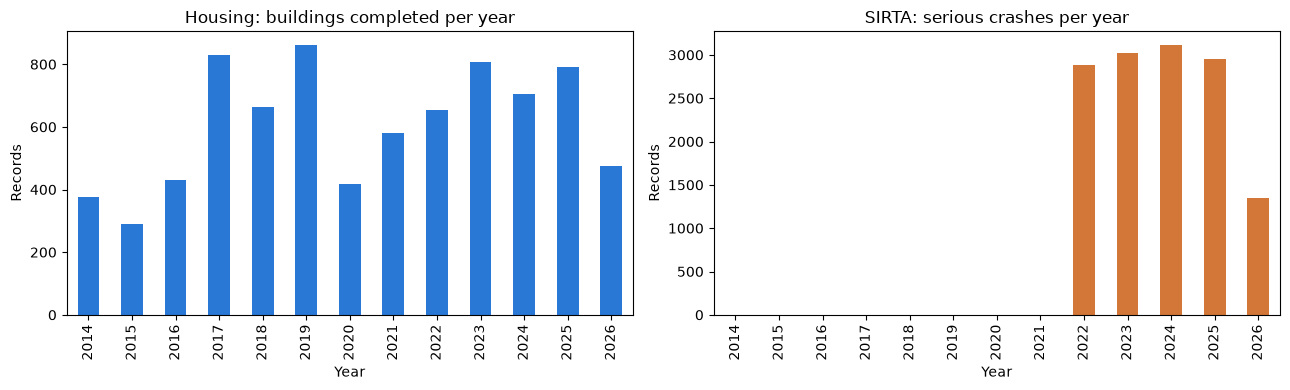

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
per_year["housing completions"].plot(kind="bar", ax=axes[0], color="#2a78d6")
axes[0].set_title("Housing: buildings completed per year")
per_year["SIRTA crashes"].plot(kind="bar", ax=axes[1], color="#d27738")
axes[1].set_title("SIRTA: serious crashes per year")
for ax in axes:
    ax.set_xlabel("Year")
    ax.set_ylabel("Records")
plt.tight_layout()
plt.show()

### 3.6 Duplicates

In [17]:
print("Housing exact duplicate rows:", housing_df.duplicated().sum())
print("Crash exact duplicate rows:", crashes_df.duplicated().sum())
print("Housing rows sharing a Building ID with another row:",
      housing_df["Building ID"].dropna().duplicated(keep=False).sum())
print("Crash rows sharing a Collision ID with another row:",
      crashes_df["Collision ID"].dropna().duplicated(keep=False).sum())

Housing exact duplicate rows: 0
Crash exact duplicate rows: 3
Housing rows sharing a Building ID with another row: 247
Crash rows sharing a Collision ID with another row: 2


### 3.7 Distributions and outliers (first look)

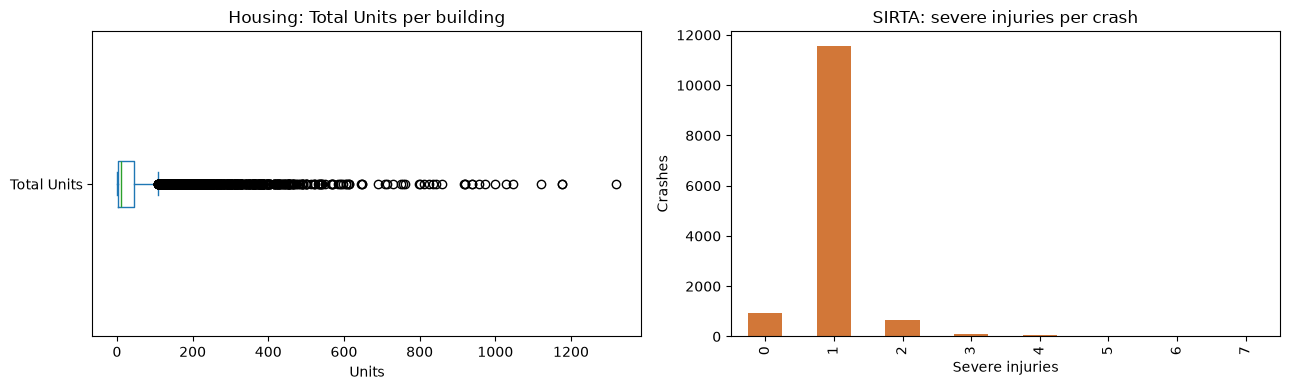

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
housing_df["Total Units"].plot(kind="box", ax=axes[0], vert=False)
axes[0].set_title("Housing: Total Units per building")
axes[0].set_xlabel("Units")
crashes_df["Total Severe Injuries"].dropna().astype(int).value_counts().sort_index().plot(kind="bar", ax=axes[1], color="#d27738")
axes[1].set_title("SIRTA: severe injuries per crash")
axes[1].set_xlabel("Severe injuries")
axes[1].set_ylabel("Crashes")
plt.tight_layout()
plt.show()

**What the EDA shows**
- **Size.** Housing has 9,551 rows × 41 columns; SIRTA has 13,754 rows × 23 columns (707,933 cells in total).
- **Missing values.**
  - The housing income and bedroom columns are mostly blank (for example 78% of Extremely Low Income Units). Section 5.2 shows that most of these blanks are certain zeros.
  - 1,949 housing records are confidential: their address is shown as `----` and Building ID, coordinates and postcode are blank.
  - In SIRTA, 444 records have no ID, date, time or injury counts. Community Board is blank for 72% of crashes, while coordinates are missing for only 21%. Fatal crashes are the exception: from 2023 on they carry no coordinates at all (Section 7.7 measures this).
- **Types.** pandas reads IDs, ZIP codes and BBLs as decimals (for example `4.098350e+09`), so the cleaning reads the file as text instead.
- **Time coverage.** Housing completions run from 2014 to 2026 and crashes from 2022 to mid-2026. 2022-2025 are the complete years present in both.
- **Duplicates.** SIRTA has 3 exact duplicate rows and 2 records sharing a Collision ID. 247 housing rows share a Building ID with another row (the same building in several projects).
- **Outliers and odd values.** Total Units is strongly right-skewed (median 12, maximum 1,320). Most crashes have exactly one severe injury. 227 crashes are timed exactly 00:00, which is likely a placeholder time.

### 3.8 Can the two datasets share a neighbourhood label?
Both files have a Community Board column (the community district), so it is the shared key. The housing file stores it as text such as `QN-08` and the crash file as a number such as `408`. The census tract and NTA columns cannot be used: the housing file uses 2010 boundaries and the crash file 2020 boundaries.

In [19]:
no_district = crashes_df["Community Board"].isnull()
print("Crashes without a Community Board:", no_district.sum())
print("... of which have coordinates:", (no_district & crashes_df["Latitude"].notna()).sum())
print("Housing Community Board examples:", housing_df["Community Board"].dropna().unique()[:5].tolist())

Crashes without a Community Board: 9883
... of which have coordinates: 7640
Housing Community Board examples: ['QN-08', 'BK-01', 'MN-10', 'BX-03', 'QN-14']


Most crashes have no Community Board but do have coordinates. The official Community District boundary file is used to look up their district. The lookup below checks whether a point lies inside a district polygon (ray casting). A point that lies exactly on a boundary is reported separately, so it is never forced into one of the two districts.

In [20]:
def ring_position(x, y, ring):
    """Ray casting for one ring: 1 inside, 0 exactly on the edge, -1 outside."""
    inside = False
    for (ax, ay, *_), (bx, by, *_) in zip(ring, ring[1:]):
        cross = (bx - ax) * (y - ay) - (by - ay) * (x - ax)
        on_edge = (abs(cross) <= 1e-12
                   and min(ax, bx) - 1e-10 <= x <= max(ax, bx) + 1e-10
                   and min(ay, by) - 1e-10 <= y <= max(ay, by) + 1e-10)
        if on_edge:
            return 0
        if (ay > y) != (by > y) and x < ax + (y - ay) * (bx - ax) / (by - ay):
            inside = not inside
    return 1 if inside else -1


def polygon_position(x, y, rings):
    """The first ring is the outline; the other rings are holes."""
    outer = ring_position(x, y, rings[0])
    if outer != 1:
        return outer
    for hole in rings[1:]:
        position = ring_position(x, y, hole)
        if position == 0:
            return 0
        if position == 1:
            return -1
    return 1


boundaries = json.loads((OUTPUT_ROOT / "reference" / "community_districts_26b.geojson").read_text(encoding="utf-8"))
district_polygons = []  # (district code, bounding box, rings)
for feature in boundaries["features"]:
    geometry = feature["geometry"]
    polygons = geometry["coordinates"] if geometry["type"] == "MultiPolygon" else [geometry["coordinates"]]
    for rings in polygons:
        xs = [p[0] for p in rings[0]]
        ys = [p[1] for p in rings[0]]
        district_polygons.append((int(feature["properties"]["boro_cd"]), (min(xs), min(ys), max(xs), max(ys)), rings))


@functools.lru_cache(maxsize=None)
def locate(lon, lat):
    """Return (districts containing the point, districts whose edge the point touches)."""
    if lon is None or lat is None:
        return (), ()
    inside, touches = set(), set()
    for code, (xmin, ymin, xmax, ymax), rings in district_polygons:
        if xmin - 1e-10 <= lon <= xmax + 1e-10 and ymin - 1e-10 <= lat <= ymax + 1e-10:
            position = polygon_position(lon, lat, rings)
            if position == 1:
                inside.add(code)
            elif position == 0:
                touches.add(code)
    return tuple(sorted(inside)), tuple(sorted(touches))


assert REGULAR <= {code for code, _, _ in district_polygons}
print("Boundary features:", len(boundaries["features"]), "| regular districts:", len(REGULAR))

Boundary features: 71 | regular districts: 59


## 4. Scope decisions
1. **Housing:** New Construction buildings completed in 2022-2025, the four most recent complete years in both files. Other records stay in the cleaned file; Preservation projects are used by the programme question in Section 7.6.
2. **Crashes:** SIRTA crashes in 2022-2025 that have an ID, a date and valid injury counts, and that can be placed in a community district.
3. **Geography:** the 59 regular community districts. Joint interest areas (large parks, airports) are not residential districts and are left out.
4. **Dates are not changed.** A completion date is not a move-in date, and a project start date is not the start of construction. Dates in an unusual order are flagged, not edited.
5. **One completion per building:** when a Building ID appears in several New Construction records, only its earliest completion is counted.
6. **Kept for the research questions:** crash time, tenure, bedroom and income columns.

## 5. Pre-integration cleaning
Each file is cleaned on its own. The cleaning starts from the text exactly as stored in the CSV, so identifiers keep every digit and nothing is converted silently. Every source row is kept in the cleaned output. A row that does not meet the scope gets a flag and a reason instead of being deleted.

### 5.1 Standardising formats (both files)
One rule per kind of column:
- surrounding spaces removed; blank → missing;
- dates `MM/DD/YYYY` → `YYYY-MM-DD`; crash time → `HH:MM`;
- counts → whole numbers ≥ 0, otherwise missing;
- identifiers kept as text; ZIP codes outside NYC's range, council districts outside 1-51 and badly formed BBLs → missing;
- coordinates → numbers; impossible values → missing;
- borough names and street names written in one consistent case;
- the confidential address placeholder `----` → missing.

In [21]:
def clean_identifier(column, text):
    n = integer(text)
    if n is None or n < 0:
        return None
    value = str(n)
    if column in ["Postcode", "ZipCode"] and (len(value) != 5 or not 10000 <= n <= 11699):
        return None
    if column == "Council District" and not 1 <= n <= 51:
        return None
    if column in ["BBL", "Borough Block Lot (BBL)"] and not re.fullmatch(r"[1-5]\d{9}", value):
        return None
    return value


def clean_value(dataset, column, text):
    text = text.strip()
    if not text:
        return None
    if dataset == "housing" and column in ["Number", "Street"] and text == "----":
        return None
    if column in COORDS:
        value = number(text)
        limit = 90 if "Latitude" in column else 180
        return value if value is not None and -limit <= value <= limit else None
    if column in (UNITS if dataset == "housing" else COUNTS):
        value = integer(text)
        return value if value is not None and value >= 0 else None
    if column in (HIDS if dataset == "housing" else TIDS):
        return clean_identifier(column, text)
    if "Date" in column:
        return as_date(text)
    if column == "Crash Time":
        return time_value(text)
    if column in ["Borough", "Crash Borough"]:
        value = " ".join(text.split()).title()
        return value if value in BORONUM else None
    if column in STREETS:
        return " ".join(text.split()).upper()
    if column == "Community Board" and dataset == "housing":
        return text.upper()
    return text


def standardise(dataset, text_rows):
    rows = []
    for i, raw in enumerate(text_rows, start=2):  # row 1 of the file is the header
        row = {"source_row": i, "source_key": f"{dataset}:{i}"}
        for column, text in raw.items():
            row[column] = clean_value(dataset, column, text)
        rows.append(row)
    return rows


housing_text, housing_fields = load_text_rows(OUTPUT_ROOT / "raw" / "housing.csv")
transport_text, transport_fields = load_text_rows(OUTPUT_ROOT / "raw" / "transport.csv")
assert len(housing_fields) == 41 and len(transport_fields) == 23, "the source files changed"

housing_rows = standardise("housing", housing_text)
crash_rows = standardise("transport", transport_text)
print("Housing rows:", len(housing_rows), "| crash rows:", len(crash_rows))

Housing rows: 9551 | crash rows: 13754


In [22]:
# Before and after for one housing record that has a completion date and income counts
k = next(i for i, raw in enumerate(housing_text)
         if raw["Building Completion Date"] and raw["Extremely Low Income Units"].strip() and raw["Street"] != "----")
example = ["Building ID", "BBL", "Project Start Date", "Building Completion Date", "Borough", "Community Board", "Postcode",
           "Latitude", "Street", "Total Units", "Extremely Low Income Units"]
pd.DataFrame({"raw text": [housing_text[k][c] for c in example],
              "cleaned": [housing_rows[k][c] for c in example]}, index=example)

,raw text,cleaned
Building ID,6241,6241
BBL,1021560033,1021560033
Project Start Date,06/30/2026,2026-06-30
Building Completion Date,06/30/2026,2026-06-30
Borough,Manhattan,Manhattan
Community Board,MN-12,MN-12
Postcode,10033,10033
Latitude,40.851208,40.851208
Street,AUDUBON AVENUE,AUDUBON AVENUE
Total Units,30,30


### 5.2 Housing (H2)
#### Step 1: categories and dates
Adds the completion year and flags (without changing them) dates in an impossible order, for example a building completed before its project started. It also flags New Construction rows marked "extended affordability only", a label that normally belongs to preservation.

In [23]:
def add_housing_flags(rows):
    for r in rows:
        r["construction_type"] = r["Reporting Construction Type"]
        r["project_start_year"] = year(r["Project Start Date"])
        r["completion_year"] = year(r["Building Completion Date"])
        r["confidential"] = r["Project Name"] == "CONFIDENTIAL"
        r["construction_extended_conflict"] = (r["construction_type"] == "New Construction"
                                               and r["Extended Affordability Only"] == "Yes")
        start, done, project_done = r["Project Start Date"], r["Building Completion Date"], r["Project Completion Date"]
        r["completion_before_project_start"] = bool(start and done and done < start)
        r["project_completion_before_start"] = bool(start and project_done and project_done < start)
        r["building_completion_after_project_completion"] = bool(done and project_done and done > project_done)


add_housing_flags(housing_rows)
print("Construction types:", dict(collections.Counter(r["construction_type"] for r in housing_rows)))
print("New Construction marked extended-affordability-only:", sum(r["construction_extended_conflict"] for r in housing_rows))
print("Building completed before project start:", sum(r["completion_before_project_start"] for r in housing_rows))

Construction types: {'New Construction': 4766, 'Preservation': 4785}
New Construction marked extended-affordability-only: 2
Building completed before project start: 20


#### Step 2: missing unit counts
The income, bedroom and tenure columns are mostly blank. A blank is filled with 0 only when it cannot be anything else: the other values in that group already add up to the row's affordable total (`All Counted Units`). Otherwise the blank stays missing. No mean or median filling is used, because an invented unit count would change exactly the totals being compared.

In [24]:
def fill_certain_zeros(rows, text_rows):
    for r, text in zip(rows, text_rows):
        r["component_zero_imputations"] = 0
        for group, columns in [("income", INCOME), ("bedrooms", BEDROOM), ("tenure", TENURE)]:
            total = r["All Counted Units"]
            known_sum = sum(r[c] or 0 for c in columns)
            no_bad_values = all(r[c] is not None or not text[c].strip() for c in columns)
            reconciles = total is not None and known_sum == total and no_bad_values
            r[group + "_reconciles"] = reconciles
            if reconciles:
                for c in columns:
                    if r[c] is None:
                        r[c] = 0
                        r["component_zero_imputations"] += 1


before = sum(r["Extremely Low Income Units"] is None for r in housing_rows)
fill_certain_zeros(housing_rows, housing_text)
after = sum(r["Extremely Low Income Units"] is None for r in housing_rows)
print("Blank cells filled with 0:", sum(r["component_zero_imputations"] for r in housing_rows))
print("Extremely Low Income Units missing: before", before, "| after", after)

Blank cells filled with 0: 105816
Extremely Low Income Units missing: before 7470 | after 29


#### Step 3: impossible unit totals
A row can be counted only when Total Units is a positive whole number and the affordable units do not exceed it.

In [25]:
for r in housing_rows:
    affordable, total = r["All Counted Units"], r["Total Units"]
    r["affordable_exceeds_total"] = bool(affordable is not None and total is not None and affordable > total)
    r["units_valid"] = isinstance(total, int) and total > 0 and not r["affordable_exceeds_total"]

print("Affordable units greater than total units:", sum(r["affordable_exceeds_total"] for r in housing_rows))
print("Rows without a usable Total Units:", sum(not r["units_valid"] for r in housing_rows))

Affordable units greater than total units: 0
Rows without a usable Total Units: 0


#### Step 4: exact duplicates
A row is an exact duplicate when every raw value equals an earlier row. The first copy is kept; later copies are marked with the row they repeat.

In [26]:
def mark_exact_duplicates(rows, text_rows):
    first_seen = {}
    for r, text in zip(rows, text_rows):
        key = tuple(text.values())
        r["exact_duplicate_of"] = first_seen.get(key)
        first_seen.setdefault(key, r["source_row"])


mark_exact_duplicates(housing_rows, housing_text)
print("Housing exact duplicates:", sum(r["exact_duplicate_of"] is not None for r in housing_rows))

Housing exact duplicates: 0


#### Step 5: community district
The same rule is used for both files:
1. A reported district that is one of the 59 regular districts is used when nothing contradicts it (the borough and the coordinates agree).
2. If the reported district is contradicted, the record is left unassigned rather than choosing between the two.
3. If no district is reported, it is looked up from the coordinates, but only when the point lies inside exactly one district of the record's own borough.
4. Everything else (points on a boundary, in a park or airport area, outside the city, or no coordinates) stays unassigned.

`cd_method` records which case applied to each record.

In [27]:
def reported_district(dataset, row):
    """Reported Community Board as a number: 'QN-08' or '408' -> 408."""
    reported = row.get("Community Board")
    if not reported:
        return None
    if dataset == "transport":
        return integer(reported)
    m = re.fullmatch(r"([A-Z]{2})-?(\d{1,2})", reported)
    return PREFIX[m[1]] * 100 + int(m[2]) if m and m[1] in PREFIX else None


def single_district(lon, lat):
    inside, touches = locate(lon, lat)
    return inside[0] if len(inside) == 1 and not touches else None


def assign_district(dataset, row):
    cd = reported_district(dataset, row)
    borough = row.get("Borough" if dataset == "housing" else "Crash Borough")
    borough_number = BORONUM.get(borough)
    lon, lat = coordinate_pair(row)
    inside, touches = locate(lon, lat)
    spatial = single_district(lon, lat)
    internal = single_district(*coordinate_pair(row, internal=True)) if dataset == "housing" else None

    regular = cd in REGULAR
    disputed = regular and (
        (borough_number is not None and cd // 100 != borough_number)
        or (spatial is not None and cd != spatial)
        or (internal is not None and cd != internal))

    district = None
    if regular and not disputed:
        district, method = cd, "reported_validated"
    elif regular:
        method = "reported_spatial_or_borough_dispute"
    elif cd is not None:
        method = "reported_special_or_invalid"
    elif spatial in REGULAR and (borough_number is None or spatial // 100 == borough_number):
        district, method = spatial, "recovered_unique_polygon"
    elif spatial is not None and spatial not in REGULAR:
        method = "spatial_joint_interest_area"
    elif spatial in REGULAR:
        method = "spatial_borough_dispute"
    elif touches or len(inside) > 1:
        method = "boundary_or_multiple_match"
    elif lon is None:
        method = "missing_or_invalid_coordinates_and_cd"
    else:
        method = "outside_land_boundary_reference"

    row["cd_reported"] = cd
    row["cd_spatial"] = spatial
    row["cd_internal_spatial"] = internal
    row["cd"] = district
    row["cd_method"] = method
    row["geography_disputed"] = bool(disputed)
    row["borough"] = borough or (BORO[district // 100] if district else None)
    row["borough_inferred"] = bool(not borough and district)
    row["coordinates_available"] = lon is not None


for r in housing_rows:
    assign_district("housing", r)
pd.Series(collections.Counter(r["cd_method"] for r in housing_rows), name="housing records").sort_values(ascending=False)

reported_validated                     9523
reported_spatial_or_borough_dispute      28
Name: housing records, dtype: int64

#### Step 6: the same building in several records
A Building ID can appear in more than one New Construction record, for example when a building belongs to two HPD projects. To count each building once, only its earliest completion is kept. If two records share that earliest date, the building is left out, because it is not clear which record is right.

In [28]:
def mark_repeated_buildings(rows):
    records_per_building = collections.Counter(r["Building ID"] for r in rows if r["Building ID"])
    completions = collections.defaultdict(list)
    for r in rows:
        if r["construction_type"] == "New Construction" and r["Building Completion Date"] and r["Building ID"]:
            completions[r["Building ID"]].append(r)

    earliest_keys, tied_buildings = set(), set()
    for building, group in completions.items():
        first = min(group, key=lambda r: (r["Building Completion Date"], r["source_row"]))
        earliest_keys.add(first["source_key"])
        if sum(r["Building Completion Date"] == first["Building Completion Date"] for r in group) > 1:
            tied_buildings.add(building)

    for r in rows:
        r["repeated_building_id"] = bool(r["Building ID"] and records_per_building[r["Building ID"]] > 1)
        r["earliest_completion_assumption_retained"] = not r["Building ID"] or r["source_key"] in earliest_keys
        r["earliest_date_tie"] = r["Building ID"] in tied_buildings


mark_repeated_buildings(housing_rows)
print("Records whose Building ID repeats:", sum(r["repeated_building_id"] for r in housing_rows))
completed_new = [r for r in housing_rows if r["construction_type"] == "New Construction" and r["Building Completion Date"]]
print("Completed New Construction records:", len(completed_new))
print("... later records of a building completed earlier:",
      sum(not r["earliest_completion_assumption_retained"] for r in completed_new))
print("... buildings with two records on the same earliest date:", sum(r["earliest_date_tie"] for r in completed_new))

Records whose Building ID repeats: 247
Completed New Construction records: 4008
... later records of a building completed earlier: 11
... buildings with two records on the same earliest date: 2


#### Step 7: scope and eligibility
A housing record is counted in the district totals only when every rule passes. A record that fails keeps the list of reasons in `primary_exclusion_reasons`.

In [29]:
def housing_exclusion_reasons(r):
    rules = [
        ("outside_new_completion_2022_2025", not r["main_scope"]),
        ("exact_duplicate", r["exact_duplicate_of"] is not None),
        ("invalid_units", not r["units_valid"]),
        ("district_unresolved_or_disputed", r["cd"] is None),
        ("construction_extended_conflict", r["construction_extended_conflict"]),
        ("later_record_under_first_completion_assumption", not r["earliest_completion_assumption_retained"]),
        ("earliest_date_tie", r["earliest_date_tie"]),
    ]
    return [reason for reason, failed in rules if failed]


for r in housing_rows:
    r["main_scope"] = r["construction_type"] == "New Construction" and r["completion_year"] in YEARS
    reasons = housing_exclusion_reasons(r)
    r["primary_eligible"] = not reasons
    r["primary_exclusion_reasons"] = "|".join(reasons)
    # used by the programme-activity table (start year instead of completion year)
    r["quality_eligible_without_geography"] = (r["units_valid"] and r["exact_duplicate_of"] is None
                                               and not r["construction_extended_conflict"] and not r["earliest_date_tie"])

scoped = [r for r in housing_rows if r["main_scope"]]
print("Housing records:", len(housing_rows))
print("New Construction completed 2022-2025:", len(scoped))
print("Counted in the district totals:", sum(r["primary_eligible"] for r in scoped))
print("Confidential records:", sum(r["confidential"] for r in housing_rows))
pd.Series(collections.Counter(reason for r in scoped for reason in r["primary_exclusion_reasons"].split("|") if reason),
          name="in-scope records left out").sort_values(ascending=False)

Housing records: 9551
New Construction completed 2022-2025: 1886
Counted in the district totals: 1878
Confidential records: 1949


district_unresolved_or_disputed                   7
later_record_under_first_completion_assumption    1
Name: in-scope records left out, dtype: int64

#### Decisions: missing values and duplicates
Every source row stays in the cleaned housing file; rows that fail a rule are flagged with a reason instead of deleted. A missing Building ID or address alone does not stop a record from being counted, because district totals do not need them.

**Drop vs impute: what was done and why.**
- **Imputed, only where the value is certain.** A blank income, bedroom or tenure component is set to 0 when the row's other components already add up to its reported affordable total, so the blank can only be 0 (105,816 cells). No mean, median or model imputation is used: an invented unit or injury count would change exactly the totals the research question compares.
- **Left out of the district totals, kept in the detail.** A record without the fields needed to count it cannot be placed in a district-year, so it is excluded from the totals with a recorded reason instead of being guessed. Examples: 444 crash records with no ID, date or outcome, and 2,099 in-scope crashes with neither a usable district code nor coordinates. Unknown unit totals stay missing rather than becoming 0.
- **Kept as missing.** Masked confidential addresses (1,949 housing records) and other non-key blanks stay blank; district-level counts do not need them.
- **Alternatives rejected.** Deleting every row with a blank would remove most housing rows, because the income and bedroom columns are mostly blank. Assigning crashes without coordinates to the nearest or most likely district would place real crashes in the wrong district.

### 5.3 Transportation (SIRTA)
The whole file is cleaned before the years are filtered, so a Collision ID repeated in different years is still found.

#### Step 1: date, time and exact duplicates
Crash time is kept as an hour (0-23). Crashes timed exactly 00:00 are flagged, because midnight is often used when the real time is unknown.

In [30]:
for r in crash_rows:
    r["year"] = year(r["Crash Date"])
    r["hour"] = int(r["Crash Time"][:2]) if r["Crash Time"] else None
    r["midnight_time_flag"] = r["Crash Time"] == "00:00"

mark_exact_duplicates(crash_rows, transport_text)
print("Crash exact duplicates:", sum(r["exact_duplicate_of"] is not None for r in crash_rows))
print("Crashes timed 00:00:", sum(r["midnight_time_flag"] for r in crash_rows))

Crash exact duplicates: 3
Crashes timed 00:00: 227


#### Step 2: community district
Same rule as Step 5 of the housing cleaning.

In [31]:
for r in crash_rows:
    assign_district("transport", r)
pd.Series(collections.Counter(r["cd_method"] for r in crash_rows), name="crash records").sort_values(ascending=False)

recovered_unique_polygon                 7434
reported_validated                       3650
missing_or_invalid_coordinates_and_cd    2243
spatial_joint_interest_area               170
reported_spatial_or_borough_dispute       134
reported_special_or_invalid                87
outside_land_boundary_reference            23
spatial_borough_dispute                     8
boundary_or_multiple_match                  5
Name: crash records, dtype: int64

#### Step 3: repeated Collision IDs
A Collision ID should identify one crash. When it appears on more than one record, the records are not merged and neither is chosen; all of them are left out of the totals.

In [32]:
records_per_id = collections.Counter(r["Collision ID"] for r in crash_rows if r["Collision ID"])
for r in crash_rows:
    r["repeated_event_identity"] = records_per_id[r["Collision ID"]] > 1

print("Records with a repeated Collision ID:", sum(r["repeated_event_identity"] for r in crash_rows))
print("Records with no Collision ID:", sum(not r["Collision ID"] for r in crash_rows))

Records with a repeated Collision ID: 2
Records with no Collision ID: 444


#### Step 4: injury counts and the 3-year lookback
KSI (killed or seriously injured) = severe injuries + fatalities. The lookback fields count similar crashes at the same place in the previous three years; a missing lookback stays missing.

In [33]:
for r in crash_rows:
    severe, fatal, lookback, lookback_all = r["Total Severe Injuries"], r["Total Fatalities"], r[LOOK], r[LOOKALL]
    r["outcome_counts_valid"] = all(isinstance(r[c], int) and r[c] >= 0 for c in COUNTS[:3])
    r["ksi"] = severe + fatal if r["outcome_counts_valid"] else None
    r["fatal_event"] = fatal > 0 if fatal is not None else None
    r["multiple_ksi_event"] = r["ksi"] > 1 if r["ksi"] is not None else None
    r["lookback_known"] = lookback is not None
    r["positive_lookback"] = lookback > 0 if lookback is not None else None
    r["all_injury_lookback_known"] = lookback_all is not None
    r["all_injury_positive_lookback"] = lookback_all > 0 if lookback_all is not None else None
    r["lookback_severe_exceeds_all"] = bool(lookback is not None and lookback_all is not None and lookback > lookback_all)

print("Records with invalid or missing injury counts:", sum(not r["outcome_counts_valid"] for r in crash_rows))
print("Records with a known lookback:", sum(r["lookback_known"] for r in crash_rows))

Records with invalid or missing injury counts: 444
Records with a known lookback: 11917


#### Step 5: scope and eligibility

In [34]:
def crash_problems(r):
    rules = [
        ("missing_event_id", not r["Collision ID"]),
        ("missing_or_invalid_crash_date", not r["Crash Date"]),
        ("exact_duplicate", r["exact_duplicate_of"] is not None),
        ("unresolved_repeated_event_identity", r["repeated_event_identity"]),
        ("invalid_outcome_counts", not r["outcome_counts_valid"]),
    ]
    return [reason for reason, failed in rules if failed]


for r in crash_rows:
    problems = crash_problems(r)
    r["event_valid"] = not problems
    r["event_exclusion_reasons"] = "|".join(problems)
    r["main_scope"] = r["event_valid"] and r["year"] in YEARS
    r["primary_eligible"] = r["main_scope"] and r["cd"] is not None
    extra = (["outside_2022_2025"] if r["year"] not in YEARS else []) + \
            (["district_unresolved_or_disputed"] if r["cd"] is None else [])
    r["primary_exclusion_reasons"] = "|".join(problems + extra)

print("Crash records:", len(crash_rows))
print("Valid crashes in 2022-2025:", sum(r["main_scope"] for r in crash_rows))
print("Placed in a district (counted):", sum(r["primary_eligible"] for r in crash_rows))
pd.Series(collections.Counter(r["cd_method"] for r in crash_rows if r["main_scope"]),
          name="valid 2022-2025 crashes").sort_values(ascending=False)

Crash records: 13754
Valid crashes in 2022-2025: 11957
Placed in a district (counted): 9458


recovered_unique_polygon                 6906
reported_validated                       2552
missing_or_invalid_coordinates_and_cd    2099
spatial_joint_interest_area               162
reported_spatial_or_borough_dispute       134
reported_special_or_invalid                70
outside_land_boundary_reference            22
spatial_borough_dispute                     7
boundary_or_multiple_match                  5
Name: valid 2022-2025 crashes, dtype: int64

### 5.4 Outliers (IQR rule, both datasets)
Every count column of the in-scope records is checked with the IQR rule: Q1 and Q3 are the 25th and 75th percentiles, and a value above Q3 + 1.5 × (Q3 − Q1) is flagged. Flagged records are kept; the flag is for review.

In [35]:
outlier_thresholds = []


def flag_outliers(dataset, rows, columns):
    fences = {}
    for column in columns:
        values = [r[column] for r in rows if r["main_scope"] and r[column] is not None]
        if not values:
            continue
        q1, q3 = percentile(values, 0.25), percentile(values, 0.75)
        fences[column] = q3 + 1.5 * (q3 - q1)
        outlier_thresholds.append({"dataset": dataset, "column": column, "known_values": len(values),
                                   "q1": q1, "q3": q3, "upper_fence": fences[column],
                                   "flagged_scope_records": sum(v > fences[column] for v in values)})
    for r in rows:
        r["count_outlier_fields"] = "|".join(c for c, fence in fences.items() if r[c] is not None and r[c] > fence)


flag_outliers("housing", housing_rows, UNITS)
flag_outliers("transport", crash_rows, COUNTS)

# Building-level flag used in the district summaries (buildings with valid unit totals)
valid_units = [r["Total Units"] for r in housing_rows if r["main_scope"] and r["units_valid"]]
q1, q3 = percentile(valid_units, 0.25), percentile(valid_units, 0.75)
unit_fence = q3 + 1.5 * (q3 - q1)
for r in housing_rows:
    r["unit_outlier_flag"] = bool(r["units_valid"] and r["Total Units"] > unit_fence)

pd.DataFrame(outlier_thresholds)

,dataset,column,known_values,q1,q3,upper_fence,flagged_scope_records
0,housing,Extremely Low Income Units,1886,0.0,0.00,0.000,159
1,housing,Very Low Income Units,1886,0.0,0.00,0.000,220
2,housing,Low Income Units,1886,0.0,1.00,2.500,290
3,housing,Moderate Income Units,1886,0.0,0.00,0.000,132
4,housing,Middle Income Units,1886,0.0,10.00,25.000,170
5,housing,Other Income Units,1886,0.0,0.00,0.000,135
6,housing,Studio Units,1886,0.0,4.00,10.000,284
7,housing,1-BR Units,1886,1.0,8.00,18.500,259
8,housing,2-BR Units,1886,0.0,6.00,15.000,188
9,housing,3-BR Units,1886,0.0,0.00,0.000,342


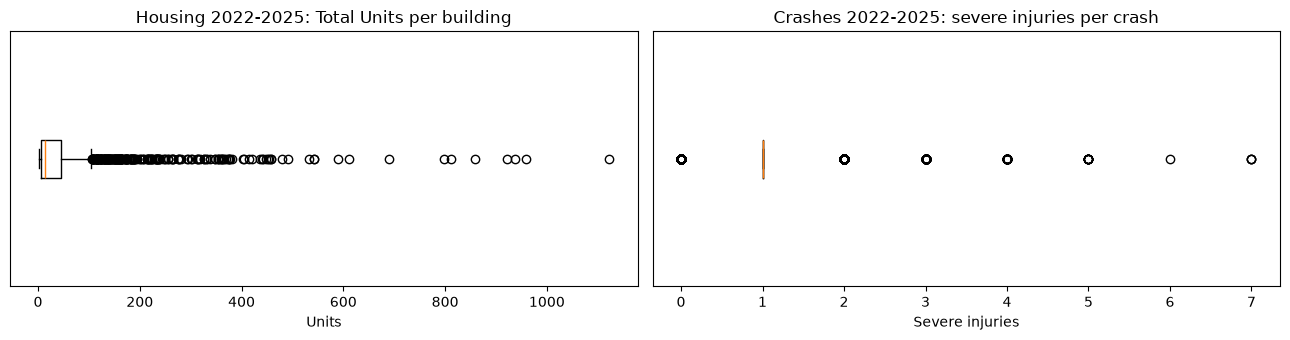

In [36]:
scoped_units = [r["Total Units"] for r in housing_rows if r["main_scope"] and r["Total Units"] is not None]
scoped_severe = [r["Total Severe Injuries"] for r in crash_rows if r["main_scope"]]

fig, axes = plt.subplots(1, 2, figsize=(13, 3.5))
axes[0].boxplot(scoped_units, orientation="horizontal", whis=1.5)
axes[0].set_title("Housing 2022-2025: Total Units per building")
axes[0].set_xlabel("Units")
axes[1].boxplot(scoped_severe, orientation="horizontal", whis=1.5)
axes[1].set_title("Crashes 2022-2025: severe injuries per crash")
axes[1].set_xlabel("Severe injuries")
for ax in axes:
    ax.set_yticks([])
plt.tight_layout()
plt.show()

**Decision: flag and keep.**
- **Housing.** For Total Units, Q1 = 6 and Q3 = 45.75, so buildings above 105.4 units are flagged (225 of 1,886 in-scope completions). They are real large buildings that HPD reports one by one. Removing them would delete exactly the large developments a "surge in construction" question is about.
- **Crashes.** For Total Severe Injuries Q1 = Q3 = 1, so every crash with two or more serious injuries is flagged (713). These are multi-victim crashes, not errors.
- **Rare counts.** Where Q1 = Q3 = 0 (for example 4-BR units or fatalities) the fence is 0 and every non-zero value is flagged. This shows the IQR rule cannot judge rare counts on its own, which is why flags are used for review only. Domain rules handle real errors instead: counts must be non-negative whole numbers, and components must add up to their reported totals.

## 6. Integration
Each dataset is first summarised to one row per community district and year, and only then are the two summaries joined. Joining the raw building and crash rows directly would repeat every crash once for each building in the district.

**Why community district × year is the join key.**
- **Community district** is the only geography both sources can share reliably. HPD reports it for each building. SIRTA crashes are placed in a district from their coordinates using the official boundaries. Districts are also the city's planning units, so results map directly to Community Boards and agency programmes.
- **Alternatives considered and rejected:**
  - *ZIP code*: postal delivery routes, not stable areas. Their borders cut across districts and change over time.
  - *Census tract*: the housing data uses 2010 tracts and the crash data 2020 tracts, so a tract join would need a crosswalk and would still leave most tract-years with zero completions.
  - *Monthly or quarterly periods*: there are only about 0.66 completed buildings per district-month (1,878 buildings over 59 districts × 48 months), so most cells would be zero. A year keeps the counts stable while still showing change over 2022-2025.
  - *Record-level spatial joins* (crashes within a radius of each building): the answer depends on the chosen distance, and one crash would be counted against several buildings.
- The result has 59 × 4 = 236 rows, one per district-year. It is small enough to check by hand, and it is the table the website reads.

#### Step 1: summarise each dataset by district and year

In [37]:
def group_rows(rows, key):
    groups = collections.defaultdict(list)
    for r in rows:
        groups[key(r)].append(r)
    return groups


def housing_summary(rows, key):
    out = {}
    for k, group in group_rows(rows, key).items():
        s = {
            "housing_source_records": len(group),
            "housing_identified_buildings": len({r["Building ID"] for r in group if r["Building ID"]}),
            "housing_projects": len({r["Project ID"] for r in group if r["Project ID"]}),
            "housing_missing_building_id_records": sum(not r["Building ID"] for r in group),
            "housing_coordinate_records": sum(r["coordinates_available"] for r in group),
            "housing_date_order_flag_records": sum(r["completion_before_project_start"] for r in group),
            "housing_outlier_records": sum(r["unit_outlier_flag"] for r in group),
        }
        for column, name in UNITKEY.items():
            values = [r[column] for r in group if r[column] is not None]
            s["housing_" + name] = sum(values) if values else None
            s["housing_" + name + "_known_records"] = len(values)
        s["housing_median_total_units_per_record"] = statistics.median(
            [r["Total Units"] for r in group if r["Total Units"] is not None])
        out[k] = s
    return out


def crash_summary(rows, key):
    out = {}
    for k, g in group_rows(rows, key).items():
        out[k] = {
            "crash_events": len(g),
            "non_severe_injuries": sum(r["Total Non-Severe Injuries"] for r in g),
            "severe_injuries": sum(r["Total Severe Injuries"] for r in g),
            "fatalities": sum(r["Total Fatalities"] for r in g),
            "ksi": sum(r["ksi"] for r in g),
            "fatal_events": sum(r["fatal_event"] for r in g),
            "multiple_ksi_events": sum(r["multiple_ksi_event"] for r in g),
            "lookback_known_events": sum(r["lookback_known"] for r in g),
            "positive_lookback_events": sum(r["positive_lookback"] is True for r in g),
            "time_known_events": sum(r["hour"] is not None for r in g),
            "midnight_events": sum(r["midnight_time_flag"] for r in g),
            "reported_district_events": sum(r["cd_method"] == "reported_validated" for r in g),
            "spatially_recovered_events": sum(r["cd_method"] == "recovered_unique_polygon" for r in g),
        }
    return out


housing_eligible_rows = [r for r in housing_rows if r["primary_eligible"]]
crash_eligible_rows = [r for r in crash_rows if r["primary_eligible"]]
housing_by_key = housing_summary(housing_eligible_rows, lambda r: (r["cd"], r["completion_year"]))
crashes_by_key = crash_summary(crash_eligible_rows, lambda r: (r["cd"], r["year"]))
print("Housing district-years with completions:", len(housing_by_key))
print("Crash district-years with crashes:", len(crashes_by_key))

Housing district-years with completions: 218
Crash district-years with crashes: 236


#### Step 2: merge on community district × year
The table starts from all 59 × 4 district-years, so a district-year with no completions or no crashes still has a row.

In [38]:
housing_columns = list(next(iter(housing_by_key.values())))
crash_columns = list(next(iter(crashes_by_key.values())))
unassigned_per_year = collections.Counter(r["year"] for r in crash_rows if r["main_scope"] and r["cd"] is None)
excluded_per_year = collections.Counter(r["completion_year"] for r in housing_rows if r["main_scope"] and not r["primary_eligible"])

integrated_rows = []
for cd in sorted(REGULAR):
    for y in YEARS:
        key = (cd, y)
        row = {"cd": cd, "borough": BORO[cd // 100], "year": y,
               "housing_source_present": key in housing_by_key,
               "crash_source_present": key in crashes_by_key,
               "housing_join_status": "matched" if key in housing_by_key else "no_eligible_observed_completion",
               "crash_join_status": "matched" if key in crashes_by_key else "no_assigned_eligible_recorded_event"}
        # no matching record -> counts are 0, the median stays missing
        row.update({c: None if c == "housing_median_total_units_per_record" else 0 for c in housing_columns})
        row.update({c: 0 for c in crash_columns})
        row.update(housing_by_key.get(key, {}))
        row.update(crashes_by_key.get(key, {}))

        all_known = row["housing_affordable_units_known_records"] == row["housing_source_records"]
        row["housing_affordable_share_of_reported_total"] = (
            row["housing_affordable_units"] / row["housing_total_units"] if row["housing_total_units"] and all_known else None)
        row["recurrence_share_among_known_lookback_events"] = (
            row["positive_lookback_events"] / row["lookback_known_events"] if row["lookback_known_events"] else None)
        row["lookback_coverage_share"] = row["lookback_known_events"] / row["crash_events"] if row["crash_events"] else None
        row["citywide_unassigned_eligible_events_in_year"] = unassigned_per_year[y]
        row["citywide_excluded_scoped_housing_records_in_year"] = excluded_per_year[y]
        row["event_counts_are_observed_not_exposure_adjusted"] = True
        integrated_rows.append(row)

integrated_df = pd.DataFrame(integrated_rows)
print("Integrated table:", integrated_df.shape)
integrated_df[["cd", "borough", "year", "housing_source_records", "housing_total_units",
               "housing_affordable_units", "crash_events", "ksi", "housing_join_status"]].head(8)

Integrated table: (236, 70)


,cd,borough,year,housing_source_records,housing_total_units,housing_affordable_units,crash_events,ksi,housing_join_status
0,101,Manhattan,2022,0,0,0,11,11,no_eligible_observed_completion
1,101,Manhattan,2023,1,209,63,13,13,matched
2,101,Manhattan,2024,0,0,0,19,19,no_eligible_observed_completion
3,101,Manhattan,2025,0,0,0,24,24,no_eligible_observed_completion
4,102,Manhattan,2022,2,167,47,35,38,matched
5,102,Manhattan,2023,0,0,0,27,27,no_eligible_observed_completion
6,102,Manhattan,2024,0,0,0,27,27,no_eligible_observed_completion
7,102,Manhattan,2025,0,0,0,35,35,no_eligible_observed_completion


#### Step 3: tables kept separate from the main table
- **Crashes by hour:** one row per district × year × hour. Kept separate so that the yearly housing totals are not repeated 24 times.
- **Housing programme activity:** projects grouped by their *start* year and programme type. This uses a different date from the completion totals, so it is not merged into the main table.

In [39]:
timed_crashes = [r for r in crash_eligible_rows if r["hour"] is not None]
crashes_by_hour = crash_summary(timed_crashes, lambda r: (r["cd"], r["year"], r["hour"]))
hourly_rows = []
for cd in sorted(REGULAR):
    for y in YEARS:
        for hour in range(24):
            metrics = {c: 0 for c in crash_columns}
            metrics.update(crashes_by_hour.get((cd, y, hour), {}))
            hourly_rows.append({"cd": cd, "borough": BORO[cd // 100], "year": y, "hour": hour} | metrics)

started = [r for r in housing_rows
           if r["project_start_year"] in YEARS and r["quality_eligible_without_geography"] and r["cd"] is not None]
activity_by_key = housing_summary(started, lambda r: (r["cd"], r["project_start_year"], r["construction_type"],
                                                      r["Extended Affordability Only"], r["Prevailing Wage Status"]))
activity_rows = [{"cd": k[0], "borough": BORO[k[0] // 100], "project_start_year": k[1], "construction_type": k[2],
                  "extended_affordability_only": k[3], "prevailing_wage_status": k[4],
                  "time_basis": "project_loan_agreement_or_marketing_start"} | v
                 for k, v in sorted(activity_by_key.items())]

# Tables shared with the research-question sections (7.4-7.10)
shared = SimpleNamespace(integrated=integrated_rows, hourly=hourly_rows, activity=activity_rows,
                         hs=housing_eligible_rows, ts=crash_eligible_rows)
print("Hourly rows:", len(hourly_rows), "| programme activity groups:", len(activity_rows))

Hourly rows: 5664 | programme activity groups: 474


## 7. Post-integration cleaning and analysis
After the merge the table is checked again: unique keys, data types, missing values, and whether every total still matches the cleaned records it came from (Section 7.1).

**What the join introduced and how it was handled:**
- **New missing values.** Every district-year has at least one crash (236 of 236 matched). 18 district-years had no counted housing completion (`housing_join_status = no_eligible_observed_completion`).
  - Their unit counts are set to 0, because "no completed building observed" is a real zero for a count.
  - The median building size and the affordable share would divide by zero, so they stay blank for those 18 rows. These are the only blank cells in the table.
- **Redundant columns.** The table has one `borough` column taken from the district code, so the two sources' own borough columns are not repeated. The original source columns stay in the cleaned record-level files.
  - Four status columns carry little information here. `crash_source_present`, `crash_join_status` and `event_counts_are_observed_not_exposure_adjusted` have the same value in all 236 rows, because every district-year matched at least one crash. `housing_source_present` is the yes/no form of `housing_join_status`.
  - They are kept on purpose as join-audit flags, so a reader of the CSV can see how each row was matched without opening the notebook. No analysis uses them.
- **Data types.** Counts are integers (60 columns), ratios and medians are decimals (4), the yes/no fields are booleans (3), and the borough and status fields are text (3).
- **Row multiplication.** Each source is summarised before the join and the result has unique (`cd`, `year`) keys, so no housing or crash total is counted twice. Crash counts by hour are kept in a separate table for the same reason.

A district-year without a match means no *counted* completion or crash was recorded there, not proof that nothing happened.

### 7.1 Checks on the integrated table
Each check compares the merged table with the cleaned records it was built from. The notebook stops if any check fails.

In [40]:
checks = {}
checks["every housing source row kept"] = len(housing_rows) == len(housing_text)
checks["every crash source row kept"] = len(crash_rows) == len(transport_text)
checks["236 district-year rows"] = len(integrated_df) == 236
checks["no duplicate (cd, year) keys"] = not integrated_df.duplicated(["cd", "year"]).any()
checks["only regular districts and 2022-2025"] = integrated_df["cd"].isin(REGULAR).all() and integrated_df["year"].between(START, END).all()
checks["each counted crash appears once"] = len({r["Collision ID"] for r in crash_eligible_rows}) == len(crash_eligible_rows)

for column, name in UNITKEY.items():
    detail_total = sum(r[column] for r in housing_eligible_rows if r[column] is not None)
    checks[f"housing {name} total matches detail"] = integrated_df["housing_" + name].fillna(0).sum() == detail_total

crash_totals = {"crash_events": len(crash_eligible_rows),
                "severe_injuries": sum(r["Total Severe Injuries"] for r in crash_eligible_rows),
                "fatalities": sum(r["Total Fatalities"] for r in crash_eligible_rows),
                "ksi": sum(r["ksi"] for r in crash_eligible_rows),
                "lookback_known_events": sum(r["lookback_known"] for r in crash_eligible_rows)}
for column, detail_total in crash_totals.items():
    checks[f"crash {column} total matches detail"] = integrated_df[column].sum() == detail_total

hourly_df = pd.DataFrame(hourly_rows)
hourly_sum = hourly_df.groupby(["cd", "year"])["crash_events"].sum()
checks["hourly table has 59 x 4 x 24 rows"] = len(hourly_df) == 5664
checks["hourly counts add up to timed crashes"] = (hourly_sum.values == integrated_df.set_index(["cd", "year"]).loc[hourly_sum.index, "time_known_events"].values).all()
checks["lookback counts within crash counts"] = ((integrated_df["positive_lookback_events"] <= integrated_df["lookback_known_events"])
                                                 & (integrated_df["lookback_known_events"] <= integrated_df["crash_events"])).all()
checks["no negative counts"] = (integrated_df.select_dtypes("number").fillna(0) >= 0).all().all()
checks["recovered districts come from one polygon"] = all(
    r["cd"] == r["cd_spatial"] for r in housing_rows + crash_rows if r["cd_method"] == "recovered_unique_polygon")

check_results = pd.Series(checks, name="passed")
print(f"{check_results.sum()} of {len(check_results)} checks passed")
assert check_results.all(), check_results[~check_results]
check_results.to_frame()

34 of 34 checks passed


,passed
every housing source row kept,True
every crash source row kept,True
236 district-year rows,True
"no duplicate (cd, year) keys",True
only regular districts and 2022-2025,True
each counted crash appears once,True
housing extremely_low_income_units total matches detail,True
housing very_low_income_units total matches detail,True
housing low_income_units total matches detail,True
housing moderate_income_units total matches detail,True


In [41]:
# Missing values, data types and duplicates after the merge
print("Duplicate rows:", integrated_df.duplicated().sum())
print("\nColumns with missing values:")
print(integrated_df.isnull().sum()[lambda s: s > 0])
print("\nData types:")
print(integrated_df.dtypes.value_counts())

Duplicate rows: 0

Columns with missing values:
housing_median_total_units_per_record         18
housing_affordable_share_of_reported_total    18
dtype: int64

Data types:
int64      60
float64     4
str         3
bool        3
Name: count, dtype: int64


In [42]:
integrated_df[["housing_source_records", "housing_total_units", "housing_affordable_units",
               "crash_events", "severe_injuries", "fatalities", "ksi"]].describe().round(1)

,housing_source_records,housing_total_units,housing_affordable_units,crash_events,severe_injuries,fatalities,ksi
count,236.0,236.0,236.0,236.0,236.0,236.0,236.0
mean,8.0,366.3,203.5,40.1,42.5,0.9,43.5
std,7.2,451.9,266.6,16.0,17.8,1.8,18.1
min,0.0,0.0,0.0,11.0,9.0,0.0,11.0
25%,3.0,29.0,12.8,28.0,30.0,0.0,31.0
50%,6.0,151.0,70.0,38.0,40.0,0.0,41.0
75%,12.0,581.8,314.5,49.0,52.0,1.0,54.0
max,38.0,2432.0,1342.0,106.0,123.0,9.0,123.0


### 7.2 Visual checks of the cleaning
The first chart shows how the valid 2022-2025 crashes were placed in districts. The second shows why in-scope housing records were left out of the totals. The table gives the share of crashes placed in a district in each year.

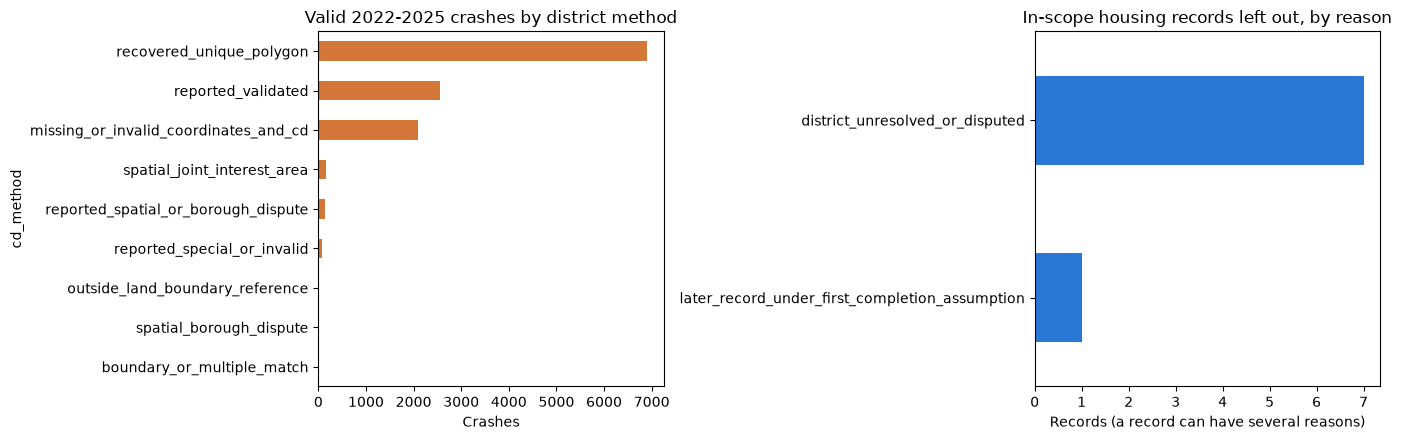

,valid_crashes,placed_in_district,share_placed
year,,,
2022,2879,2522,0.876
2023,3015,2334,0.774
2024,3116,2035,0.653
2025,2947,2567,0.871


In [43]:
scoped_crashes = pd.DataFrame([r for r in crash_rows if r["main_scope"]])
housing_reasons = pd.Series(collections.Counter(
    reason for r in housing_rows if r["main_scope"] for reason in r["primary_exclusion_reasons"].split("|") if reason))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
scoped_crashes["cd_method"].value_counts().sort_values().plot(kind="barh", ax=axes[0], color="#d27738")
axes[0].set_title("Valid 2022-2025 crashes by district method")
axes[0].set_xlabel("Crashes")
housing_reasons.sort_values().plot(kind="barh", ax=axes[1], color="#2a78d6")
axes[1].set_title("In-scope housing records left out, by reason")
axes[1].set_xlabel("Records (a record can have several reasons)")
plt.tight_layout()
plt.show()

coverage = scoped_crashes.groupby("year").agg(valid_crashes=("primary_eligible", "size"),
                                              placed_in_district=("primary_eligible", "sum"))
coverage["share_placed"] = (coverage["placed_in_district"] / coverage["valid_crashes"]).round(3)
coverage

### 7.3 Final outputs
All files are written to the `outputs/` folder:

| File | Contents |
|---|---|
| `data/integrated_district_year.csv` | the merged table: 236 district-years × 70 columns |
| `data/crashes_district_year_hour.csv` | crashes by district, year and hour (5,664 rows) |
| `data/housing_program_activity_district_year.csv` | housing programme activity by project start year |
| `data/housing_clean_all_records.csv`, `data/transport_clean_all_records.csv` | every source row, cleaned, with its flags and exclusion reasons |
| `data/housing_new_construction_2022_2025.csv`, `data/crashes_2022_2025_assigned.csv` | only the records counted in the totals |
| `data/housing_district_year.csv`, `data/crashes_district_year.csv` | each source summarised before the merge |
| `data/research_*.csv`, `data/Q1_*`, `data/Q2_*` | chart data written by the research-question sections (7.4, 7.9) |
| `audits/` | IQR thresholds, records left out with their reasons, yearly district coverage, check results |

In [44]:
data, audits = OUTPUT_ROOT / "data", OUTPUT_ROOT / "audits"
write_csv(data / "housing_clean_all_records.csv", housing_rows)
write_csv(data / "transport_clean_all_records.csv", crash_rows)
write_csv(data / "housing_new_construction_2022_2025.csv", housing_eligible_rows)
write_csv(data / "crashes_2022_2025_assigned.csv", crash_eligible_rows)
write_csv(data / "integrated_district_year.csv", integrated_rows)
write_csv(data / "housing_district_year.csv", [{"cd": k[0], "year": k[1]} | v for k, v in sorted(housing_by_key.items())])
write_csv(data / "crashes_district_year.csv", [{"cd": k[0], "year": k[1]} | v for k, v in sorted(crashes_by_key.items())])
write_csv(data / "crashes_district_year_hour.csv", hourly_rows)
write_csv(data / "housing_program_activity_district_year.csv", activity_rows)

pd.DataFrame(outlier_thresholds).to_csv(audits / "outlier_thresholds.csv", index=False)
housing_columns_out = ["source_row", "main_scope", "primary_exclusion_reasons", "completion_year", "cd_reported",
                       "cd_method", "Building ID", "Project ID", "Total Units"]
crash_columns_out = ["source_row", "main_scope", "primary_exclusion_reasons", "year", "cd_reported", "cd_method",
                     "Collision ID", "ksi"]
pd.DataFrame(housing_rows).query("not primary_eligible")[housing_columns_out].to_csv(audits / "housing_exclusions.csv", index=False)
pd.DataFrame(crash_rows).query("not primary_eligible")[crash_columns_out].to_csv(audits / "crash_exclusions.csv", index=False)
coverage.to_csv(audits / "district_coverage_by_year.csv")
check_results.to_csv(audits / "check_results.csv")

for path in sorted(data.glob("*.csv")) + sorted(audits.glob("*.csv")):
    print(f"{path.relative_to(OUTPUT_ROOT).as_posix():50s} {path.stat().st_size / 1e6:6.2f} MB")
print("\nAffordable units:", integrated_df["housing_affordable_units"].sum(),
      "| crash events:", integrated_df["crash_events"].sum())

data/crashes_2022_2025_assigned.csv                  2.22 MB
data/crashes_district_year.csv                       0.01 MB
data/crashes_district_year_hour.csv                  0.27 MB
data/housing_clean_all_records.csv                   4.51 MB
data/housing_district_year.csv                       0.03 MB
data/housing_new_construction_2022_2025.csv          0.76 MB
data/housing_program_activity_district_year.csv      0.10 MB
data/integrated_district_year.csv                    0.06 MB
data/transport_clean_all_records.csv                 3.35 MB
audits/check_results.csv                             0.00 MB
audits/crash_exclusions.csv                          0.42 MB
audits/district_coverage_by_year.csv                 0.00 MB
audits/housing_exclusions.csv                        0.90 MB
audits/outlier_thresholds.csv                        0.00 MB

Affordable units: 48026 | crash events: 9458


In [45]:
# The integrated table as a DataFrame. Every research-question section (7.4-7.10) starts from this `df`.
df = pd.DataFrame(shared.integrated).copy()

required_columns = [
    "cd", "borough", "year",
    "housing_source_records", "housing_affordable_units", "housing_total_units",
    "housing_identified_buildings", "housing_missing_building_id_records",
    "housing_affordable_units_known_records", "housing_affordable_share_of_reported_total",
    "crash_events",
]
missing = [c for c in required_columns if c not in df.columns]
if missing:
    raise KeyError(f"Missing columns: {missing}")
for col in required_columns:
    if col != "borough":
        df[col] = pd.to_numeric(df[col], errors="raise")

df = df[df["year"].between(2022, 2025)].copy()
assert not df.duplicated(["cd", "year"]).any()   # one row per district-year

print("Integrated observations:", len(df), "| community districts:", df["cd"].nunique(),
      "| years:", ", ".join(str(int(y)) for y in sorted(df["year"].unique())))

Integrated observations: 236 | community districts: 59 | years: 2022, 2023, 2024, 2025


### 7.4 Individual research questions: Yassin Amr Hegazy

1. Do housing completions and serious crashes peak in the same month?
2. Does the difference in peak months vary by borough?

The first chart shows the number of months between the two peaks, for NYC and each borough (2022–2025 combined). The label beside each bar shows the actual peak months. Only assigned, cleaned records from Sections 5-6 are used.

The second chart shows, for each borough, the share of its 2022-2025 housing completions and of its serious crashes that fell in each calendar month, so the two seasonal patterns can be compared directly.

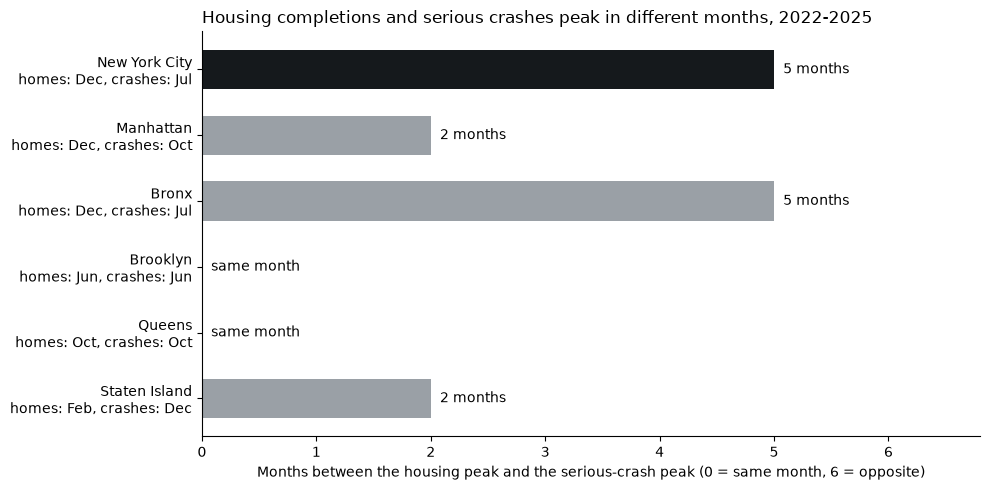

Chart data saved: data/research_monthly_comparison.csv


In [46]:
# Chart 1: months between the housing peak and the serious-crash peak, citywide and per borough.
areas = ['New York City', 'Manhattan', 'Bronx', 'Brooklyn', 'Queens', 'Staten Island']
months = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
housing_months = collections.Counter()   # completed units by (area, month)
crash_months = collections.Counter()     # serious crashes by (area, month)

for r in shared.hs:
    month = int(r['Building Completion Date'][5:7])
    housing_months[('New York City', month)] += r['Total Units']
    housing_months[(r['borough'], month)] += r['Total Units']

for r in shared.ts:
    month = int(r['Crash Date'][5:7])
    crash_months[('New York City', month)] += 1
    crash_months[(r['borough'], month)] += 1

labels, gaps, monthly_data = [], [], []
for area in areas:
    for m in range(1, 13):
        monthly_data.append({'area': area, 'month': months[m - 1],
                             'completed_units': housing_months[(area, m)],
                             'recorded_serious_crashes': crash_months[(area, m)]})
    h = max(range(1, 13), key=lambda m: housing_months[(area, m)])
    c = max(range(1, 13), key=lambda m: crash_months[(area, m)])
    difference = abs(h - c)
    gaps.append(min(difference, 12 - difference))   # months apart on a 12-month circle (0-6)
    labels.append(f'{area}\nhomes: {months[h - 1]}, crashes: {months[c - 1]}')

# The citywide bar is drawn dark and the boroughs grey, so the headline comparison stands out.
fig, ax = plt.subplots(figsize=(10, 5))
y_pos = np.arange(len(labels))[::-1]
colours = ['#15191c' if area == 'New York City' else '#9aa0a6' for area in areas]
ax.barh(y_pos, gaps, color=colours, height=0.6)
for y, gap in zip(y_pos, gaps):
    ax.text(gap + 0.08, y, 'same month' if gap == 0 else f'{gap} months', va='center', fontsize=10)
ax.set_yticks(y_pos, labels)
ax.set_xlim(0, 6.8)
ax.set_xticks(range(7))
ax.set_xlabel('Months between the housing peak and the serious-crash peak (0 = same month, 6 = opposite)')
ax.set_title('Housing completions and serious crashes peak in different months, 2022-2025', loc='left')
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()

write_csv(OUTPUT_ROOT / 'data' / 'research_monthly_comparison.csv', monthly_data)
print('Chart data saved: data/research_monthly_comparison.csv')

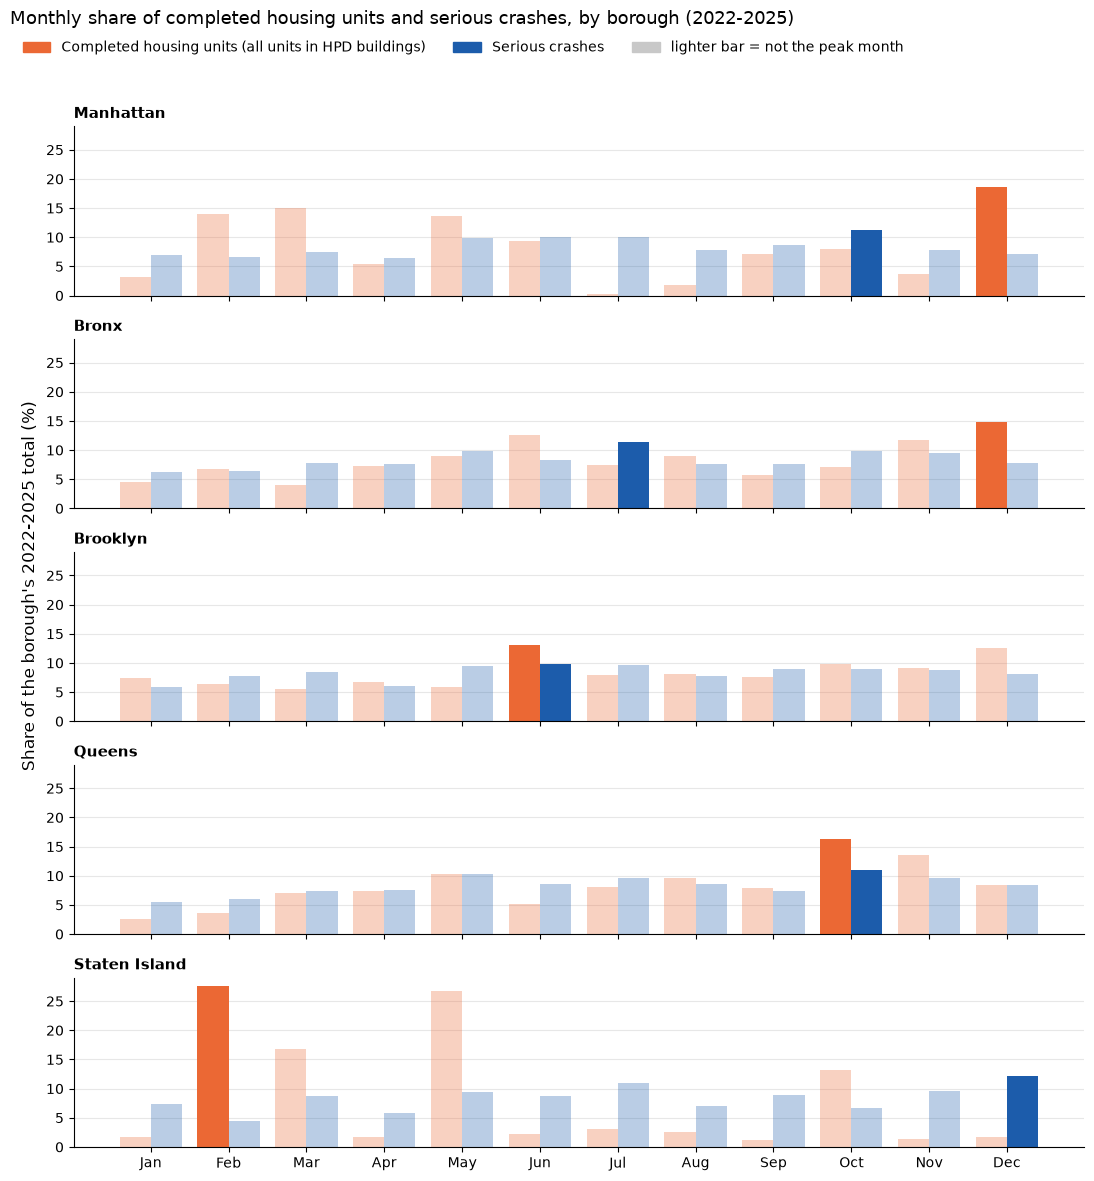

Chart data saved: data/research_seasonal_borough_comparison.csv


In [47]:
# Chart 2: each month's share of the borough's 2022-2025 completed units and serious crashes.
# The peak month of each series is drawn in full colour and the other months lighter, so the two
# peaks can be compared at a glance.
from matplotlib.colors import to_rgba
from matplotlib.patches import Patch

boroughs = areas[1:]
HOUSING_COLOUR, CRASH_COLOUR = '#eb6834', '#1c5cab'
x = np.arange(12)
seasonal_rows = []

fig, axes = plt.subplots(len(boroughs), 1, figsize=(11, 12), sharex=True, sharey=True)
for ax, b in zip(axes, boroughs):
    units = np.array([housing_months[(b, m)] for m in range(1, 13)], dtype=float)
    crashes = np.array([crash_months[(b, m)] for m in range(1, 13)], dtype=float)
    unit_pct = 100 * units / (units.sum() or 1)
    crash_pct = 100 * crashes / (crashes.sum() or 1)
    for values, offset, colour in [(unit_pct, -0.2, HOUSING_COLOUR), (crash_pct, 0.2, CRASH_COLOUR)]:
        shades = [to_rgba(colour, 1.0 if v == values.max() else 0.3) for v in values]
        ax.bar(x + offset, values, width=0.4, color=shades)
    ax.set_title(b, loc='left', fontsize=11, fontweight='bold')
    ax.grid(axis='y', alpha=0.3)
    ax.set_axisbelow(True)
    ax.spines[['top', 'right']].set_visible(False)
    seasonal_rows += [{'borough': b, 'month': months[m], 'housing_pct': round(unit_pct[m], 2),
                       'crash_pct': round(crash_pct[m], 2)} for m in range(12)]

axes[-1].set_xticks(x, months)
fig.supylabel('Share of the borough\'s 2022-2025 total (%)')
fig.suptitle('Monthly share of completed housing units and serious crashes, by borough (2022-2025)',
             x=0.01, ha='left', fontsize=13)
fig.legend(handles=[Patch(color=HOUSING_COLOUR, label='Completed housing units (all units in HPD buildings)'),
                    Patch(color=CRASH_COLOUR, label='Serious crashes'),
                    Patch(color='#c8c8c8', label='lighter bar = not the peak month')],
           loc='upper left', bbox_to_anchor=(0.01, 0.965), ncol=3, frameon=False)
fig.tight_layout(rect=(0, 0, 1, 0.94))
plt.show()

write_csv(OUTPUT_ROOT / 'data' / 'research_seasonal_borough_comparison.csv', seasonal_rows)
print('Chart data saved: data/research_seasonal_borough_comparison.csv')

In [48]:
# Monthly shares quoted in the findings: % of each area's 2022-2025 completed units and serious crashes.
import pandas as pd

monthly = pd.DataFrame(monthly_data)
for col, name in [("completed_units", "units %"), ("recorded_serious_crashes", "crashes %")]:
    monthly[name] = 100 * monthly[col] / monthly.groupby("area")[col].transform("sum")

monthly_shares = (
    monthly.pivot(index="month", columns="area", values=["units %", "crashes %"])
    .reindex(index=months)
    .reindex(columns=areas, level=1)
    .round(1)
)
display(monthly_shares)

# Do the two monthly patterns move together? Rank correlation of the 12 monthly shares per area.
from scipy.stats import spearmanr

for area in areas:
    part = monthly[monthly["area"] == area]
    rho, p = spearmanr(part["units %"], part["crashes %"])
    print(f"{area}: monthly units share vs crash share, Spearman rho = {rho:.2f} (p = {p:.2f})")

units %                                                \
area  New York City Manhattan Bronx Brooklyn Queens Staten Island   
month                                                               
Jan             5.0       3.1   4.5      7.3    2.7           1.7   
Feb             7.0      14.1   6.7      6.3    3.6          27.6   
Mar             6.7      15.0   4.0      5.5    7.0          16.8   
Apr             6.8       5.4   7.3      6.7    7.4           1.7   
May             8.8      13.7   8.9      5.9   10.4          26.7   
Jun            10.8       9.4  12.6     13.1    5.2           2.2   
Jul             6.8       0.2   7.5      7.9    8.2           3.1   
Aug             7.8       1.7   9.0      8.1    9.5           2.6   
Sep             7.0       7.2   5.8      7.6    7.8           1.2   
Oct            10.2       8.0   7.1      9.9   16.4          13.2   
Nov            10.0       3.6  11.8      9.1   13.5           1.4   
Dec            13.1      18.5  14.8     12.5    8.5           1.7   

          crashes %                                                
area  New York City Manhattan Bronx Brooklyn Queens Staten Island  
month                                                              
Jan             6.2       6.9   6.3      5.9    5.6           7.4  
Feb             6.7       6.6   6.5      7.7    6.0           4.5  
Mar             7.9       7.6   7.9      8.5    7.4           8.7  
Apr             6.8       6.4   7.6      6.1    7.5           5.8  
May             9.8       9.8   9.8      9.5   10.3           9.4  
Jun             9.2      10.1   8.3      9.8    8.7           8.7  
Jul            10.1      10.0  11.3      9.7    9.7          11.0  
Aug             7.9       7.9   7.6      7.8    8.5           7.0  
Sep             8.2       8.6   7.6      9.0    7.4           9.0  
Oct            10.0      11.3   9.9      8.9   11.0           6.7  
Nov             9.0       7.8   9.5      8.9    9.7           9.6  
Dec             8.1       7.1   7.8      8.1    8.3          12.1

New York City: monthly units share vs crash share, Spearman rho = 0.49 (p = 0.11)
Manhattan: monthly units share vs crash share, Spearman rho = -0.15 (p = 0.65)
Bronx: monthly units share vs crash share, Spearman rho = 0.39 (p = 0.21)
Brooklyn: monthly units share vs crash share, Spearman rho = 0.32 (p = 0.31)
Queens: monthly units share vs crash share, Spearman rho = 0.85 (p = 0.00)
Staten Island: monthly units share vs crash share, Spearman rho = -0.32 (p = 0.31)


**Findings.**

*Question 1: Do housing completions and serious crashes peak in the same month?* **No, not citywide.**
- Housing completions peak in **December**: 13.1% of the 2022-2025 completed units, compared with 5.0% in January. Many buildings appear to be finished just before the end of the calendar year.
- Serious crashes peak in **July** (10.1% of crashes), with a second high point in October (10.0%). The two peaks are **5 months apart**.
- Crashes are spread much more evenly through the year than completions. Their monthly share only ranges from 6.2% to 10.1%, while completions range from 5.0% to 13.1%.
- Over all twelve months the two patterns are only loosely related citywide (Spearman rho = 0.49, p = 0.11, not statistically significant).

*Question 2: Does the difference in peak months vary by borough?* **Yes, but most of the difference comes from where housing peaks, not crashes.**
- The peaks match in **Brooklyn** (June) and **Queens** (October), are 2 months apart in **Manhattan** and **Staten Island**, and 5 months apart in the **Bronx** (December vs July).
- Crash timing is similar in every borough: each borough's monthly crash share stays between 4.5% and 12.1%, with highs mostly in May-July and October. Housing timing differs a lot: 27.6% of Staten Island's units were completed in February alone, while Manhattan's largest month is December (18.5%) and it had almost no completions in July (0.2%).
- Because crash shares are so flat, the crash "peak month" can change with a few crashes. Brooklyn's crash shares for May, June and July are 9.5%, 9.8% and 9.7%. A matching peak month is therefore weak evidence of a real link. Across all twelve months, only **Queens** moves clearly together (Spearman rho = 0.85, p < 0.01); Brooklyn (0.32) and the Bronx (0.39) are weak and not significant, and Manhattan (-0.15) and Staten Island (-0.32) run slightly opposite.

**Limitations.** A single peak month ignores the rest of the year. Completion dates are not move-in dates. Units here are all units in HPD-recorded buildings (affordable and market-rate). Staten Island's housing pattern rests on very few completions. Crash counts are not adjusted for traffic volume.

**So what for NYC.** Completions and serious crashes do not follow a shared seasonal rhythm. Seasonal street-safety campaigns should be timed to the crash season (late spring to summer, and October) rather than to when new buildings open.

### 7.5 Individual research questions: Mohammed Fady Rizk

Two questions comparing where affordable housing is built, and at what building size, with recorded serious crashes. Both use the integrated district-year table (`shared.integrated`) produced above.

#### Geographical Distribution of Affordable Housing and Traffic Crashes

**Research Question:** How does the geographical distribution of completed affordable housing compare with the distribution of reported serious traffic crashes?

**Objective:** Compare the relative geographical distribution of affordable housing units and recorded crash events across boroughs.

**Method:** Aggregate the integrated district-year housing and crash totals by borough, then convert each measure into a percentage of its overall total.

**Visualization:** Grouped bar chart.

**Interpretation:** The chart identifies differences in geographical distribution. It does not estimate crash risk or establish causation.

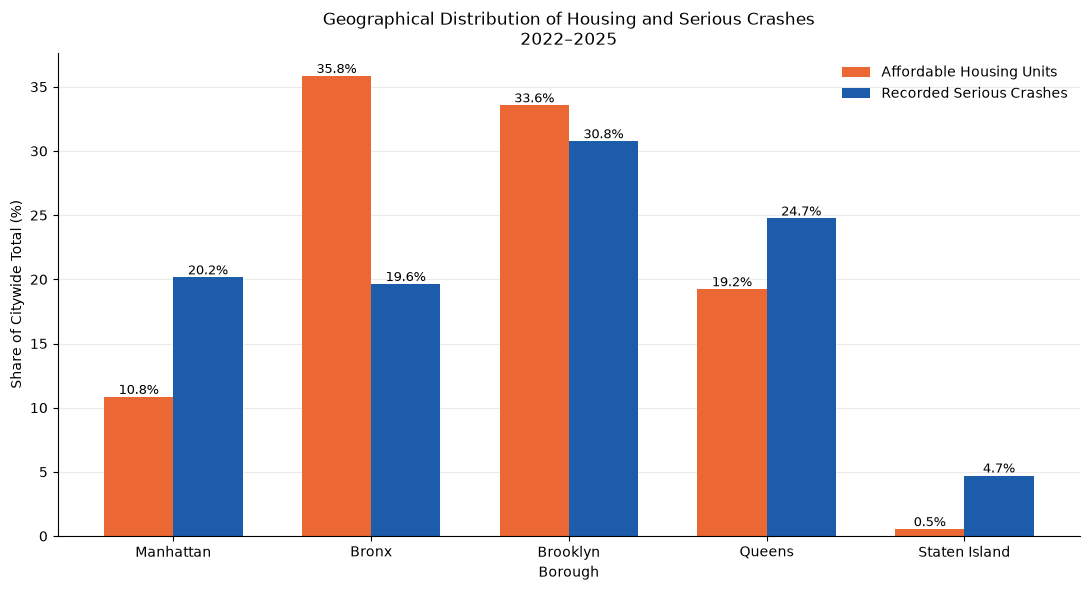

,housing_units,crashes,Housing Share (%),Crash Share (%),Gap (pp)
borough,,,,,
Manhattan,5205,1906,10.84,20.15,-9.31
Bronx,17213,1857,35.84,19.63,16.21
Brooklyn,16115,2909,33.55,30.76,2.80
Queens,9235,2340,19.23,24.74,-5.51
Staten Island,258,446,0.54,4.72,-4.18


Index of dissimilarity: 19.0


In [49]:
# RQ1 — Borough distribution comparison

rq1 = (
    df.groupby("borough", as_index=False)
    .agg(
        housing_units=("housing_affordable_units", "sum"),
        crashes=("crash_events", "sum")
    )
)

assert rq1["housing_units"].sum() > 0
assert rq1["crashes"].sum() > 0

rq1["Housing Share (%)"] = (
    100 * rq1["housing_units"]
    / rq1["housing_units"].sum()
)

rq1["Crash Share (%)"] = (
    100 * rq1["crashes"]
    / rq1["crashes"].sum()
)

# Fixed borough order, used in every chart of this section
borough_order = [
    "Manhattan", "Bronx", "Brooklyn",
    "Queens", "Staten Island"
]

rq1 = rq1.set_index("borough").reindex(borough_order)

x = np.arange(len(rq1))
width = 0.35

fig, ax = plt.subplots(figsize=(11, 6))

housing_bars = ax.bar(
    x - width / 2,
    rq1["Housing Share (%)"],
    width,
    label="Affordable Housing Units",
    color="#eb6834"
)

crash_bars = ax.bar(
    x + width / 2,
    rq1["Crash Share (%)"],
    width,
    label="Recorded Serious Crashes",
    color="#1c5cab"
)

# Percentages on the bars, so the gap in each borough can be read directly
ax.bar_label(housing_bars, fmt="%.1f%%", fontsize=9)
ax.bar_label(crash_bars, fmt="%.1f%%", fontsize=9)

ax.set_xticks(x)
ax.set_xticklabels(borough_order)
ax.set_xlabel("Borough")
ax.set_ylabel("Share of Citywide Total (%)")
ax.set_title(
    "Geographical Distribution of Housing and Serious Crashes\n"
    "2022–2025"
)

ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

rq1["Gap (pp)"] = rq1["Housing Share (%)"] - rq1["Crash Share (%)"]
display(rq1.round(2))

# Index of dissimilarity: the share of units that would have to move borough for the housing
# distribution to match the crash distribution (0 = identical, 100 = completely different).
dissimilarity = 0.5 * rq1["Gap (pp)"].abs().sum()
print(f"Index of dissimilarity: {dissimilarity:.1f}")

**Findings.**
- Affordable housing and serious crashes are **distributed differently across boroughs**. The **Bronx** received **35.8%** of the city's completed affordable units but recorded **19.6%** of serious crashes. **Manhattan** shows the opposite: 10.8% of units against 20.2% of crashes.
- **Brooklyn** is the closest match: 33.6% of units and 30.8% of crashes. **Queens** has a larger share of crashes (24.7%) than of units (19.2%).
- **Staten Island** received only 0.5% of affordable units (258 units) but recorded 4.7% of serious crashes.
- The index of dissimilarity is **19.0**: about a fifth of the affordable units would have to be in a different borough for the two distributions to match.
- So new affordable housing is concentrated in the Bronx and Brooklyn, while the serious-crash burden is spread more evenly across the boroughs.

**Limitations.** Borough shares hide large differences between districts inside each borough. Counts are not adjusted for population, road length or traffic volume, so a borough's crash share partly reflects its size. Housing covers HPD-recorded New Construction completions only, and crashes only the SIRTA events that could be placed in a district. The comparison shows where each measure is concentrated, not that one affects the other.

**So what for NYC.** Affordable-housing production is not following the crash map. Boroughs with large crash shares but little new housing, such as Manhattan, Queens and Staten Island, need street-safety programmes that are not tied to housing completions. The Bronx's large housing pipeline is a chance to pair new buildings with street redesign.

#### Average Affordable Housing Development Size and Crash Frequency

**Research Question:** Is the average number of affordable units per completed building associated with the frequency of reported serious traffic crashes?

**Objective:** Examine the relationship between the average counted affordable units per identified building and reported crash-event frequency across community district-years.

**Method:** Select observations with valid housing-unit totals and complete building identification. Divide counted affordable units by the number of identified buildings, then compare this measure against recorded crash events.

**Visualization:** Scatter plot with a linear trend line.

**Interpretation:** The chart describes an area-level association rather than an individual-building effect. Differences in geographic size and traffic activity may influence the observed relationship.

Eligible district-year observations: 60 of 218 with completions
Eligible observations by borough: {'Brooklyn': 28, 'Manhattan': 14, 'Bronx': 13, 'Queens': 5}
Units per building: min 2.0 | median 31.8 | max 183.0


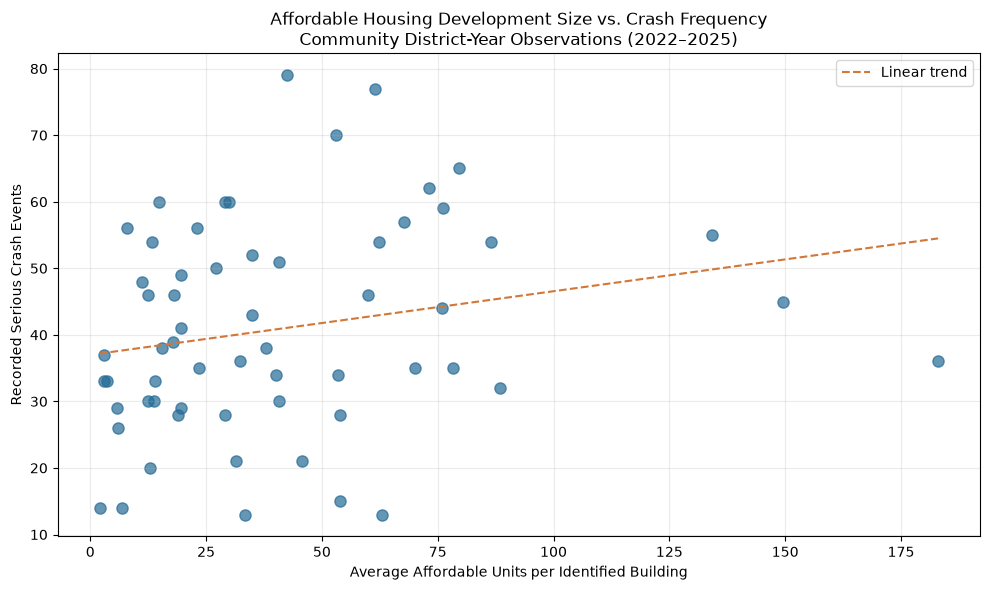

Pearson correlation: 0.218


,cd,borough,year,Units per Building,crash_events
40,111,Manhattan,2022,183.0,36
172,402,Queens,2022,149.5,45
115,305,Brooklyn,2025,134.2,55
46,112,Manhattan,2024,88.5,32
43,111,Manhattan,2025,86.4,54


In [50]:
# RQ2 — Average affordable units per building

rq2 = df[
    (df["housing_identified_buildings"] > 0) &
    (df["housing_missing_building_id_records"] == 0) &
    (
        df["housing_affordable_units_known_records"]
        == df["housing_source_records"]
    )
].copy()

rq2["Units per Building"] = (
    rq2["housing_affordable_units"]
    / rq2["housing_identified_buildings"]
)

x = rq2["Units per Building"]
y = rq2["crash_events"]

print("Eligible district-year observations:", len(rq2),
      "of", int((df["housing_source_records"] > 0).sum()), "with completions")
print("Eligible observations by borough:", rq2["borough"].value_counts().to_dict())
print("Units per building: min", round(x.min(), 1),
      "| median", round(x.median(), 1), "| max", round(x.max(), 1))

if len(rq2) >= 3 and x.nunique() > 1 and y.nunique() > 1:

    fig, ax = plt.subplots(figsize=(10, 6))

    ax.scatter(
        x, y,
        color="#246a95",
        s=65,
        alpha=0.7
    )

    # Linear trend for exploratory comparison
    slope, intercept = np.polyfit(x, y, 1)

    trend_x = np.linspace(x.min(), x.max(), 100)

    ax.plot(
        trend_x,
        slope * trend_x + intercept,
        linestyle="--",
        color="#d27738",
        label="Linear trend"
    )

    ax.set_xlabel("Average Affordable Units per Identified Building")
    ax.set_ylabel("Recorded Serious Crash Events")
    ax.set_title(
        "Affordable Housing Development Size vs. Crash Frequency\n"
        "Community District-Year Observations (2022–2025)"
    )

    ax.grid(alpha=0.25)
    ax.legend()

    plt.tight_layout()
    plt.show()

    print("Pearson correlation:", round(x.corr(y), 3))

else:
    print("Insufficient variation for a meaningful scatter plot.")

display(
    rq2[[
        "cd", "borough", "year",
        "Units per Building", "crash_events"
    ]].sort_values("Units per Building", ascending=False).head(5).round(2)
)

**Findings.**
- There is a **weak positive association** (Pearson r = 0.22) between the average number of affordable units per building and serious crash events. District-years with larger buildings recorded slightly more crashes, but the relationship is too weak to rely on with 60 observations.
- Only **60 of the 218** district-years with completions pass the data-completeness filter (every record has a building ID and a known affordable-unit count). These 60 contain no Staten Island observations and are nearly half Brooklyn (28), so the result may not hold citywide.
- Building size varies widely, from 2 to 183 affordable units per building (median 32). The single 183-unit observation (Manhattan district 11, 2022) has a large influence on the trend line.

**Limitations.** Larger buildings tend to be built in denser districts, which also have more traffic. The weak link may therefore reflect density rather than building size. Crash counts are not adjusted for district population or traffic volume.

**So what for NYC.** Building size is not a useful signal for where serious crashes happen. Street-safety reviews for large developments should be based on local crash history, not on project size alone.

### 7.6 Individual research questions: Sam Shady Samih Soliman Bostawros

Two questions on the type of affordable housing being built: the affordable share of units and the dominant housing programme (New Construction vs Preservation), each compared with recorded serious crashes. They reuse the integrated table `df` and the housing activity summary (`shared.activity`).

#### Affordable Housing Proportion and Crash Frequency

**Research Question:** Does the proportion of affordable units within completed housing developments relate to the frequency of reported serious traffic crashes?

**Objective:** Investigate whether the share of counted affordable units within completed housing developments is associated with recorded crash frequency.

**Method:** Use the affordability-share measure calculated during integration (Section 6). Compare it with recorded crashes across eligible community district-years.

**Visualization:** Scatter plot.

**Interpretation:** The relationship is descriptive and does not measure individual residents' crash risk or imply a causal effect.

Eligible district-year observations: 218
Distinct affordability shares: 175
Affordable share (%): min 21.3 | median 49.4 | max 100.0


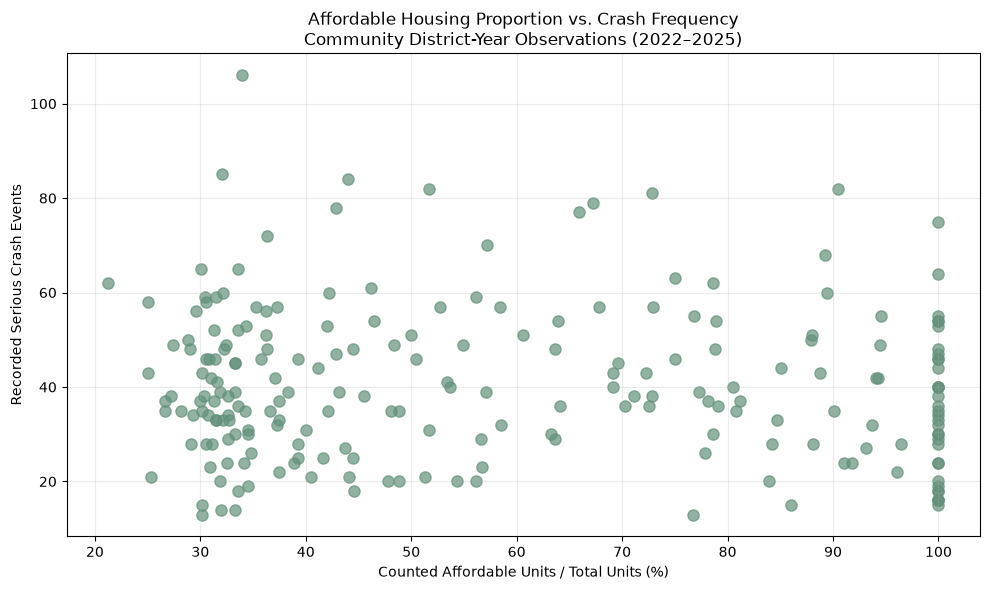

Pearson correlation: -0.064


,cd,borough,year,Affordable Share (%),crash_events
1,101,Manhattan,2023,30.14,13
4,102,Manhattan,2022,28.14,35
8,103,Manhattan,2022,75.00,46
9,103,Manhattan,2023,30.51,46
10,103,Manhattan,2024,53.70,40
11,103,Manhattan,2025,80.80,35
12,104,Manhattan,2022,21.26,62
13,104,Manhattan,2023,25.03,58
14,104,Manhattan,2024,27.19,38
15,104,Manhattan,2025,27.43,49


In [51]:
# RQ3 — Affordable housing proportion

rq3 = df[
    (df["housing_source_records"] > 0) &
    df["housing_affordable_share_of_reported_total"].notna()
].copy()

rq3["Affordable Share (%)"] = (
    100 * rq3["housing_affordable_share_of_reported_total"]
)

# Validate the range
rq3 = rq3[
    rq3["Affordable Share (%)"].between(0, 100)
].copy()

x = rq3["Affordable Share (%)"]
y = rq3["crash_events"]

print("Eligible district-year observations:", len(rq3))
print("Distinct affordability shares:", x.nunique())
print("Affordable share (%): min", round(x.min(), 1),
      "| median", round(x.median(), 1), "| max", round(x.max(), 1))

if len(rq3) >= 3 and x.nunique() > 1 and y.nunique() > 1:

    fig, ax = plt.subplots(figsize=(10, 6))

    ax.scatter(
        x, y,
        color="#62917a",
        s=65,
        alpha=0.7
    )

    ax.set_title(
        "Affordable Housing Proportion vs. Crash Frequency\n"
        "Community District-Year Observations (2022–2025)"
    )
    ax.set_xlabel("Counted Affordable Units / Total Units (%)")
    ax.set_ylabel("Recorded Serious Crash Events")

    ax.grid(alpha=0.25)

    plt.tight_layout()
    plt.show()

    print("Pearson correlation:", round(x.corr(y), 3))

else:
    print("Insufficient variation for a meaningful relationship.")

display(
    rq3[[
        "cd", "borough", "year",
        "Affordable Share (%)", "crash_events"
    ]].head(10).round(2)
)

**Findings.**
- There is **no meaningful relationship** between the affordable share of units and serious crash events (Pearson r = -0.06 across 218 district-years with completions).
- Affordable shares range from 21% to 100% (median 49%), so the absence of a pattern is not caused by a lack of variation.
- District-years that built almost entirely affordable housing recorded about as many serious crashes as those where affordable units were a minority.

**Limitations.** The share describes only HPD-recorded buildings, not all housing in a district. Crash counts are not adjusted for traffic volume or population.

**So what for NYC.** Whether new buildings are fully affordable or mixed-income shows no link with the number of serious crashes recorded in the district. Safety resources should not be allocated on the basis of the affordable/market-rate mix.

#### Housing Activity Type and Crash Frequency

**Research Question:** Do areas dominated by new construction activity and areas dominated by housing preservation activity differ in their reported serious traffic crash frequency?

**Objective:** Compare recorded crash frequency between community district-years characterized by New Construction activity and those characterized by Preservation activity.

**Method:** Use the housing programme activity table from Section 6. Classify each district-year according to which activity type has more housing source records, then match that classification with the district-year crash totals.

**Visualization:** Box plot.

**Interpretation:** Housing activity is measured using administrative project-start information, not physical construction commencement. Differences between categories are associations, not evidence that either activity type causes changes in traffic safety.

District-years in the integrated table: 236
District-years with New Construction or Preservation starts: 226
Ties left out: 14
New Construction observations: 166
Preservation observations: 46


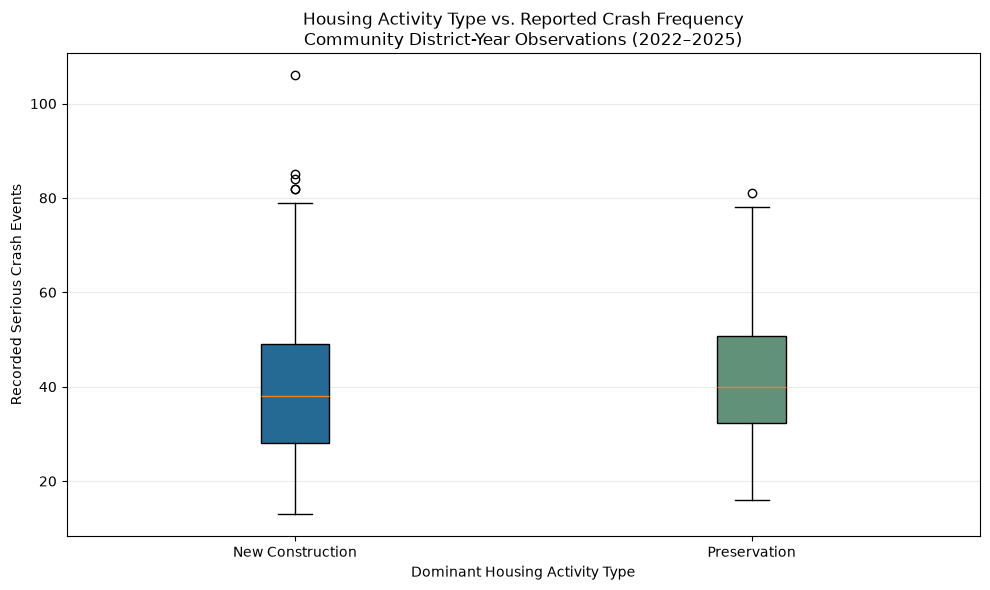

,count,mean,25%,50%,75%,max
Dominant Type,,,,,,
New Construction,166.0,40.19,28.00,38.0,49.00,106.0
Preservation,46.0,42.85,32.25,40.0,50.75,81.0


In [52]:
# RQ4 — New Construction vs Preservation

activity = pd.DataFrame(shared.activity).copy()

required_activity = [
    "cd", "project_start_year",
    "construction_type", "housing_source_records"
]

missing = [c for c in required_activity if c not in activity.columns]
if missing:
    raise KeyError(f"Missing activity columns: {missing}")

activity["cd"] = pd.to_numeric(activity["cd"], errors="raise")
activity["project_start_year"] = pd.to_numeric(
    activity["project_start_year"], errors="raise"
)
activity["housing_source_records"] = pd.to_numeric(
    activity["housing_source_records"], errors="raise"
)

activity = activity[
    activity["construction_type"].isin(
        ["New Construction", "Preservation"]
    )
].copy()

# Combine administrative activity across the other
# classification dimensions already present in shared.activity
activity_summary = (
    activity.groupby(
        ["cd", "project_start_year", "construction_type"],
        as_index=False
    )["housing_source_records"].sum()
)

# Create one row per district-year
activity_wide = activity_summary.pivot_table(
    index=["cd", "project_start_year"],
    columns="construction_type",
    values="housing_source_records",
    aggfunc="sum",
    fill_value=0
).reset_index()

for col in ["New Construction", "Preservation"]:
    if col not in activity_wide.columns:
        activity_wide[col] = 0

activity_wide["Dominant Type"] = np.select(
    [
        activity_wide["New Construction"]
        > activity_wide["Preservation"],

        activity_wide["Preservation"]
        > activity_wide["New Construction"]
    ],
    [
        "New Construction",
        "Preservation"
    ],
    default="Equal"
)

# Both tables contain a unique district-year
rq4 = activity_wide.merge(
    df[["cd", "year", "crash_events"]],
    left_on=["cd", "project_start_year"],
    right_on=["cd", "year"],
    how="inner",
    validate="one_to_one"
)

print("District-years in the integrated table:", len(df))
print("District-years with New Construction or Preservation starts:", len(rq4))
print("Ties left out:", int((rq4["Dominant Type"] == "Equal").sum()))

# Exclude tied categories
rq4 = rq4[
    rq4["Dominant Type"] != "Equal"
].copy()

new = rq4.loc[
    rq4["Dominant Type"] == "New Construction",
    "crash_events"
]

preservation = rq4.loc[
    rq4["Dominant Type"] == "Preservation",
    "crash_events"
]

print("New Construction observations:", len(new))
print("Preservation observations:", len(preservation))

if len(new) > 0 and len(preservation) > 0:

    fig, ax = plt.subplots(figsize=(10, 6))

    box = ax.boxplot(
        [new, preservation],
        patch_artist=True
    )

    ax.set_xticks([1, 2])
    ax.set_xticklabels(["New Construction", "Preservation"])

    box["boxes"][0].set_facecolor("#246a95")
    box["boxes"][1].set_facecolor("#62917a")

    ax.set_title(
        "Housing Activity Type vs. Reported Crash Frequency\n"
        "Community District-Year Observations (2022–2025)"
    )
    ax.set_xlabel("Dominant Housing Activity Type")
    ax.set_ylabel("Recorded Serious Crash Events")

    ax.grid(axis="y", alpha=0.25)

    plt.tight_layout()
    plt.show()

else:
    print("Insufficient observations for both activity types.")

display(
    rq4.groupby("Dominant Type")["crash_events"]
    .describe()[["count", "mean", "25%", "50%", "75%", "max"]]
    .round(2)
)

**Findings.**
- **New Construction** dominated **166** district-years and **Preservation** dominated **46**. The other 24 of the 236 district-years are left out: 14 are ties and 10 had no New Construction or Preservation project starts.
- Crash frequency is very similar in the two groups. New Construction district-years recorded a median of **38** serious crash events (mean 40.2). Preservation district-years recorded a median of **40** (mean 42.9).
- The boxes overlap almost completely: the middle half of district-years ranges from 28 to 49 events for New Construction and from 32 to 51 for Preservation. The single highest value (106 events) is a New Construction district-year, the larger group.
- The 2-event difference in medians is small compared with this spread, so the two programme types cannot be told apart by crash frequency.

**Limitations.** Activity type is classified by project start year, while crashes are counted by crash year, so the two refer to the same calendar year but not to physical construction activity on the ground. The groups are unequal in size (166 vs 46).

**So what for NYC.** Building new housing and preserving existing housing are associated with similar levels of serious crashes. Street-safety planning should not treat either programme type as a higher-risk signal.

### 7.7 Individual research questions: Marawan Mohamed Elgendy

Two research questions linking affordable-housing completions to serious-injury crashes at community-district level. The section first validates the integrated table and checks a data limitation that decides which crash outcome can be used.

In [53]:
# Libraries for sections 7.7 and 7.8
import plotly.express as px
import plotly.graph_objects as go
from scipy.stats import spearmanr, theilslopes
import plotly.io as pio

# Also store a static image of every Plotly chart, so the charts still show where the interactive
# version cannot run (GitHub, nbviewer, PDF export). Skipped if the image library is not installed.
try:
    import kaleido  # noqa: F401
    pio.renderers.default = pio.renderers.default + "+png"
    pio.renderers["png"].width, pio.renderers["png"].height = 1000, 650
except ImportError:
    pass

# `df` is the integrated district x year table created earlier in the notebook.
# Structural checks on it before analysing (all should be True).
BOROUGH_BY_CD_PREFIX = {1: "Manhattan", 2: "Bronx", 3: "Brooklyn", 4: "Queens", 5: "Staten Island"}

def run_integrated_checks(frame):
    """Return a pass/fail table of structural checks on the district x year table."""
    count_cols = ["housing_total_units", "housing_affordable_units", "housing_projects",
                  "crash_events", "severe_injuries", "fatalities", "ksi"]
    structural_null_cols = ["housing_median_total_units_per_record",
                            "housing_affordable_share_of_reported_total"]
    nulls = frame.isna().sum()
    unexpected_nulls = nulls[(nulls > 0) & ~nulls.index.isin(structural_null_cols)]
    no_housing_rows = frame["housing_total_units"].eq(0)
    structural_ok = frame.loc[~no_housing_rows, structural_null_cols].notna().all().all()
    checks = {
        "236 rows (59 districts x 4 years)": len(frame) == 236,
        "59 unique community districts": frame["cd"].nunique() == 59,
        "years are exactly 2022-2025": sorted(frame["year"].unique()) == [2022, 2023, 2024, 2025],
        "no duplicate (cd, year) keys": not frame.duplicated(["cd", "year"]).any(),
        "borough agrees with first digit of cd": (frame["cd"] // 100).map(BOROUGH_BY_CD_PREFIX).eq(frame["borough"]).all(),
        "count columns are non-negative integers": all((frame[c] >= 0).all() and (frame[c] % 1 == 0).all() for c in count_cols),
        "ksi == severe_injuries + fatalities": (frame["ksi"] == frame["severe_injuries"] + frame["fatalities"]).all(),
        "affordable units <= total units": (frame["housing_affordable_units"] <= frame["housing_total_units"]).all(),
        "no unexpected nulls": unexpected_nulls.empty,
        "structural nulls only where housing = 0": bool(structural_ok),
    }
    return pd.DataFrame({"check": checks.keys(), "passed": checks.values()})

display(run_integrated_checks(df))

,check,passed
0,236 rows (59 districts x 4 years),True
1,59 unique community districts,True
2,years are exactly 2022-2025,True
3,"no duplicate (cd, year) keys",True
4,borough agrees with first digit of cd,True
5,count columns are non-negative integers,True
6,ksi == severe_injuries + fatalities,True
7,affordable units <= total units,True
8,no unexpected nulls,True
9,structural nulls only where housing = 0,True


#### Data-limitation check: do fatalities and serious injuries survive district assignment in every year?

year,2022,2023,2024,2025
records,2879.0,3016.0,3116.0,2947.0
fatal_records,245.0,237.0,232.0,211.0
fatalities_in_source,255.0,247.0,248.0,225.0
severe_injuries_in_source,2863.0,3021.0,3145.0,3029.0
pct_nonfatal_with_coords,89.5,88.5,71.6,94.9
pct_fatal_with_coords,84.1,0.0,0.0,0.0
pct_nonfatal_assigned_to_cd,88.3,83.7,70.4,93.6
pct_fatal_assigned_to_cd,79.6,3.0,1.7,2.4
fatalities_in_integrated,203.0,9.0,4.0,5.0
severe_injuries_in_integrated,2527.0,2511.0,2200.0,2801.0


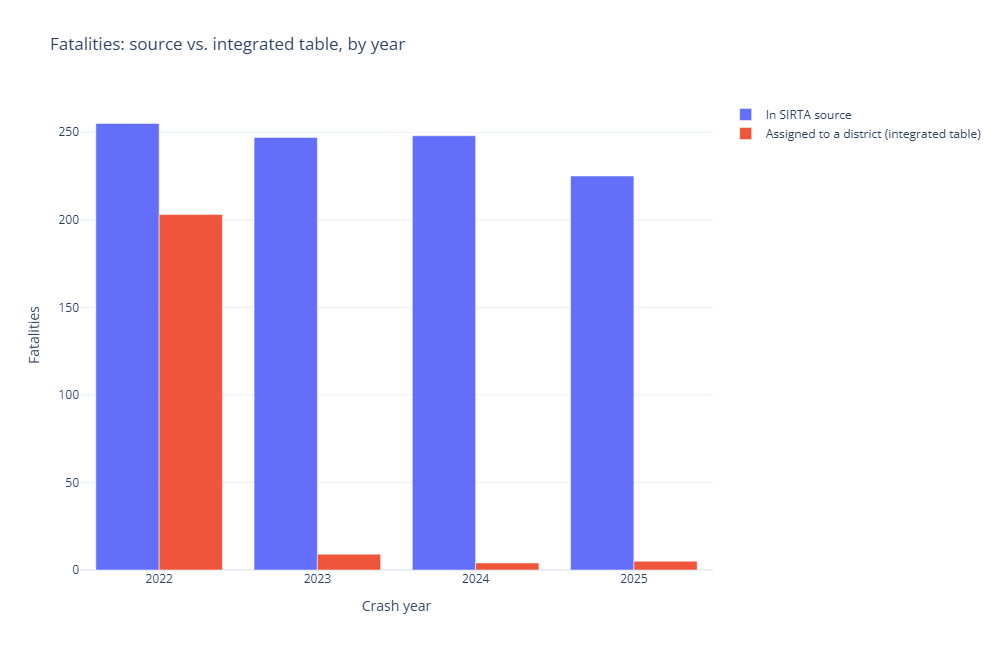

In [54]:
raw_crashes = pd.read_csv(OUTPUT_ROOT / "data" / "transport_clean_all_records.csv", low_memory=False)
scope = raw_crashes[raw_crashes["year"].between(2022, 2025)].copy()
scope["year"] = scope["year"].astype(int)  # source stores year as float
scope["fatalities_raw"] = pd.to_numeric(scope["Total Fatalities"], errors="coerce").fillna(0)
scope["severe_raw"] = pd.to_numeric(scope["Total Severe Injuries"], errors="coerce").fillna(0)
scope["has_coords"] = scope["Latitude"].notna() & scope["Longitude"].notna()
scope["is_fatal"] = scope["fatalities_raw"] > 0

def pct(series):
    return (100 * series.mean()).round(1)

by_year = scope.groupby("year").agg(
    records=("is_fatal", "size"),
    fatal_records=("is_fatal", "sum"),
    fatalities_in_source=("fatalities_raw", "sum"),
    severe_injuries_in_source=("severe_raw", "sum"),
)
by_year["pct_nonfatal_with_coords"] = scope[~scope["is_fatal"]].groupby("year")["has_coords"].apply(pct)
by_year["pct_fatal_with_coords"] = scope[scope["is_fatal"]].groupby("year")["has_coords"].apply(pct)
by_year["pct_nonfatal_assigned_to_cd"] = scope[~scope["is_fatal"]].groupby("year")["primary_eligible"].apply(pct)
by_year["pct_fatal_assigned_to_cd"] = scope[scope["is_fatal"]].groupby("year")["primary_eligible"].apply(pct)

integrated_by_year = df.groupby("year")[["fatalities", "severe_injuries"]].sum()
integrated_by_year.columns = ["fatalities_in_integrated", "severe_injuries_in_integrated"]
coverage_check = by_year.join(integrated_by_year)
coverage_check["severe_injury_capture_pct"] = (
    100 * coverage_check["severe_injuries_in_integrated"] / coverage_check["severe_injuries_in_source"]).round(1)
coverage_check["fatality_capture_pct"] = (
    100 * coverage_check["fatalities_in_integrated"] / coverage_check["fatalities_in_source"]).round(1)
display(coverage_check.T)

fig_cov = go.Figure()
fig_cov.add_bar(x=coverage_check.index.astype(str), y=coverage_check["fatalities_in_source"], name="In SIRTA source")
fig_cov.add_bar(x=coverage_check.index.astype(str), y=coverage_check["fatalities_in_integrated"],
                name="Assigned to a district (integrated table)")
fig_cov.update_layout(barmode="group", template="plotly_white",
                      title="Fatalities: source vs. integrated table, by year",
                      xaxis_title="Crash year", yaxis_title="Fatalities", legend_title_text="")
fig_cov.show()

**Finding.** The SIRTA source contains between 225 and 255 fatalities in every year from 2022 to 2025, but fatal records after 2022 carry no coordinates (0% with coordinates in 2023, 2024 and 2025, against 84.1% in 2022). They cannot be placed in a community district, so the integrated table holds 203 fatalities in 2022 but only 9, 4 and 5 in 2023-2025. This is a source limitation, not a pipeline error.

**Consequence.** `fatalities` and `ksi` cannot be compared across years at district level, so both research questions use **serious injuries** (`severe_injuries`). Serious-injury capture also varies by year (88.3%, 83.1%, 70.0%, 92.5%), which is why Question 1 uses each district's change in its **share** of the citywide total.

#### Research question: Do districts with the largest growth in new units (2022-23 to 2024-25) also see the largest change in serious crashes?

**Why it matters.** Planners approving new affordable housing want to know whether
street safety deteriorates where construction accelerates, so that safety measures can
be scheduled alongside completions.

**Method.**
- For every community district, new units (`housing_total_units`) and serious injuries
  (`severe_injuries`) are summed over two periods, 2022-23 and 2024-25. Two-year sums
  are used because single district-years are small and noisy.
- Housing change = units completed in 2024-25 minus units completed in 2022-23. It is an
  absolute change because two districts have no completions in the late period, which
  makes a percentage undefined.
- Crash change = the change in the district's share of the citywide assigned serious
  injuries, in percentage points. Shares cancel the year-level coverage differences
  documented above.
- Association is measured with Spearman's rank correlation (robust to skew). The dashed
  line is a Theil-Sen line (median of pairwise slopes). A second check correlates each
  district's early-period crashes with its change, to test for regression to the mean.

**Result.** The association is weak and negative: Spearman rho = -0.26 (p = 0.051,
n = 59 districts). Districts with larger housing growth tended to *lose* a little share
of citywide serious injuries, the opposite of "more housing, more crashes". The
Theil-Sen line falls by roughly 0.27 percentage points of citywide share per additional
1,000 units. The result is not robust to the 0.05 threshold: the four outcome
definitions in the sensitivity table give rho between -0.253 and -0.260, with p-values
between 0.047 and 0.053. They are variants of one test, not independent confirmations.

**What the chart also shows.**
- The largest increases in crash share are in Queens (QN 07 at +1.78 and QN 08 at +1.51
  percentage points), and both districts had almost no change in housing (+96 and +23
  units). The biggest crash-share movements are therefore not in the biggest
  housing-growth districts.
- The district with the largest housing gain (BX 01, +1,416 units) saw its crash share
  fall by about 0.8 points.
- Early crash level predicts change more strongly (rho = -0.33, p = 0.011) than housing
  growth does: districts that started with more serious injuries tended to fall, the
  pattern expected from regression to the mean. Housing growth is not clearly related to
  the early crash level (rho = 0.17, p = 0.196), so this does not obviously explain the
  housing association. After controlling for early crashes (rank partial correlation),
  the association is rho = -0.21 (p = 0.109): the estimate shrinks somewhat and is no
  longer borderline-significant. The honest summary is a weak negative association that
  cannot be distinguished from noise with 59 districts.

**Limitations.**
- Counts are observed, not exposure-adjusted (no population, traffic or road-length data).
- A completion date is not an occupancy date, so crash change may lag or precede residents arriving.
- SIRTA covers serious crashes only, and only the portion that could be assigned to a district.
- Per-district counts are small, and 59 districts give limited statistical power.
- The analysis is descriptive and cannot support causal claims.

**So what for NYC.** There is no evidence here that completing affordable housing is
followed by worse serious-crash outcomes at district level. Safety interventions should
instead be prioritised by baseline crash burden (see the next question) rather than by
construction volume alone.

In [55]:
# ======================= Research question 1 =======================
EARLY_YEARS, LATE_YEARS = (2022, 2023), (2024, 2025)
BOROUGH_COLORS = {"Bronx": "#e15759", "Brooklyn": "#4e79a7", "Manhattan": "#59a14f",
                  "Queens": "#f28e2b", "Staten Island": "#b07aa1"}
BOROUGH_ABBREV = {"Bronx": "BX", "Brooklyn": "BK", "Manhattan": "MN", "Queens": "QN", "Staten Island": "SI"}
OUTCOME_LABELS = {"severe_injuries": "serious injuries", "ksi": "KSI (killed or seriously injured)"}

def add_cd_label(df):
    """Readable district label such as 'BK 03' built from borough and cd code."""
    out = df.copy()
    out["cd_label"] = out["borough"].map(BOROUGH_ABBREV) + " " + (out["cd"] % 100).astype(str).str.zfill(2)
    return out

def empty_figure(message):
    """Blank figure with a message, shown when a filter leaves no data."""
    fig = go.Figure()
    fig.add_annotation(text=message, showarrow=False, font=dict(size=16))
    fig.update_xaxes(visible=False); fig.update_yaxes(visible=False)
    fig.update_layout(template="plotly_white")
    return fig

def build_period_table(df, outcome="severe_injuries", reference_df=None):
    """One row per district: two-period sums of new units and of the chosen outcome.

    Two-year sums are used instead of single years because district-year counts
    are small and noisy. `reference_df` (default: df) supplies the citywide totals
    for the share measure, so a borough filter does not change what 'share' means.
    """
    reference_df = df if reference_df is None else reference_df
    def period_sum(frame, years, col):
        return frame[frame["year"].isin(years)].groupby("cd")[col].sum()

    table = df[["cd", "borough"]].drop_duplicates().set_index("cd")
    table["units_early"] = period_sum(df, EARLY_YEARS, "housing_total_units")
    table["units_late"] = period_sum(df, LATE_YEARS, "housing_total_units")
    table["outcome_early"] = period_sum(df, EARLY_YEARS, outcome)
    table["outcome_late"] = period_sum(df, LATE_YEARS, outcome)
    table = table.fillna(0)

    table["unit_change"] = table["units_late"] - table["units_early"]
    table["outcome_change"] = table["outcome_late"] - table["outcome_early"]
    # Share of the citywide assigned total in each period (removes the year-to-year
    # swings in how many crashes could be placed in a district at all).
    city_early = reference_df[reference_df["year"].isin(EARLY_YEARS)][outcome].sum()
    city_late = reference_df[reference_df["year"].isin(LATE_YEARS)][outcome].sum()
    table["share_change_pp"] = 100 * (table["outcome_late"] / city_late - table["outcome_early"] / city_early)
    return add_cd_label(table.reset_index())

def rank_correlation(x, y):
    """Spearman rho and p-value, or (nan, nan) when there are too few points."""
    if len(x) < 5 or x.nunique() < 2 or y.nunique() < 2:
        return np.nan, np.nan
    rho, p_value = spearmanr(x, y)
    return rho, p_value

def q1_growth_vs_crash_change(df, reference_df=None, outcome="severe_injuries", y_mode="share_pp"):
    """Scatter: change in new housing units vs change in serious-crash outcome.

    y_mode: 'share_pp' -> change in district share of citywide outcome (pp), robust to coverage shifts
            'count'    -> raw change in outcome count
    Returns (figure, one-row summary DataFrame).
    """
    if df.empty or df["year"].nunique() < 4:
        return empty_figure("Question 1 compares 2022-23 with 2024-25, so it needs all four years selected."), pd.DataFrame()
    table = build_period_table(df, outcome, reference_df)
    y_col = "share_change_pp" if y_mode == "share_pp" else "outcome_change"
    outcome_name = OUTCOME_LABELS[outcome]
    y_title = (f"Change in share of citywide {outcome_name} (percentage points)" if y_mode == "share_pp"
               else f"Change in {outcome_name} (2024-25 minus 2022-23)")

    rho, p_value = rank_correlation(table["unit_change"], table[y_col])
    rho_base, p_base = rank_correlation(table["outcome_early"], table["outcome_change"])

    fig = px.scatter(
        table, x="unit_change", y=y_col, color="borough", color_discrete_map=BOROUGH_COLORS,
        hover_name="cd_label",
        hover_data={"borough": False, "unit_change": ":,.0f", y_col: ":.2f",
                    "units_early": ":,.0f", "units_late": ":,.0f",
                    "outcome_early": ":,.0f", "outcome_late": ":,.0f"},
        labels={"unit_change": "Change in new housing units (2024-25 minus 2022-23)", y_col: y_title,
                "units_early": "Units 2022-23", "units_late": "Units 2024-25",
                "outcome_early": "Outcome 2022-23", "outcome_late": "Outcome 2024-25"},
    )
    fig.update_traces(marker=dict(size=11, line=dict(width=0.6, color="white"), opacity=0.85))

    # Robust Theil-Sen trend line (median of pairwise slopes): not dragged by a few extreme districts
    if len(table) >= 5 and table["unit_change"].nunique() > 1:
        slope, intercept, _, _ = theilslopes(table[y_col], table["unit_change"])
        xs = np.array([table["unit_change"].min(), table["unit_change"].max()])
        fig.add_trace(go.Scatter(x=xs, y=intercept + slope * xs, mode="lines", name="Theil-Sen trend",
                                 line=dict(color="black", dash="dash", width=2)))

    # Label the most extreme districts on each axis
    extremes = pd.concat([table.nlargest(3, "unit_change"), table.nsmallest(2, "unit_change"),
                          table.nlargest(2, y_col), table.nsmallest(2, y_col)]).drop_duplicates("cd")
    fig.add_trace(go.Scatter(x=extremes["unit_change"], y=extremes[y_col], mode="text", text=extremes["cd_label"],
                             textposition="top center", showlegend=False, hoverinfo="skip"))
    rho_text = "n/a (too few districts)" if np.isnan(rho) else f"{rho:.2f} (p = {p_value:.3f})"
    fig.add_hline(y=0, line_width=1, line_color="grey"); fig.add_vline(x=0, line_width=1, line_color="grey")
    fig.update_layout(
        template="plotly_white", legend_title_text="",
        title=dict(text=("Do districts where new housing grew most see bigger changes in serious crashes?<br>"
                         f"<sup>Spearman rho = {rho_text}, n = {len(table)} districts. "
                         "Association only, not causation.</sup>")),
    )
    summary = pd.DataFrame([{
        "outcome": outcome, "y_mode": y_mode, "n_districts": len(table), "spearman_rho": rho, "p_value": p_value,
        "rho_baseline_vs_change": rho_base, "p_baseline_vs_change": p_base,
    }])
    return fig, summary

def q1_sensitivity(df, reference_df=None):
    """Same correlation under alternative outcome / y definitions (robustness table)."""
    rows = []
    for outcome in ["severe_injuries", "ksi"]:
        for y_mode in ["share_pp", "count"]:
            _, s = q1_growth_vs_crash_change(df, reference_df, outcome, y_mode)
            rows.append(s)
    return pd.concat(rows, ignore_index=True)

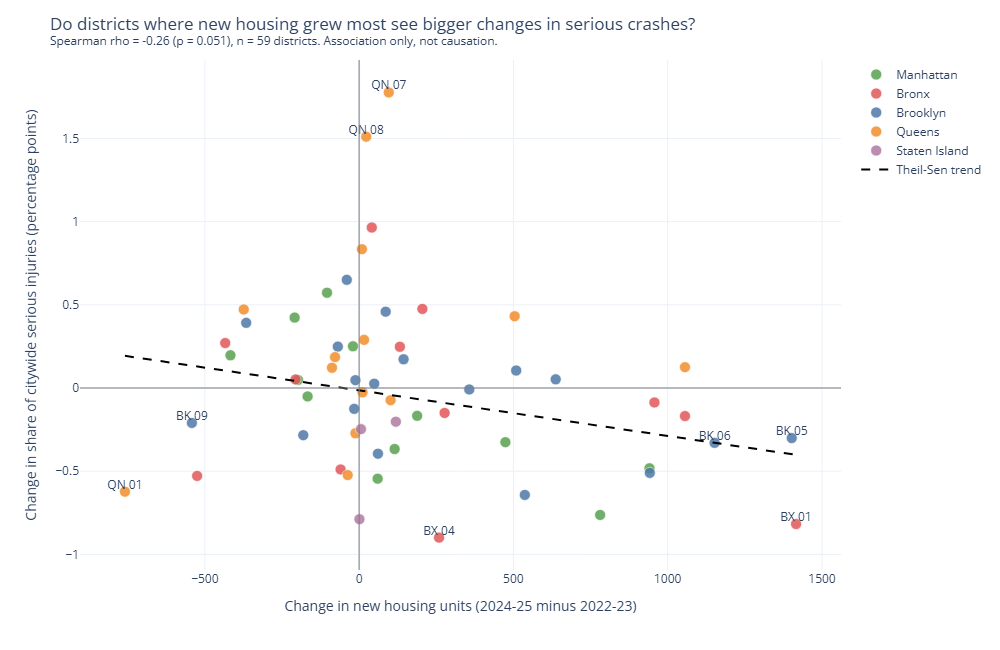

,outcome,y_mode,n_districts,spearman_rho,p_value,rho_baseline_vs_change,p_baseline_vs_change
0,severe_injuries,share_pp,59,-0.256,0.051,-0.33,0.011


,outcome,y_mode,n_districts,spearman_rho,p_value,rho_baseline_vs_change,p_baseline_vs_change
0,severe_injuries,share_pp,59,-0.256,0.051,-0.330,0.011
1,severe_injuries,count,59,-0.260,0.047,-0.330,0.011
2,ksi,share_pp,59,-0.253,0.053,-0.346,0.007
3,ksi,count,59,-0.258,0.049,-0.346,0.007


,unit_change,share_change_pp
cd_label,,
QN 07,96,1.78
QN 08,23,1.51
BX 01,1416,-0.82


Theil-Sen slope: -0.27 percentage points of citywide share per 1,000 units


In [56]:
# Question 1: chart, correlation summary and sensitivity table
fig_q1, summary_q1 = q1_growth_vs_crash_change(df)
fig_q1.show()
display(summary_q1.round(3))
display(q1_sensitivity(df).round(3))

# Districts quoted in the findings, and the slope of the Theil-Sen line
q1_table = build_period_table(df, "severe_injuries")
display(q1_table.set_index("cd_label").loc[["QN 07", "QN 08", "BX 01"], ["unit_change", "share_change_pp"]].round(2))
slope_per_unit = theilslopes(q1_table["share_change_pp"], q1_table["unit_change"])[0]
print(f"Theil-Sen slope: {1000 * slope_per_unit:.2f} percentage points of citywide share per 1,000 units")

In [57]:
# Does the housing association survive after controlling for the early-period crash level?
# Rank-based partial correlation: correlate the residuals of ranked variables.
def rank_partial_correlation(x, y, control):
    ranks = pd.DataFrame({"x": x, "y": y, "c": control}).rank()
    def residuals(target):
        slope, intercept = np.polyfit(ranks["c"], ranks[target], 1)
        return ranks[target] - (intercept + slope * ranks["c"])
    return spearmanr(residuals("x"), residuals("y"))

rho_partial, p_partial = rank_partial_correlation(q1_table["unit_change"], q1_table["share_change_pp"], q1_table["outcome_early"])
rho_units_vs_baseline, p_units_vs_baseline = spearmanr(q1_table["unit_change"], q1_table["outcome_early"])
print(f"Partial rho (housing change vs crash-share change | early crashes): {rho_partial:.3f} (p = {p_partial:.3f})")
print(f"Housing change vs early crash level: rho = {rho_units_vs_baseline:.3f} (p = {p_units_vs_baseline:.3f})")

Partial rho (housing change vs crash-share change | early crashes): -0.211 (p = 0.109)
Housing change vs early crash level: rho = 0.171 (p = 0.196)


#### Research question: Which districts combine high new-housing volume with high serious-injury counts?

**Why it matters.** Agencies have limited capacity to review street safety. A screening
list of districts where a lot of new housing and many serious crashes coincide shows where
a coordinated review (housing completions plus street safety) could start.

**Method.**
- For each district: total new units completed 2022-2025 (x-axis, log scale) and total
  serious injuries 2022-2025 (y-axis). Four-year totals are the most stable estimate
  available. Bubble size is affordable units.
- Quadrants are split at the citywide district medians (854 units, 168 injuries). A
  district is "high" if strictly above the median.
- Hotspots are the "high housing, high crashes" districts, ranked by the mean of their
  citywide percentile rank on both axes. The six highest are labelled.

**Result.**
- 17 of 59 districts fall in the high-high quadrant. The other quadrants hold 12 (high
  housing, lower crashes), 12 (lower housing, high crashes) and 18 (lower, lower).
- By borough the high-high districts are Brooklyn 6, Bronx 4, Manhattan 4, Queens 3 and
  Staten Island 0.
- The six highest-ranked hotspots are BK 01 (6,388 units, 282 injuries), BX 01 (5,850;
  262), BK 05 (3,554; 242), QN 12 (2,348; 301), BX 04 (3,393; 232) and MN 04 (3,807; 207).
  QN 12 has the most serious injuries of any hotspot.
- Housing volume and serious injuries are only weakly related across all districts:
  Spearman rho = 0.229, p = 0.082.
- Housing volume alone does not identify the districts with the most serious injuries. The two districts
  with the highest injury totals, QN 07 (324) and BK 18 (317), are in the lower-housing
  quadrant.

**Limitations.**
- Counts are not exposure-adjusted. Large districts (more people, more road) tend to
  have more of both, so the quadrants partly reflect district size.
- The housing data covers HPD affordable-housing production, not all new construction.
- A completion date is not an occupancy date.
- Only crashes that could be located are counted, and that share varied by year; it may
  also vary between districts.
- The median split is arbitrary. Districts near the dashed lines are borderline (for
  example QN 06 sits exactly on the housing median).
- This shows co-occurrence only, not that housing influences crashes.

**So what for NYC.** The high-high list is a screening tool for where to coordinate safety
review with scheduled completions, not a ranking of danger. Because the highest-injury
districts are not mostly high-growth ones, safety programmes should not be targeted by
construction volume alone. The lower-housing, high-crash districts need attention on
their own account.

In [58]:
# ======================= Research question 2 =======================
QUADRANT_COLORS = {
    "High housing, high crashes": "#d62728",   # the quadrant the question asks about: strong colour
    "High housing, lower crashes": "#9ecae1",  # the other three are lighter so the hotspots stand out
    "Lower housing, high crashes": "#fdae6b",
    "Lower housing, lower crashes": "#d0d3d6",
}

def build_quadrant_table(df, outcome="severe_injuries", reference_df=None):
    """District totals over the selected years plus quadrant membership.

    Medians come from reference_df (all boroughs, same years) so that filtering by
    borough does not move the quadrant lines. 'High' means strictly above the median.
    """
    reference_df = df if reference_df is None else reference_df
    reference_df = reference_df[reference_df["year"].isin(df["year"].unique())]

    def district_totals(frame):
        return frame.groupby(["cd", "borough"], as_index=False).agg(
            total_units=("housing_total_units", "sum"),
            affordable_units=("housing_affordable_units", "sum"),
            total_outcome=(outcome, "sum"),
            fatalities=("fatalities", "sum"),
        )
    table, reference = district_totals(df), district_totals(reference_df)
    median_units, median_outcome = reference["total_units"].median(), reference["total_outcome"].median()

    high_housing, high_crash = table["total_units"] > median_units, table["total_outcome"] > median_outcome
    table["quadrant"] = np.select(
        [high_housing & high_crash, high_housing & ~high_crash, ~high_housing & high_crash],
        ["High housing, high crashes", "High housing, lower crashes", "Lower housing, high crashes"],
        default="Lower housing, lower crashes",
    )
    # Hotspot score: mean percentile rank across the whole city on both axes (0-1)
    table["hotspot_score"] = (table["total_units"].map(lambda v: (reference["total_units"] <= v).mean())
                              + table["total_outcome"].map(lambda v: (reference["total_outcome"] <= v).mean())) / 2
    table = add_cd_label(table)
    table.attrs.update(median_units=median_units, median_outcome=median_outcome)
    return table

def q2_quadrant_chart(df, reference_df=None, outcome="severe_injuries", n_labels=6):
    """Quadrant bubble chart: new units vs serious injuries; bubble size = affordable units."""
    if df.empty:
        return empty_figure("No data for the selected filters."), pd.DataFrame()
    table = build_quadrant_table(df, outcome, reference_df)
    median_units, median_outcome = table.attrs["median_units"], table.attrs["median_outcome"]
    years = f"{df['year'].min()}-{df['year'].max()}" if df["year"].nunique() > 1 else str(df["year"].iloc[0])
    outcome_name = OUTCOME_LABELS[outcome]
    table["bubble_size"] = table["affordable_units"].clip(lower=1)

    fig = px.scatter(
        table, x="total_units", y="total_outcome", size="bubble_size", size_max=38,
        color="quadrant", color_discrete_map=QUADRANT_COLORS, hover_name="cd_label",
        hover_data={"borough": True, "total_units": ":,.0f", "total_outcome": ":,.0f",
                    "affordable_units": ":,.0f", "bubble_size": False, "quadrant": False},
        labels={"total_units": f"New housing units completed, {years} (log scale)",
                "total_outcome": f"Total {outcome_name}, {years}",
                "affordable_units": "Affordable units", "borough": "Borough"},
        log_x=True,
    )
    fig.update_traces(marker=dict(opacity=0.8, line=dict(width=0.6, color="white")))
    fig.add_vline(x=median_units, line_dash="dash", line_color="grey")
    fig.add_hline(y=median_outcome, line_dash="dash", line_color="grey")

    hotspots = table[table["quadrant"] == "High housing, high crashes"].nlargest(n_labels, "hotspot_score")
    fig.add_trace(go.Scatter(x=hotspots["total_units"], y=hotspots["total_outcome"], mode="text",
                             text=hotspots["cd_label"], textposition="top center",
                             showlegend=False, hoverinfo="skip"))
    fig.update_layout(
        template="plotly_white", legend_title_text="",
        title=dict(text=("Where does heavy new housing coincide with many serious crashes?<br>"
                         f"<sup>Dashed lines = citywide district medians ({median_units:,.0f} units, "
                         f"{median_outcome:,.0f} injuries). Bubble size = affordable units. "
                         "Counts are not exposure-adjusted.</sup>")),
    )
    hotspot_table = (table[table["quadrant"] == "High housing, high crashes"]
                     .sort_values("hotspot_score", ascending=False)
                     [["cd_label", "borough", "total_units", "affordable_units", "total_outcome", "hotspot_score"]])
    return fig, hotspot_table

def q2_summary(df, reference_df=None, outcome="severe_injuries"):
    """Quadrant counts, borough mix of the hotspot quadrant, and overall rank correlation."""
    table = build_quadrant_table(df, outcome, reference_df)
    rho, p_value = rank_correlation(table["total_units"], table["total_outcome"])
    return {
        "quadrant_counts": table["quadrant"].value_counts().rename("districts").to_frame(),
        "hotspot_by_borough": pd.crosstab(table["borough"], table["quadrant"]),
        "spearman_units_vs_outcome": (rho, p_value),
    }

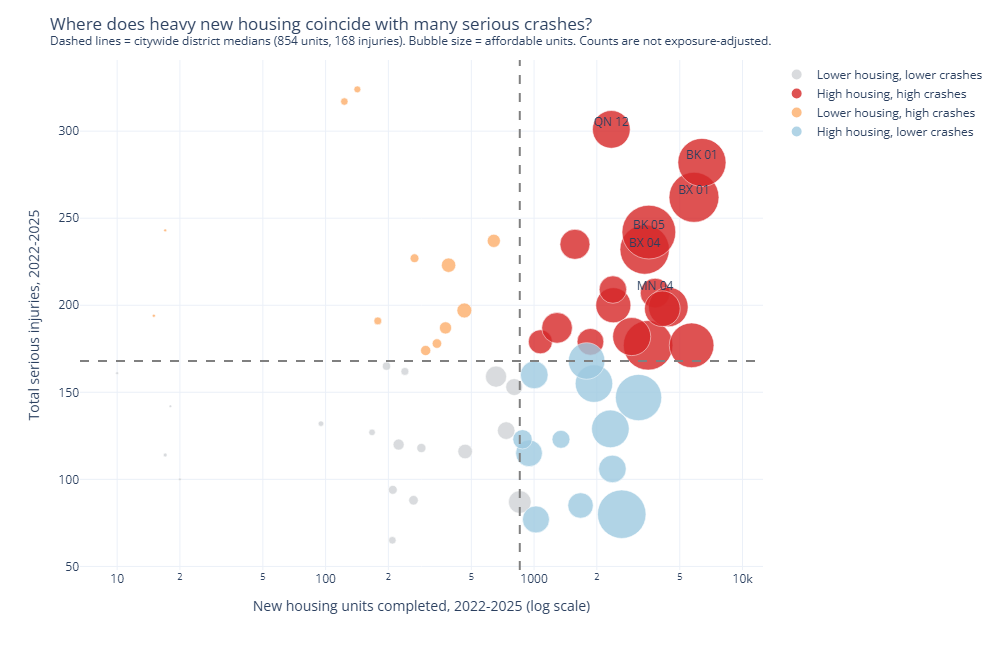

,cd_label,borough,total_units,affordable_units,total_outcome,hotspot_score
24,BK 01,Brooklyn,6388,2592,282,0.97
12,BX 01,Bronx,5850,2796,262,0.96
28,BK 05,Brooklyn,3554,3234,242,0.90
53,QN 12,Queens,2348,1595,301,0.86
15,BX 04,Bronx,3393,2729,232,0.86
3,MN 04,Manhattan,3807,988,207,0.85
25,BK 02,Brooklyn,4407,1754,199,0.85
42,QN 01,Queens,4123,1425,198,0.83
40,BK 17,Brooklyn,2389,844,209,0.79
10,MN 11,Manhattan,2400,1375,200,0.78


,districts
quadrant,
"Lower housing, lower crashes",18
"High housing, high crashes",17
"Lower housing, high crashes",12
"High housing, lower crashes",12


quadrant,"High housing, high crashes","High housing, lower crashes","Lower housing, high crashes","Lower housing, lower crashes"
borough,,,,
Bronx,4,5,0,3
Brooklyn,6,6,3,3
Manhattan,4,0,2,6
Queens,3,1,6,4
Staten Island,0,0,1,2


Spearman (total units vs total serious injuries): rho = 0.229, p = 0.082
Median new units: 854 | median serious injuries: 168


,cd_label,total_units,total_outcome,quadrant
47,QN 06,854,87,"Lower housing, lower crashes"


In [59]:
fig_q2, hotspot_table = q2_quadrant_chart(df)
fig_q2.show()
display(hotspot_table.round(2))
summary_q2 = q2_summary(df)
display(summary_q2["quadrant_counts"])
display(summary_q2["hotspot_by_borough"])
print("Spearman (total units vs total serious injuries): rho = %.3f, p = %.3f" % summary_q2["spearman_units_vs_outcome"])

# Quadrant lines (citywide medians) and the borderline district quoted in the findings
quadrants = build_quadrant_table(df)
print(f"Median new units: {quadrants['total_units'].median():,.0f} | "
      f"median serious injuries: {quadrants['total_outcome'].median():,.0f}")
display(quadrants.loc[quadrants["cd_label"] == "QN 06", ["cd_label", "total_units", "total_outcome", "quadrant"]])

### 7.8 Individual research questions: Amro Taha Salih

This section asks two questions that the other team questions do not cover:

- **A. Who is housed where?** Are the units for the lowest-income households placed in the most crash-burdened districts?
- **B. When do crashes happen relative to who moves in?** Do districts adding family-sized units have more serious crashes at school-travel times?

Both use the integrated district/year table (New Construction completions 2022-2025 and assigned SIRTA events 2022-2025). Question B also uses the cleaned SIRTA detail for crash date and hour. The setup cell checks that the detail rows reconcile exactly with the integrated table before anything is computed.

**Crash outcome.** Serious injuries (`Total Severe Injuries`). Fatalities after 2022 have no coordinates and cannot be placed in a district (see the data-limitation check in 7.7).

In [60]:
# Shared setup for section 7.8: the exported integrated table and the cleaned record-level files.
# Reading the exported CSVs (rather than `df`) also checks that the exports reconcile.

INTEGRATED_PATH = "outputs/data/integrated_district_year.csv"
HOUSING_CLEAN_PATH = "outputs/data/housing_clean_all_records.csv"
TRANSPORT_CLEAN_PATH = "outputs/data/transport_clean_all_records.csv"

df_integrated = pd.read_csv(INTEGRATED_PATH)
housing_detail = pd.read_csv(HOUSING_CLEAN_PATH, low_memory=False)
crash_detail = pd.read_csv(TRANSPORT_CLEAN_PATH, low_memory=False)

def cd_label(cd, borough):
    """'BK 03' style label from a numeric district code and its borough."""
    return f"{BOROUGH_ABBREV[borough]} {cd % 100:02d}"

# Housing rows that feed the integrated table: eligible New Construction completions 2022-2025
# (the same primary_eligible flag the integration used, so totals reconcile with df_integrated).
housing_eligible = housing_detail[housing_detail["primary_eligible"] == 1].copy()
# Crash rows that feed the integrated table: valid, district-assigned SIRTA events 2022-2025.
crashes_eligible = crash_detail[crash_detail["primary_eligible"] == 1].copy()

# Reconciliation: the detail rows used below must add up to the integrated table.
checks_78 = {
    "eligible housing records == integrated housing_source_records":
        len(housing_eligible) == df_integrated["housing_source_records"].sum(),
    "eligible crash events == integrated crash_events":
        len(crashes_eligible) == df_integrated["crash_events"].sum(),
    "serious injuries reconcile":
        crashes_eligible["Total Severe Injuries"].sum() == df_integrated["severe_injuries"].sum(),
}
display(pd.DataFrame({"check": checks_78.keys(), "passed": checks_78.values()}))
assert all(checks_78.values())

,check,passed
0,eligible housing records == integrated housing...,True
1,eligible crash events == integrated crash_events,True
2,serious injuries reconcile,True


#### Research question A: Are the deepest-affordability units placed in the community districts with the heaviest serious-crash burden?

**Why it matters.** Households at or below 50% of Area Median Income are the least likely to own a car. They depend most on walking, cycling and buses, which are the modes most exposed to serious injury. If HPD's deepest-affordability units were systematically sited in the districts with the most serious crashes, the poorest new tenants would inherit an extra street-safety burden. That would be an equity issue for both HPD and Vision Zero.

**Method.**
- Affordable units from eligible New Construction completions (2022-2025) are grouped into three income tiers by HPD's AMI bands: **extremely + very low (0-50% AMI)**, **low (51-80%)** and **moderate + middle (81-165%)**. The 138 "Other income" units, mostly superintendent units, belong to no band and are left out.
- Crash burden = the district's total serious injuries, 2022-2025.
- **Concentration curve.** Districts are ordered from most to fewest serious injuries. Each line shows the cumulative share of a tier's units against the cumulative share of serious injuries. The diagonal means "units placed in proportion to serious injuries". A line above it means that tier is concentrated in high-crash districts.
- **Summary per tier.**
  - The share of units located in the 15 most crash-burdened districts (the top quarter).
  - The unit-weighted average serious injuries of the district a unit sits in.
  - All tiers are measured against the same 59 districts. District size and population inflate raw counts, but they affect every tier equally, so the tiers can be compared fairly with each other.
- **Uncertainty.** A bootstrap over projects (2,000 resamples) gives a 95% interval for the deep-minus-moderate gap. Projects are resampled rather than buildings, because buildings in one project share a site and a financing decision.
- **Borough check.** The same comparison uses each district's crash percentile *within its own borough*. This separates "deep units are mostly in the Bronx" from "deep units are on the worst districts inside each borough".

In [61]:
# ======================= Research question A: income depth vs crash burden =======================
# Income tiers ordered from deepest to shallowest affordability (HPD Area Median Income bands).
# "Other Income Units" (mostly superintendent units, 138 in scope) belong to no AMI band and are left out.
INCOME_TIERS = {
    "Extremely + very low income (0-50% AMI)": ["Extremely Low Income Units", "Very Low Income Units"],
    "Low income (51-80% AMI)": ["Low Income Units"],
    "Moderate + middle income (81-165% AMI)": ["Moderate Income Units", "Middle Income Units"],
}
TIER_COLUMNS = {  # same tiers, expressed with the integrated-table column names
    "Extremely + very low income (0-50% AMI)": ["housing_extremely_low_income_units", "housing_very_low_income_units"],
    "Low income (51-80% AMI)": ["housing_low_income_units"],
    "Moderate + middle income (81-165% AMI)": ["housing_moderate_income_units", "housing_middle_income_units"],
}
# Ordinal blue ramp (light -> dark = shallow -> deep affordability); dash styles give a second,
# non-colour cue for each tier.
TIER_STYLE = {
    "Extremely + very low income (0-50% AMI)": dict(color="#104281", dash="solid"),
    "Low income (51-80% AMI)": dict(color="#2a78d6", dash="dash"),
    "Moderate + middle income (81-165% AMI)": dict(color="#86b6ef", dash="dot"),
}
TOP_N_DISTRICTS = 15  # top quarter of the 59 community districts by serious injuries

def build_tier_table(df):
    """One row per district: 2022-2025 (or filtered-year) affordable units in each income tier
    plus total serious injuries, sorted from the most to the fewest serious injuries."""
    table = df.groupby(["cd", "borough"], as_index=False).agg(
        severe_injuries=("severe_injuries", "sum"), total_units=("housing_total_units", "sum"),
        affordable_units=("housing_affordable_units", "sum"),
        **{c: (c, "sum") for cols in TIER_COLUMNS.values() for c in cols})
    for tier, cols in TIER_COLUMNS.items():
        table[tier] = table[cols].sum(axis=1)
    table["market_rate_units"] = table["total_units"] - table["affordable_units"]
    table["cd_label"] = [cd_label(c, b) for c, b in zip(table["cd"], table["borough"])]
    # Crash burden within the district's own borough (0-1), to separate a borough effect
    # (e.g. "deep units are mostly in the Bronx") from district placement inside a borough.
    table["within_borough_crash_pct"] = table.groupby("borough")["severe_injuries"].rank(pct=True)
    # Most serious injuries first; cd breaks ties so the order is reproducible.
    return table.sort_values(["severe_injuries", "cd"], ascending=[False, True]).reset_index(drop=True)

def tier_exposure_summary(table, top_n=TOP_N_DISTRICTS):
    """For each tier: units, share located in the top-N crash districts, and the unit-weighted
    average crash burden of the district a unit sits in (all tiers face the same districts,
    so district size and population cancel out when the tiers are compared with each other)."""
    top = table.head(top_n)
    rows = []
    for tier in list(TIER_COLUMNS) + ["market_rate_units"]:
        units = table[tier]
        if units.sum() == 0:
            continue
        rows.append({
            "tier": tier if tier in TIER_COLUMNS else "Market-rate units in the same buildings",
            "units": int(units.sum()),
            f"share_in_top_{top_n}_crash_districts_%": 100 * top[tier].sum() / units.sum(),
            "avg_district_serious_injuries_per_unit": (units * table["severe_injuries"]).sum() / units.sum(),
            "avg_within_borough_crash_percentile": (units * table["within_borough_crash_pct"]).sum() / units.sum(),
        })
    rows.append({"tier": "Benchmark: serious injuries themselves", "units": np.nan,
                 f"share_in_top_{top_n}_crash_districts_%": 100 * top["severe_injuries"].sum() / table["severe_injuries"].sum(),
                 "avg_district_serious_injuries_per_unit": np.nan, "avg_within_borough_crash_percentile": np.nan})
    return pd.DataFrame(rows)

def qa_concentration_chart(df, top_n=TOP_N_DISTRICTS):
    """Concentration curves: districts ordered from most to fewest serious injuries.
    x = cumulative share of serious injuries, y = cumulative share of each tier's affordable units.
    The diagonal is 'units placed in proportion to serious injuries'; a curve above it means
    that tier is concentrated in the most crash-burdened districts."""
    if df.empty or df["severe_injuries"].sum() == 0:
        return empty_figure("No serious injuries for the selected filters."), pd.DataFrame()
    table = build_tier_table(df)
    x = np.r_[0, 100 * table["severe_injuries"].cumsum() / table["severe_injuries"].sum()]
    fig = go.Figure()
    fig.add_trace(go.Scatter(x=[0, 100], y=[0, 100], mode="lines", name="Proportional to serious injuries",
                             line=dict(color="#9aa0a6", width=1.5, dash="longdash"), hoverinfo="skip"))
    for tier, style in TIER_STYLE.items():
        if table[tier].sum() == 0:
            continue
        y = np.r_[0, 100 * table[tier].cumsum() / table[tier].sum()]
        custom = np.c_[np.r_[["start"], table["cd_label"]], np.r_[0, table["severe_injuries"]],
                       np.r_[0, table[tier]]]
        fig.add_trace(go.Scatter(
            x=x, y=y, mode="lines+markers", name=tier, customdata=custom,
            line=dict(color=style["color"], dash=style["dash"], width=2), marker=dict(size=5),
            hovertemplate=("<b>%{customdata[0]}</b><br>District serious injuries: %{customdata[1]}"
                           "<br>District units in this tier: %{customdata[2]}"
                           "<br>Cumulative serious injuries: %{x:.1f}%<br>Cumulative units: %{y:.1f}%<extra>"
                           + tier + "</extra>")))
    if len(table) > top_n:
        cut = x[top_n]
        fig.add_vline(x=cut, line_dash="dot", line_color="#5f6368", line_width=1)
        fig.add_annotation(x=cut, y=4, xanchor="left", showarrow=False, font=dict(size=11, color="#3c4043"),
                           text=f" {top_n} most crash-burdened districts")
    fig.update_layout(
        template="plotly_white", legend_title_text="", legend=dict(x=0.52, y=0.08, bgcolor="rgba(255,255,255,0.8)"),
        xaxis=dict(title="Cumulative share of serious injuries (districts ordered from most to fewest), %",
                   range=[0, 100], ticksuffix="%"),
        yaxis=dict(title="Cumulative share of the tier's affordable units, %", range=[0, 101], ticksuffix="%"),
        height=600, margin=dict(t=150),
        title=dict(y=0.97, yanchor="top", yref="container", text=("Are the deepest-affordability units placed in<br>the most crash-burdened districts?<br>"
                         f"<sup>New Construction completions vs SIRTA serious injuries, {df['year'].min()}-{df['year'].max()}, "
                         f"{len(table)} community districts.<br>Above the diagonal = concentrated in high-crash districts.</sup>")))
    return fig, tier_exposure_summary(table, top_n)

def bootstrap_deep_vs_moderate(housing_rows, district_injuries, n_boot=2000, seed=7):
    """95% interval for the difference in average district serious injuries per unit:
    deepest tier minus moderate+middle tier. Projects (not buildings) are resampled,
    because buildings of one project share a location and a financing decision."""
    deep_cols = INCOME_TIERS["Extremely + very low income (0-50% AMI)"]
    mod_cols = INCOME_TIERS["Moderate + middle income (81-165% AMI)"]
    rows = housing_rows.assign(
        deep=housing_rows[deep_cols].fillna(0).sum(axis=1), moderate=housing_rows[mod_cols].fillna(0).sum(axis=1),
        burden=housing_rows["cd"].map(district_injuries))
    # Per project: units in each tier and units x district burden (both additive across buildings)
    per_project = rows.groupby("Project ID").apply(lambda g: pd.Series({
        "deep": g["deep"].sum(), "deep_burden": (g["deep"] * g["burden"]).sum(),
        "moderate": g["moderate"].sum(), "moderate_burden": (g["moderate"] * g["burden"]).sum()}),
        include_groups=False).to_numpy()
    rng = np.random.default_rng(seed)
    diffs = []
    for _ in range(n_boot):
        s = per_project[rng.integers(0, len(per_project), len(per_project))].sum(axis=0)
        diffs.append(s[1] / s[0] - s[3] / s[2])
    point = per_project.sum(axis=0)
    return {"difference": point[1] / point[0] - point[3] / point[2],
            "ci_low": np.percentile(diffs, 2.5), "ci_high": np.percentile(diffs, 97.5), "projects": len(per_project)}

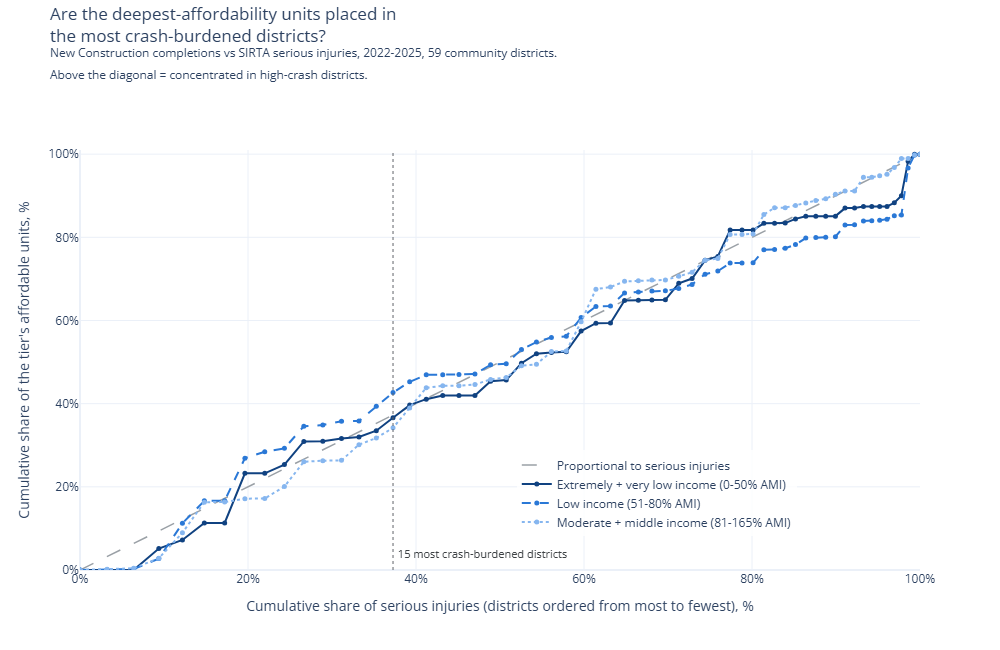

,tier,units,share_in_top_15_crash_districts_%,avg_district_serious_injuries_per_unit,avg_within_borough_crash_percentile
0,Extremely + very low income (0-50% AMI),15390.0,36.61,184.70,0.63
1,Low income (51-80% AMI),11898.0,42.68,185.61,0.62
2,Moderate + middle income (81-165% AMI),20600.0,34.18,187.88,0.64
3,Market-rate units in the same buildings,38417.0,40.29,194.69,0.67
4,Benchmark: serious injuries themselves,NaN,37.26,NaN,NaN


Other-income units left out (no AMI band): 138
Deep minus moderate+middle, avg district serious injuries per unit: -3.2 (95% bootstrap CI -14.8 to 8.3, 1734 projects resampled)
Deep share vs serious injuries (districts with >= 100 tiered units, n = 42): rho = 0.085, p = 0.592


,Extremely + very low income %,Low income %,Moderate + middle income %,severe_injuries %
borough,,,,
Bronx,35.0,27.2,41.4,19.7
Brooklyn,33.6,36.8,31.7,30.3
Manhattan,11.9,14.7,7.8,19.8
Queens,18.8,20.2,19.0,25.3
Staten Island,0.7,1.1,0.1,5.0


,cd_label,severe_injuries,Extremely + very low income (0-50% AMI),Low income (51-80% AMI),Moderate + middle income (81-165% AMI)
0,QN 07,324,0,10,43
1,BK 18,317,1,17,43
2,QN 12,301,792,300,497
3,BK 01,282,319,1009,1262
4,BX 01,262,631,642,1516
5,QN 10,243,1,6,3
6,BK 05,242,1835,1216,169
7,MN 05,237,0,184,10
8,BX 12,235,321,97,591
9,BX 04,232,860,633,1229


In [62]:
fig_qa, summary_qa = qa_concentration_chart(df_integrated)
fig_qa.show()
display(summary_qa.round(2))
print("Other-income units left out (no AMI band):", int(df_integrated["housing_other_income_units"].sum()))

# Uncertainty: is the deep-vs-moderate gap distinguishable from zero? (project-level bootstrap)
district_injuries = df_integrated.groupby("cd")["severe_injuries"].sum()
for cols in INCOME_TIERS.values():  # detail rows must reconcile with the integrated tier totals
    for c in cols:
        alias = "housing_" + UNITKEY[c]
        assert housing_eligible[c].fillna(0).sum() == df_integrated[alias].sum(), c
boot_qa = bootstrap_deep_vs_moderate(housing_eligible, district_injuries)
print("Deep minus moderate+middle, avg district serious injuries per unit: "
      f"{boot_qa['difference']:.1f} (95% bootstrap CI {boot_qa['ci_low']:.1f} to {boot_qa['ci_high']:.1f}, "
      f"{boot_qa['projects']} projects resampled)")

# District-level view: does a district's deep-affordability share rise with its serious injuries?
tier_table = build_tier_table(df_integrated)
tier_table["tiered_units"] = tier_table[list(TIER_COLUMNS)].sum(axis=1)
tier_table["deep_share"] = tier_table["Extremely + very low income (0-50% AMI)"] / tier_table["tiered_units"]
enough_units = tier_table["tiered_units"] >= 100  # shares from a handful of units are unstable
rho_qa, p_qa = spearmanr(tier_table.loc[enough_units, "deep_share"], tier_table.loc[enough_units, "severe_injuries"])
print(f"Deep share vs serious injuries (districts with >= 100 tiered units, n = {enough_units.sum()}): "
      f"rho = {rho_qa:.3f}, p = {p_qa:.3f}")

# Borough context: where each tier was built vs where serious injuries were recorded (% of city)
borough_mix = tier_table.groupby("borough")[list(TIER_COLUMNS) + ["severe_injuries"]].sum()
display((100 * borough_mix / borough_mix.sum()).round(1).rename(columns=lambda c: c.split(" (")[0] + " %"))

# Highest-crash districts and how many affordable units of each tier they received
display(tier_table.head(TOP_N_DISTRICTS)[["cd_label", "severe_injuries"] + list(TIER_COLUMNS)])

**Result: no. The deepest-affordability units are not concentrated in the highest-crash districts.**
- All three curves stay close to the diagonal. The 15 most crash-burdened districts account for **37.3%** of serious injuries. They received **36.6%** of extremely/very-low units, **42.7%** of low-income units and **34.2%** of moderate/middle units.
- The average district a deep-affordability unit lands in recorded **184.7** serious injuries. The figures are 185.6 for low-income units and 187.9 for moderate/middle units (market-rate units in the same buildings: 194.7).
- The deep-minus-moderate gap is **-3.2 injuries**, with a 95% bootstrap interval of **-14.8 to +8.3**. That is no detectable difference.
- Within boroughs the tiers also match: the average within-borough crash percentile is 0.63, 0.62 and 0.64.
- District level: the share of a district's new affordable units that are deep-affordability is unrelated to its serious injuries (Spearman rho = 0.09, p = 0.59, n = 42 districts with at least 100 tiered units).

**What surprised me.**
- The two most crash-burdened districts in the city, **QN 07** (324 serious injuries) and **BK 18** (317), received almost no new affordable housing of any tier: 53 and 61 income-tiered units over four years. QN 10, MN 05 and QN 08 are similar. The districts with the most serious injuries are not where affordable housing is being built.
- The no-bias average hides a few districts that matter. **BK 05** alone received 1,835 deep-affordability units (12% of the citywide total) and is the 7th most crash-burdened district. Together, **BK 05, QN 12, BX 04 and BX 01** received 4,118 deep units (27% of the citywide total), and all four are in the top quarter for serious injuries.
- At borough level, the Bronx received 35% of deep units but only 20% of serious injuries. Queens and Staten Island have more of the crash burden than of the deep units.

**Limitations.**
- A community district is coarse: a building can sit on a safe block inside a high-crash district. A block-level test would need distance-based joins.
- Counts are not exposure-adjusted. This does not bias the comparison *between tiers*, but "most crash-burdened" partly means "largest" or "busiest".
- An AMI tier describes the unit's rent restriction. It does not describe the residents' actual travel modes.
- SIRTA covers serious crashes only, and only those that could be assigned to a district.
- A completion date is not an occupancy date.
- The finding is descriptive, not causal.

**So what for NYC.**
- The equity check passes at district level: HPD's siting does not add a systematic safety burden for the lowest-income tenants.
- Vision Zero street-redesign work should still be paired with the large deep-affordability pipelines in **BK 05, QN 12, BX 04 and BX 01**, where a quarter of these units open into top-quarter crash districts.
- In the districts with the most serious injuries (QN 07, BK 18), safety work cannot be scheduled around housing completions, because almost none are happening there.

#### Research question B: Do districts building more family-sized affordable units have a larger share of their serious crashes at school-travel times?

**Why it matters.** Two-bedroom and larger units are where children live. If districts adding many family-sized units also show a stronger school-commute crash peak, then school-zone measures could be timed with family-housing completions. These measures include speed cameras, crossing guards, Safe Routes to School and leading pedestrian intervals.

**Method.**
- **Family share** = (2-BR + 3-BR + 4-BR + 5-BR + 6-BR+ units) / units with a known bedroom count, for 2022-2025 completions. Unknown-bedroom units are excluded. Districts with at least 100 such units are kept (42 of 59), because shares from a handful of units are unstable.
- **School-travel crashes.**
  - A *school day* is Monday to Friday, September to June.
  - *School-travel hours* are 07:00-08:59 (arrival) and 14:00-17:59 (dismissal and after-school).
  - For each district: the share of its school-day serious injuries that fall in those hours.
  - The 162 records timed exactly 00:00 are dropped; cleaning flagged them as likely placeholder times.
- **Placebo comparison.** The same hours are measured on weekends and in summer. If family-heavy districts also show more crashes at those hours when schools are closed, the pattern is general daytime activity, not school travel. The school-minus-other difference is tested too.
- **Tests and chart.** Spearman rank correlation across districts. The chart groups the 42 districts into equal thirds (14 each) by family share and shows each third's hour-of-day profile on school days next to the weekend/summer comparison.
- **Sensitivity.** All 59 districts, a 300-unit threshold, a wider window (06:00-09:59 and 13:00-18:59), and crash events instead of injuries.

In [63]:
# ======================= Research question B: family-sized units vs school-travel crashes =======================
from plotly.subplots import make_subplots

FAMILY_BR_COLUMNS = ["housing_two_br_units", "housing_three_br_units", "housing_four_br_units",
                     "housing_five_br_units", "housing_six_plus_br_units"]
KNOWN_BR_COLUMNS = ["housing_studio_units", "housing_one_br_units"] + FAMILY_BR_COLUMNS  # unknown-BR excluded
SCHOOL_TRAVEL_HOURS = [7, 8, 14, 15, 16, 17]         # 07:00-08:59 arrival, 14:00-17:59 dismissal/after-school
SCHOOL_TRAVEL_HOURS_WIDE = [6, 7, 8, 9, 13, 14, 15, 16, 17, 18]  # sensitivity definition
SUMMER_MONTHS = [7, 8]                               # NYC public schools closed
TERCILE_LABELS = ["Lowest third", "Middle third", "Highest third"]
TERCILE_COLORS = dict(zip(TERCILE_LABELS, ["#86b6ef", "#2a78d6", "#104281"]))  # same ordinal ramp as question A
TERCILE_DASH = dict(zip(TERCILE_LABELS, ["dot", "dash", "solid"]))

def prepare_crash_timing(crashes):
    """Add calendar fields. 'School day' = Monday-Friday outside July/August. Records whose time is
    exactly 00:00 are dropped here: that value is flagged in cleaning as a likely placeholder time."""
    out = crashes[crashes["midnight_time_flag"] == 0].copy()
    dates = pd.to_datetime(out["Crash Date"])
    out["school_day"] = (dates.dt.dayofweek < 5) & ~dates.dt.month.isin(SUMMER_MONTHS)
    out["hour"] = out["hour"].astype(int)
    out["cd"] = out["cd"].astype(int)
    out["year"] = out["year"].astype(int)
    out["serious_injuries"] = out["Total Severe Injuries"]
    return out

def window_share(frame, hours, weight="serious_injuries"):
    """Share of the frame's serious injuries (or events) that happened in the given hours."""
    w = frame[weight] if weight else pd.Series(1, index=frame.index)
    return (w * frame["hour"].isin(hours)).sum() / w.sum() if w.sum() else np.nan

def build_family_table(df, crash_timing, min_units=100, hours=SCHOOL_TRAVEL_HOURS, weight="serious_injuries"):
    """One row per district: family-sized share of new affordable units with a known bedroom
    count, and the share of serious injuries that happened in school-travel hours, separately
    for school days and for other days (weekends + summer, the 'placebo' comparison)."""
    table = df.groupby(["cd", "borough"], as_index=False)[KNOWN_BR_COLUMNS].sum()
    table["family_units"] = table[FAMILY_BR_COLUMNS].sum(axis=1)
    table["known_bedroom_units"] = table[KNOWN_BR_COLUMNS].sum(axis=1)
    table = table[table["known_bedroom_units"] >= max(min_units, 1)].copy()
    table["family_share"] = table["family_units"] / table["known_bedroom_units"]
    crashes = crash_timing[crash_timing["cd"].isin(table["cd"]) & crash_timing["year"].isin(df["year"].unique())]
    for label, subset in [("school_day", crashes[crashes["school_day"]]), ("other_day", crashes[~crashes["school_day"]])]:
        grouped = subset.groupby("cd")
        table[f"{label}_window_share"] = table["cd"].map(grouped.apply(window_share, hours, weight, include_groups=False))
        table[f"{label}_serious_injuries"] = table["cd"].map(grouped["serious_injuries"].sum()).fillna(0)
    table["cd_label"] = [cd_label(c, b) for c, b in zip(table["cd"], table["borough"])]
    if len(table) >= 3:
        table["family_tercile"] = pd.qcut(table["family_share"].rank(method="first"), 3, labels=TERCILE_LABELS)
    return table

def qb_hourly_profile_chart(df, crashes, min_units=100):
    """Hour-of-day profile of serious injuries for districts grouped into thirds by their
    family-sized share of new affordable units. Left: school days. Right: weekends + summer."""
    timing = prepare_crash_timing(crashes)
    table = build_family_table(df, timing, min_units)
    if len(table) < 6:
        return empty_figure("Too few districts with enough new affordable units for this filter."), pd.DataFrame()
    timing = timing[timing["year"].isin(df["year"].unique())]
    timing = timing.assign(family_tercile=timing["cd"].map(table.set_index("cd")["family_tercile"])).dropna(subset=["family_tercile"])
    fig = make_subplots(rows=1, cols=2, shared_yaxes=True, horizontal_spacing=0.05,
                        subplot_titles=("School days<br>(Mon-Fri, Sep-Jun)", "Weekends + summer<br>(comparison)"))
    summary = []
    for col, is_school in [(1, True), (2, False)]:
        for start, end in [(7, 9), (14, 18)]:  # shaded school-travel windows, drawn behind the lines
            fig.add_shape(type="rect", xref="x" if col == 1 else "x2", yref="paper", x0=start - 0.5, x1=end - 0.5,
                          y0=0, y1=1, fillcolor="#fbbc04", opacity=0.15, line_width=0, layer="below")
        for tercile in TERCILE_LABELS:
            group = timing[(timing["family_tercile"] == tercile) & (timing["school_day"] == is_school)]
            by_hour = group.groupby("hour")["serious_injuries"].sum().reindex(range(24), fill_value=0)
            pct = 100 * by_hour / by_hour.sum()
            districts = table[table["family_tercile"] == tercile]
            fig.add_trace(go.Scatter(
                x=pct.index, y=pct.values, mode="lines+markers", name=tercile, legendgroup=tercile, showlegend=is_school,
                line=dict(color=TERCILE_COLORS[tercile], dash=TERCILE_DASH[tercile], width=2), marker=dict(size=5),
                customdata=by_hour.values,
                hovertemplate=(f"<b>{tercile}</b> (family share {districts['family_share'].min():.0%}-"
                               f"{districts['family_share'].max():.0%})<br>Hour %{{x}}:00<br>"
                               "%{y:.1f}% of serious injuries (%{customdata})<extra></extra>")), row=1, col=col)
            summary.append({"days": "school days" if is_school else "weekends + summer", "family_tercile": tercile,
                            "districts": len(districts), "median_family_share": districts["family_share"].median(),
                            "serious_injuries": int(by_hour.sum()),
                            "share_in_school_travel_hours_%": 100 * window_share(group, SCHOOL_TRAVEL_HOURS)})
    fig.update_xaxes(title_text="Hour of day", tickvals=[0, 3, 6, 9, 12, 15, 18, 21], range=[-0.5, 23.5])
    fig.update_yaxes(title_text="% of the group's serious injuries", ticksuffix="%", row=1, col=1)
    rho, p_value = spearmanr(table["family_share"], table["school_day_window_share"])
    fig.update_layout(
        template="plotly_white", height=680, margin=dict(t=200, b=140),
        legend=dict(title=dict(text="Districts by family-sized share of new affordable units", side="top"),
                    orientation="h", x=0, y=-0.18, xanchor="left", yanchor="top"),
        title=dict(y=0.98, yanchor="top", yref="container", text=(
            "Do districts building more family-sized affordable units<br>have more serious crashes at school-travel times?<br>"
            "<sup>Shaded = school-travel hours, 07:00-08:59 and 14:00-17:59.<br>District family share vs school-day share "
            f"in shaded hours: Spearman rho = {rho:.2f}, p = {p_value:.2f},<br>n = {len(table)} districts with >= {min_units} units.</sup>")))
    return fig, pd.DataFrame(summary)

def qb_correlations(df, crashes, min_units=100, hours=SCHOOL_TRAVEL_HOURS, weight="serious_injuries"):
    """District-level Spearman tests: school-day window share, other-day window share, and the
    school-minus-other difference (which removes each district's general daytime-activity pattern)."""
    table = build_family_table(df, prepare_crash_timing(crashes), min_units, hours, weight)
    table["school_minus_other"] = table["school_day_window_share"] - table["other_day_window_share"]
    out = {"min_units": min_units, "window": "standard" if hours == SCHOOL_TRAVEL_HOURS else "wide",
           "weight": weight or "events", "n_districts": len(table)}
    for col in ["school_day_window_share", "other_day_window_share", "school_minus_other"]:
        rho, p_value = spearmanr(table["family_share"], table[col])
        out[f"rho_{col}"], out[f"p_{col}"] = rho, p_value
    return out

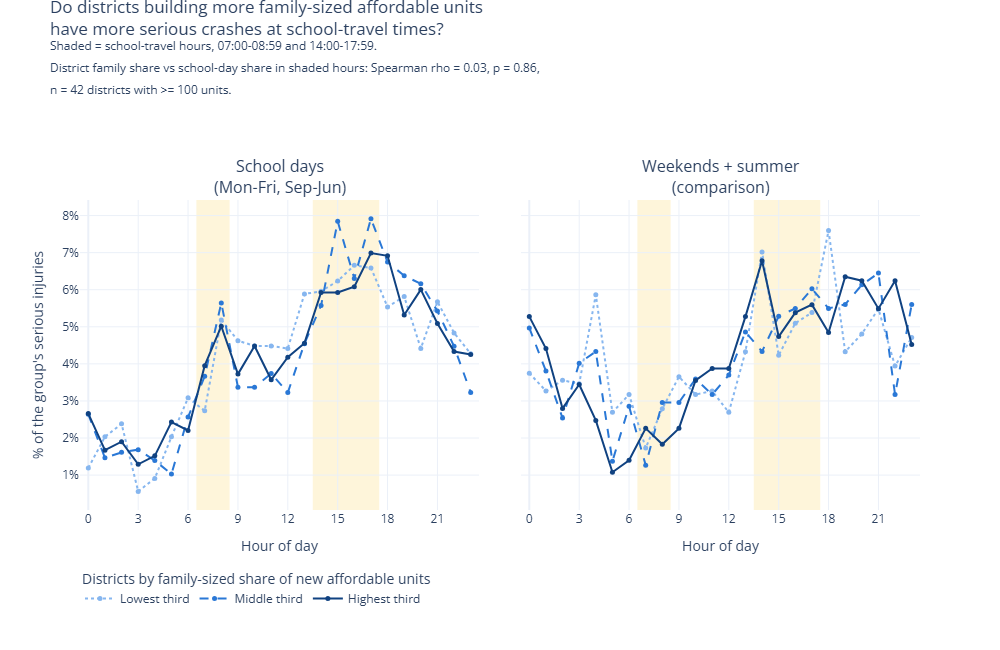

,days,family_tercile,districts,median_family_share,serious_injuries,share_in_school_travel_hours_%
0,school days,Lowest third,14,0.241,1427,33.357
1,school days,Middle third,14,0.306,1364,36.950
2,school days,Highest third,14,0.381,1316,33.891
3,weekends + summer,Lowest third,14,0.241,1040,26.250
4,weekends + summer,Middle third,14,0.306,946,25.370
5,weekends + summer,Highest third,14,0.381,929,26.588


Crashes timed exactly 00:00 left out: 162


,min_units,window,weight,n_districts,rho_school_day_window_share,p_school_day_window_share,rho_other_day_window_share,p_other_day_window_share,rho_school_minus_other,p_school_minus_other
0,100,standard,serious_injuries,42,0.028,0.860,-0.023,0.887,-0.009,0.957
1,1,standard,serious_injuries,59,-0.035,0.791,-0.007,0.957,0.016,0.902
2,300,standard,serious_injuries,33,0.053,0.768,0.015,0.935,-0.002,0.990
3,100,wide,serious_injuries,42,-0.126,0.426,-0.226,0.151,0.138,0.385
4,100,standard,events,42,0.027,0.863,-0.032,0.839,-0.044,0.782


,cd_label,family_units,known_bedroom_units,family_share,school_day_window_share,other_day_window_share,school_day_serious_injuries
47,QN 06,262,576,0.455,0.356,0.357,59.0
28,BK 05,1439,3233,0.445,0.269,0.305,130.0
55,QN 14,1160,2634,0.440,0.347,0.226,49.0
38,BK 15,48,116,0.414,0.373,0.357,102.0
37,BK 14,314,799,0.393,0.311,0.281,119.0
12,BX 01,1075,2796,0.384,0.250,0.317,132.0
24,BK 01,991,2592,0.382,0.442,0.133,156.0
7,MN 08,38,100,0.380,0.314,0.338,102.0


In [64]:
fig_qb, summary_qb = qb_hourly_profile_chart(df_integrated, crashes_eligible)
fig_qb.show()
display(summary_qb.round(3))
print("Crashes timed exactly 00:00 left out:", int(crashes_eligible["midnight_time_flag"].sum()))

# Robustness: the same district-level test under other thresholds, window and outcome definitions
sensitivity_qb = pd.DataFrame([
    qb_correlations(df_integrated, crashes_eligible, min_units=m, hours=h, weight=w)
    for m, h, w in [(100, SCHOOL_TRAVEL_HOURS, "serious_injuries"), (1, SCHOOL_TRAVEL_HOURS, "serious_injuries"),
                    (300, SCHOOL_TRAVEL_HOURS, "serious_injuries"), (100, SCHOOL_TRAVEL_HOURS_WIDE, "serious_injuries"),
                    (100, SCHOOL_TRAVEL_HOURS, None)]])
display(sensitivity_qb.round(3))

# Districts with the highest family-sized share, for the narrative
family_table = build_family_table(df_integrated, prepare_crash_timing(crashes_eligible))
display(family_table.sort_values("family_share", ascending=False)
        [["cd_label", "family_units", "known_bedroom_units", "family_share", "school_day_window_share",
          "other_day_window_share", "school_day_serious_injuries"]].head(8).round(3))

**Result: no. The school-travel crash peak is citywide and is not stronger where family-sized units are being built.**
- The school-day signature is clear. On school days about **one third** of serious injuries happen in the six school-travel hours, against about **one quarter** in the same hours on weekends and in summer. In the chart, the morning peak at 07:00-08:59 appears only on school days.
- The pattern does not change with family share. On school days the share in school-travel hours is **33.9%** for the highest-family third and **33.4%** for the lowest third. The middle third is 37.0%, so there is no gradient.
- Spearman rho = **0.03** (p = 0.86, n = 42). The placebo (weekends/summer) gives rho = -0.02, and the school-minus-other difference gives -0.01.
- The answer is the same in every sensitivity variant. The school-day rho stays between -0.13 and 0.05. The largest value from any test is -0.23 (wide window, weekends/summer), and every p-value is at least 0.15.
- Individual districts vary but rest on small counts (about 50-160 school-day serious injuries each). **BK 01**, with 991 new family-sized units, has 44% of its school-day serious injuries in travel hours against 13% on other days. **BK 05**, the district with the most family-sized units (1,439), shows the opposite: 27% against 31%.

**Limitations.**
- SIRTA records no victim age or trip purpose, so the analysis cannot tell whether children or school trips were involved. School-travel hours are a proxy.
- The school calendar is approximated: holidays and half-days are ignored.
- New affordable units are a small part of each district's housing stock, so a real effect from new residents could be too diluted to see at district level.
- Family share covers HPD affordable units only. A completion date is not an occupancy date.
- The finding is descriptive, not causal.

**So what for NYC.**
- The school-commute crash peak appears in every group of districts. School-zone safety should therefore be prioritised by where schools and child pedestrians are, citywide, not tied to where family-sized affordable housing opens.
- Housing planners have no evidence that family-unit share is a crash-timing risk factor.
- Testing the mechanism properly would need victim-age data and school locations.

### 7.9 Individual research questions: Fares Mustafa El-Sonbaty

#### Question 1 — Affordable housing tenure and recurring crash problems

**Is rental-oriented affordable housing built in different districts from homeownership housing, and do rental-heavy districts have a higher share of repeat-location crashes?**

I compared affordable units completed from 2022 to 2025 in districts with at least one crash that had a positive three-year lookback for similar severe or fatal crashes. For each district, the chart compares its share of rental units with its share of homeownership units. Each tenure type has its own total. The colour shows the share of each district's crashes with a positive lookback (a similar serious crash at the same place in the previous three years), and a rank correlation tests whether that share rises where rental units dominate.

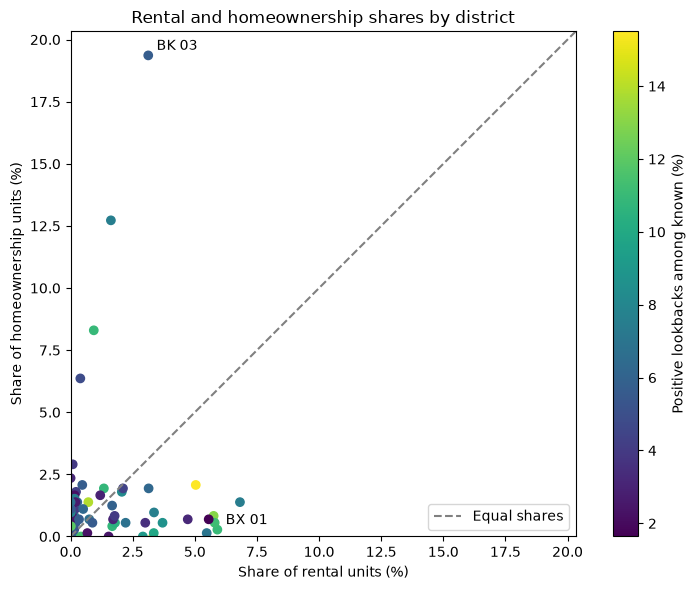

,cd,borough,housing_source_records,housing_rental_units,housing_homeownership_units,housing_rental_units_known_records,housing_homeownership_units_known_records,crash_events,lookback_known_events,positive_lookback_events,rental_share_pct,ownership_share_pct,rental_minus_ownership_pp,positive_lookback_pct,lookback_coverage_pct
0,101,Manhattan,1,63,0,1,1,67,60,1,0.13,0.00,0.13,1.67,89.55
1,102,Manhattan,2,47,0,2,2,124,105,6,0.10,0.00,0.10,5.71,84.68
2,103,Manhattan,16,633,14,16,16,167,148,16,1.34,1.94,-0.60,10.81,88.62
3,104,Manhattan,13,975,13,13,13,207,182,15,2.06,1.80,0.26,8.24,87.92
4,105,Manhattan,3,194,0,3,3,227,194,22,0.41,0.00,0.41,11.34,85.46
5,106,Manhattan,4,68,2,4,4,155,135,7,0.14,0.28,-0.13,5.19,87.10
6,107,Manhattan,8,69,6,8,8,161,137,10,0.15,0.83,-0.68,7.30,85.09
7,108,Manhattan,7,96,4,7,7,171,145,8,0.20,0.55,-0.35,5.52,84.80
8,109,Manhattan,11,86,8,11,11,116,100,4,0.18,1.11,-0.92,4.00,86.21
9,110,Manhattan,26,441,60,26,26,142,128,14,0.93,8.30,-7.37,10.94,90.14


Districts compared: 59
Rental-minus-ownership share vs positive-lookback %: Spearman rho = 0.279, p = 0.033


,cd,housing_rental_units,housing_homeownership_units,rental_share_pct,ownership_share_pct
12,201,2794,2,5.91,0.28
26,303,1478,140,3.12,19.36


In [65]:
# Combine the four years into one row per district.
cols = [
    "housing_source_records", "housing_rental_units", "housing_homeownership_units",
    "housing_rental_units_known_records", "housing_homeownership_units_known_records",
    "crash_events", "lookback_known_events", "positive_lookback_events",
]
tenure = df[df["year"].between(2022, 2025)].groupby(
    ["cd", "borough"], as_index=False
)[cols].sum(min_count=1)

records = tenure["housing_source_records"]
tenure = tenure[
    (tenure["positive_lookback_events"] > 0)
    & (tenure["housing_rental_units_known_records"] == records)
    & (tenure["housing_homeownership_units_known_records"] == records)
    & (tenure["housing_rental_units"] + tenure["housing_homeownership_units"] > 0)
].copy()

rental = tenure["housing_rental_units"]
ownership = tenure["housing_homeownership_units"]
if rental.sum() == 0 or ownership.sum() == 0:
    raise ValueError("The comparison needs units of both tenure types.")

tenure["rental_share_pct"] = 100 * rental / rental.sum()
tenure["ownership_share_pct"] = 100 * ownership / ownership.sum()
tenure["rental_minus_ownership_pp"] = (
    tenure["rental_share_pct"] - tenure["ownership_share_pct"]
)
tenure["positive_lookback_pct"] = (
    100 * tenure["positive_lookback_events"] / tenure["lookback_known_events"]
)
tenure["lookback_coverage_pct"] = (
    100 * tenure["lookback_known_events"] / tenure["crash_events"]
)

x = tenure["rental_share_pct"]
y = tenure["ownership_share_pct"]
limit = 1.05 * max(x.max(), y.max())

fig, ax = plt.subplots(figsize=(8, 6))
points = ax.scatter(x, y, c=tenure["positive_lookback_pct"], cmap="viridis")
ax.plot([0, limit], [0, limit], "--", color="gray", label="Equal shares")
ax.set(
    xlim=(0, limit), ylim=(0, limit), aspect="equal",
    xlabel="Share of rental units (%)",
    ylabel="Share of homeownership units (%)",
    title="Rental and homeownership shares by district",
)
# Label the two districts discussed in the findings
for cd, name in [(303, "BK 03"), (201, "BX 01")]:
    row = tenure[tenure["cd"] == cd].iloc[0]
    ax.annotate(name, (row["rental_share_pct"], row["ownership_share_pct"]),
                xytext=(6, 4), textcoords="offset points")
ax.legend()
fig.colorbar(points, ax=ax, label="Positive lookbacks among known (%)")
fig.tight_layout()

tenure.to_csv(OUTPUT_ROOT / "data" / "Q1_tenure_and_recurring_crashes.csv", index=False)
fig.savefig(OUTPUT_ROOT / "data" / "Q1_tenure_and_recurring_crashes.png", dpi=150)
plt.show()
display(tenure.round(2))

# Does the repeat-location share rise where rental units dominate?
rho_q1, p_q1 = spearmanr(tenure["rental_minus_ownership_pp"], tenure["positive_lookback_pct"])
print(f"Districts compared: {len(tenure)}")
print(f"Rental-minus-ownership share vs positive-lookback %: Spearman rho = {rho_q1:.3f}, p = {p_q1:.3f}")
display(tenure.loc[tenure["cd"].isin([303, 201]),
                   ["cd", "housing_rental_units", "housing_homeownership_units",
                    "rental_share_pct", "ownership_share_pct"]].round(2))

**Findings:**

- Rental-heavy districts have a **somewhat higher share of repeat-location crashes**. Across the 59 districts, the gap between a district's rental share and its homeownership share is positively related to the share of its crashes at repeat locations (Spearman rho = 0.279, p = 0.033). The relationship is weak to moderate.
- The two types of housing are built in different places. **BK 03** (Brooklyn district 3) had 19.36% of the city's homeownership units (140 units) but only 3.12% of the rental units. **BX 01** (Bronx district 1) shows the reverse: 5.91% of the rental units (2,794 units) and 0.28% of the homeownership units (2 units).
- All 59 districts met the crash lookback condition, so the comparison covers every district.

**Limitations.** Every district had at least one crash with a positive lookback, so the recurring-crash condition does not narrow the comparison: the chart compares the two tenure types across all 59 districts. The shares describe where units were completed, not how many residents moved in, and crash counts are not adjusted for population or traffic. A correlation of 0.28 leaves most of the variation unexplained, and the result is an association: it does not show that either tenure type affects crashes.

**So what for NYC.** Rental and homeownership units are built in different districts: homeownership units are concentrated in districts such as BK 03, rental units in districts such as BX 01. Because repeat-location crashes occur in every district, street-safety reviews that accompany new affordable housing are relevant to both tenure types, starting in the districts where each type is concentrated.

#### Question 2 — Housing income mix and crash times

**Do districts with a wider mix of housing income categories also have a wider spread of recorded crashes across the day?**

For each district, I counted how many of the five named income bands had at least one completed affordable unit from 2022 to 2025. I kept Other Income separate because it does not identify a specific band. I measured crash spread using the share of timed crashes in each hour. The score is 0 if all crashes fall in one hour and 1 if they are evenly split across all 24 hours.

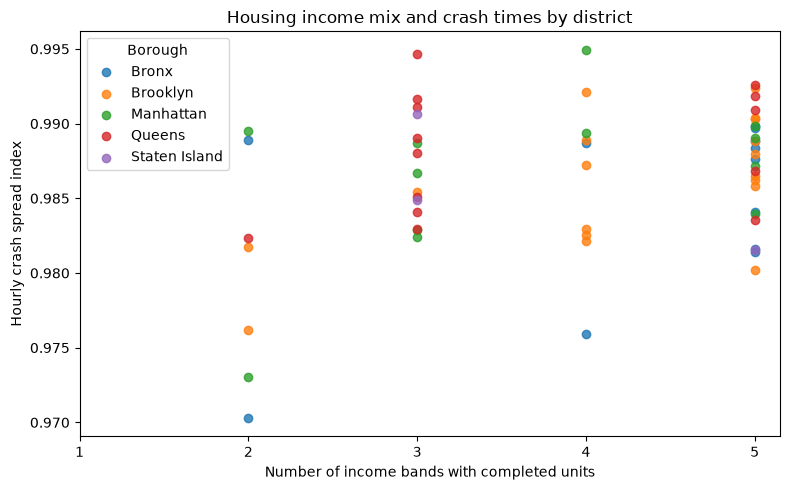

,cd,borough,income_categories_present,income_mix_index,timed_crashes,crash_time_coverage_pct,hours_with_recorded_crashes,hourly_spread_index
0,101,Manhattan,2,0.5556,67,100.0,20,0.9730
1,102,Manhattan,3,0.5478,124,100.0,24,0.9824
2,103,Manhattan,5,0.9162,167,100.0,24,0.9872
3,104,Manhattan,4,0.8699,207,100.0,24,0.9949
4,105,Manhattan,2,0.1222,227,100.0,24,0.9895
5,106,Manhattan,3,0.7689,155,100.0,24,0.9887
6,107,Manhattan,3,0.7638,161,100.0,23,0.9829
7,108,Manhattan,4,0.8308,171,100.0,24,0.9893
8,109,Manhattan,3,0.1966,116,100.0,24,0.9867
9,110,Manhattan,5,0.9832,142,100.0,24,0.9899


Districts: 59
Spearman correlation: 0.206 (p = 0.118)


In [66]:
# Count the named income bands with completed units in each district.
bands = [
    f"housing_{band}_income_units"
    for band in ("extremely_low", "very_low", "low", "moderate", "middle")
]
unit_cols = bands + ["housing_other_income_units", "housing_affordable_units"]
known_cols = [f"{col}_known_records" for col in unit_cols]
cols = unit_cols + known_cols + [
    "housing_source_records", "crash_events", "time_known_events"
]

income = df[df["year"].between(2022, 2025)].groupby(
    ["cd", "borough"], as_index=False
)[cols].sum(min_count=1)

complete = income[known_cols].eq(income["housing_source_records"], axis=0).all(axis=1)
named_units = income[bands].sum(axis=1)
matches_total = (
    named_units + income["housing_other_income_units"] == income["housing_affordable_units"]
)
income = income[complete & matches_total & (named_units > 0)].copy()
income["income_categories_present"] = income[bands].gt(0).sum(axis=1)

band_shares = income[bands].div(income[bands].sum(axis=1), axis=0)
income["income_mix_index"] = (5 / 4) * (1 - band_shares.pow(2).sum(axis=1))

# Pool crash counts for each hour across the four years.
hourly = pd.DataFrame(shared.hourly)
counts = (
    hourly[hourly["year"].between(2022, 2025)]
    .groupby(["cd", "hour"])["crash_events"].sum()
    .unstack(fill_value=0)
    .reindex(columns=range(24), fill_value=0)
)
counts = counts[counts.sum(axis=1) > 0]
timed = counts.sum(axis=1)
hour_shares = counts.div(timed, axis=0)

spread = pd.DataFrame({
    "timed_crashes": timed,
    "hours_with_recorded_crashes": counts.gt(0).sum(axis=1),
    "hourly_spread_index": (24 / 23) * (1 - hour_shares.pow(2).sum(axis=1)),
})

income = income.merge(spread, on="cd", validate="one_to_one")
if not income["timed_crashes"].eq(income["time_known_events"]).all():
    raise ValueError("Hourly crash totals do not match the district totals.")

income["crash_time_coverage_pct"] = 100 * income["timed_crashes"] / income["crash_events"]
x = income["income_categories_present"]
y = income["hourly_spread_index"]
rho, p_value = spearmanr(x, y)

fig, ax = plt.subplots(figsize=(8, 5))
for borough, group in income.groupby("borough"):
    ax.scatter(group["income_categories_present"], group["hourly_spread_index"],
               label=borough, alpha=0.8)

ax.set(
    xlabel="Number of income bands with completed units",
    ylabel="Hourly crash spread index",
    title="Housing income mix and crash times by district",
)
ax.set_xticks(range(1, 6))
ax.legend(title="Borough")
fig.tight_layout()

income.to_csv(OUTPUT_ROOT / "data" / "Q2_income_mix_and_hourly_spread.csv", index=False)
fig.savefig(OUTPUT_ROOT / "data" / "Q2_income_mix_and_hourly_spread.png", dpi=150)
plt.show()

display(income[[
    "cd", "borough", "income_categories_present", "income_mix_index",
    "timed_crashes", "crash_time_coverage_pct",
    "hours_with_recorded_crashes", "hourly_spread_index",
]].round(4))
print(f"Districts: {len(income)}")
print(f"Spearman correlation: {rho:.3f} (p = {p_value:.3f})")

**Findings:**

Districts with more income bands tended to have slightly higher crash spread scores, but the pattern was weak. The Spearman correlation was 0.206 across 59 districts (p = 0.118, not statistically significant). The scores ranged from 0.970 to 0.995, so even the districts at the lower end had crashes spread fairly evenly across the day.

**Limitations.** The number of income bands is a coarse measure (1 to 5), and districts with more completed units have more chances to include more bands. The spread scores fall in a narrow range (0.970 to 0.995), so small score differences are hard to interpret, and a correlation of 0.21 across 59 districts is weak. Only crashes with a recorded time are included. The result is an association, not evidence that income mix affects when crashes happen.

**So what for NYC.** Serious crashes are spread across the whole day in every district, whatever the income mix of its new housing. Street-safety measures need to cover evening and night hours as well as commuting peaks, and income mix should not be used to decide when they run.

### 7.10 Data story: what the questions show together

**The question.** Do districts with a surge in new affordable housing also have more severe street-safety problems? The cell below runs one citywide check on the integrated table: for each of the 59 community districts, the affordable units completed in 2022-2025 against the serious crash events in the same years. The website's default report shows the same comparison.

In [67]:
# Section 7.10: one citywide check of the overall research question.
# One point per community district: affordable units completed 2022-2025 vs serious crash events.
import numpy as np
import pandas as pd

story_table = pd.DataFrame(shared.integrated)
story_table = story_table[story_table["year"].between(2022, 2025)]
district_summary = (story_table.groupby("cd", as_index=False)
                    [["housing_affordable_units", "crash_events"]].sum())


def spearman_permutation(x, y, permutations=2000, seed=11):
    """Spearman rank correlation with a two-sided permutation p-value.

    The ranks of y are shuffled 2,000 times; p is the share of shuffles whose
    correlation is at least as strong as the observed one. Same test as the website.
    """
    rx, ry = x.rank().to_numpy(), y.rank().to_numpy()
    rho = float(np.corrcoef(rx, ry)[0, 1])
    rng = np.random.default_rng(seed)
    shuffled = np.array([np.corrcoef(rx, rng.permutation(ry))[0, 1] for _ in range(permutations)])
    p = float((np.sum(np.abs(shuffled) >= abs(rho) - 1e-12) + 1) / (permutations + 1))
    return rho, p


rho, p_value = spearman_permutation(district_summary["housing_affordable_units"],
                                    district_summary["crash_events"])
print("Community districts:", len(district_summary))
print("Affordable units completed 2022-2025:", int(district_summary["housing_affordable_units"].sum()))
print("Serious crash events 2022-2025:", int(district_summary["crash_events"].sum()))
print(f"Spearman rho = {rho:.3f}, permutation p = {p_value:.3f}")

Community districts: 59
Affordable units completed 2022-2025: 48026
Serious crash events 2022-2025: 9458
Spearman rho = 0.248, permutation p = 0.060


**The answer: only a weak link, and not the one the question expects.**

- **Discovery.** Across the 59 districts the rank correlation between new affordable units and serious crashes is 0.25 (p ≈ 0.06). Districts with more new affordable housing have slightly more serious crashes, but the link is weak and partly reflects size: larger districts have more of both. Where housing grew fastest, the district's share of serious injuries did not rise (7.7, rho = -0.26). The deepest-affordability units are not concentrated in the districts with the most serious injuries (7.8 A). Building size, affordable share, programme type, tenure and income mix show weak or no association with how many crashes happen or when (7.5, 7.6, 7.8 B, 7.9).
- **Surprise.** The two districts with the most serious injuries, QN 07 (324) and BK 18 (317), received only 53 and 61 income-tiered affordable units in four years (7.8 A). The highest-injury districts are not where affordable housing is being built. Housing and crashes also follow different calendars: completions peak in December, crashes in July (7.4).
- **Where both are high.** 17 districts combine above-median new housing with above-median serious injuries, led by BK 01, BX 01, BK 05, QN 12, BX 04 and MN 04 (7.7).
- **Limits.** Every result is an association at district level, not a cause. Counts are not adjusted for population, traffic or road length. Fatal crashes after 2022 cannot be placed in a district, so serious injuries are used instead. A completion date is not a move-in date, and SIRTA covers serious crashes only.
- **Impact.**
  - *DOT and Vision Zero:* prioritise street redesign by crash history, not by housing volume. The highest-crash districts receive little new housing, so they would be missed by a housing-led approach.
  - *HPD and DOT together:* the 17 high-housing, high-injury districts are where scheduled completions and street-safety reviews should be coordinated.
  - *Housing planners and advocates:* the data does not show that new affordable housing, of any type or income tier, brings more serious crashes.

## 8. Contributions and prompts used

### 8.1 Individual research questions

| Section | Member | ID | Research questions | Visualizations |
|---|---|---|---|---|
| 7.4 | Yassin Amr Hegazy | 16001061 | Do housing completions and serious crashes peak in the same month? Does the difference in peak months vary by borough? | Peak-month gap bars; monthly borough panels |
| 7.5 | Mohammed Fady Rizk | 16008623 | Geographic distribution of affordable housing vs serious crashes; average affordable units per building vs crash frequency | Grouped bar chart; scatter plot with trend line |
| 7.6 | Sam Shady Samih Soliman Bostawros | 16004357 | Affordable share of units vs crash frequency; New Construction vs Preservation areas and crash frequency | Scatter plot; box plot |
| 7.7 | Marawan Mohamed Elgendy | 16001322 | Housing growth vs change in serious injuries; districts combining high housing volume with high serious-injury counts | Trend scatter; quadrant bubble chart |
| 7.8 | Amro Taha Salih | 16007093 | Deepest-affordability units vs district crash burden; family-sized units vs school-travel-time crashes | Concentration curves; hour-of-day profiles |
| 7.9 | Fares Mustafa El-Sonbaty | 16006173 | Rental vs homeownership units in districts with recurring crash problems; income-band mix vs spread of crashes across the day | Rental vs homeownership share scatter; income bands vs crash-spread scatter |

### 8.2 Shared project components

All six members worked together on the shared parts of the project: dataset selection and EDA (Sections 1-3), pre-integration cleaning (Sections 4-5), integration and post-integration cleaning (Sections 6-7.3), the integrated-table validation, the data story (7.10), the website (data preparation, search, filters, charts and layout), the README, the GitHub repository and the deployment.

### 8.3 Prompts used

**Data preparation (Sections 1-7.3)**
- Analyze the team's existing notebook and the project requirements.
- Correct the existing work while preserving its sectioning and style.
- Load the complete datasets and examine all rows, columns and cells; plan before cleaning and integration and explain every action.
- Follow every requirement in the Data Engineering project description.
- Put all cleaning and integration code directly in the notebook rather than in external Python modules.
- Use the official Community District boundaries to place records that have coordinates but no reported district, and leave a record unassigned when the evidence is unclear.
- Split the cleaning and integration into small steps, each with a short note on what it does and why.

**Section 7.4**
- "Using the cleaned housing and SIRTA detail tables in this notebook (2022-2025 only), find the calendar month in which housing completions peak and the month in which serious crashes peak, citywide and for each borough. Show the gap in months as a horizontal bar chart with the actual peak months written next to each bar. Use matplotlib only and do not change any cleaning code."
- "Add a second chart: for each borough, the share of its completed units and of its serious crashes that fall in each calendar month, as small multiples on the same y-axis so the two seasonal patterns can be compared directly."
- "Write the findings, limitations and a 'so what' for NYC using only the printed numbers. Point out where a peak month rests on very small differences, and avoid any causal wording."

**Section 7.5**
- "Aggregate the integrated district-year table to borough level for 2022-2025 and convert affordable units and serious crash events into each borough's percentage of the city total. Plot both as a grouped bar chart with the percentages labelled."
- "For the second question, keep only district-years where every housing record has a building ID and a known affordable-unit count, compute affordable units per building, and plot it against crash events with a linear trend line and Pearson r. Report how many district-years pass the filter and which boroughs drop out."
- "Write up both results from the outputs and flag any single point that has a large influence on the trend line."

**Section 7.6**
- "Using the existing column `housing_affordable_share_of_reported_total`, plot the affordable share against serious crash events for district-years that have completions. Report Pearson r and the range and median of the share, so it is clear whether there is enough variation to test."
- "From the housing programme activity summary, label each district-year as New Construction or Preservation depending on which has more source records, join it to the crash totals, and draw a box plot of the two groups. Print the group sizes, medians, means and quartiles."
- "Write the findings, limitations and 'so what' for both questions. Note that programme activity uses project start dates, not completion dates."

**Section 7.7**
- "Before analysing, check the integrated table: 236 rows, 59 districts × 4 years, unique keys, non-negative counts and nulls only where expected. Then check whether fatalities and serious injuries can still be placed in a district in every year."
- "Question 1: compare each district's new units in 2022-23 and 2024-25 with the change in its share of citywide serious injuries. Use Spearman's correlation, a Theil-Sen line and a check for regression to the mean. Write the chart as a function that takes a filtered dataframe so it can be reused in the Dash website."
- "Question 2: build a quadrant bubble chart of total new units (log scale) against total serious injuries per district, split at the citywide medians, and rank the districts that are high on both. Write the method, limitations and 'so what' only after the code has run on the full data, with no causal claims."

**Section 7.8**
- "My part of the project is two research questions with one visualization each, built on the integrated HPD/SIRTA table. These questions are already taken by the team: peak months (7.4), borough shares and building size (7.5), affordable share and programme type (7.6), housing growth and high-housing/high-crash districts (7.7). Propose two that use information nobody else is using, such as the income bands, the bedroom sizes or the crash times. For each, give the exact metric, the chart type and what result would count as a yes or a no. Don't write any code yet."
- "My questions were replaced with two others: (1) do areas with completed affordable housing record different crash frequencies from areas without, and (2) how consistently are completions and crashes recorded across districts over time? Compare them with my original pair (deepest-affordability units vs district crash burden, and family-sized units vs school-travel-time crashes) on originality, on whether our data can actually answer them, and on overlap with the other members' questions. Keep the stronger pair and explain the choice."
- "Implement the chosen pair. Reconcile the detail rows with the integrated table first. Use concentration curves and a bootstrap over projects for question A, and hour-of-day profiles with a weekend/summer comparison and sensitivity checks for question B. Write the findings only from the printed outputs."

**Section 7.9**
- "For districts with at least one crash that has a positive three-year lookback, compare each district's share of the city's rental affordable units with its share of homeownership units (2022-2025), with each tenure type measured against its own total. Make a scatter plot and name the districts that stand out most."
- "Count how many of the five named income bands have completed units in each district, keeping Other Income separate. Measure how evenly each district's timed crashes are spread over the 24 hours with a 0-1 score. Plot the two against each other by borough, give the Spearman correlation, and stop with an error if the hourly totals do not match the district totals."

**Combining the notebooks and reviewing the findings**
- "Merge the six members' notebooks into one. Keep a single copy of the shared cleaning and integration code, give each member's questions their own numbered section (7.4-7.9), and run it from the top to confirm nothing breaks."
- "Add written findings under every chart, then check all twelve questions for wrong numbers, causal language and missing limitations."

**Data story, website, README and deployment (Sections 7.10 and 9)**
- "Build a Dash website on the notebook's exported tables. It needs borough, year, district, housing-measure, crash-measure and time-of-day dropdowns, a search box that sets those filters, and a Generate Report button that updates every chart. Include a map, a housing-vs-crashes scatter, yearly trends, an hour heatmap and a short story tab, plus tests that check the site's totals against the notebook."
- "Write the README with setup and Render deployment steps, then check the notebook again against every point of the project description."

## 9. Interactive website

**Repository:** https://github.com/mohammedrizk16008623/DEVPROJ1
**Live site:** [deployment link]

The website (Python, Dash and Plotly) reads two tables this notebook exports: `data/integrated_district_year.csv` (236 district-years) and `data/crashes_district_year_hour.csv`. It does no cleaning of its own, so every number on the site matches this notebook. `scripts/prepare_data.py` copies those files and simplifies the district boundaries for the map.

**Features**
- **Search bar.** Free text such as *"Brooklyn 2022 new buildings"*, *"BX 01 family units injuries"* or *"Queens evening crashes"*. The search sets the filters, and shows what it understood and which words it did not recognise.
- **Filters in one row:**
  - borough and year;
  - community district (the list narrows to the chosen boroughs);
  - housing measure: affordable units, all units, buildings, income band, family-sized, rental or homeownership;
  - crash measure: serious crashes, serious injuries, other injuries or repeat-location crashes;
  - time of day.
- **Generate Report button.** Charts update only when it is pressed. A notice appears when the filters have changed since the last report.
- **Report:**
  - four headline numbers, including the rank correlation and its p-value;
  - a written summary;
  - a map (district shade = crashes, circle = housing);
  - a district scatter with medians;
  - the 15 districts with the most crashes;
  - year-by-year trends per borough (two panels, no dual axis);
  - an hour-by-borough heatmap and a table view.
- **Other tabs:**
  - *Data story*: question, data, findings, limits and recommendation.
  - *Team questions*: all twelve individual questions, each with a one-line answer.
  - *About the data*: dataset links and definitions.

**Design choices**
- Fatalities are not offered on the site, because fatal records after 2022 cannot be placed in a district (Section 7.7).
- Every chart that compares the two datasets says that it shows association, not cause.
- Borough colours stay fixed when filters change, and crashes always use one blue scale.

**Deployment:** Vercel. `api/index.py` exposes the site's server as `app`, and `vercel.json` sends every request to it. In Vercel, import the repository with Framework Preset *Other*; Python 3.12 is read from `.python-version` and the packages from `requirements.txt`.

**Tests:** `python -m pytest` checks that the site's totals match this notebook (48,026 affordable units, 9,458 serious crashes, rho = 0.248). It also tests the search parser and builds every chart for several filter combinations.